In [1]:
from itertools import islice
import os
from tqdm import tqdm

import numpy as np
# import cupy as cp
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.gridspec import GridSpec
from matplotlib.widgets import Slider
from matplotlib.ticker import ScalarFormatter

from scipy.signal import butter, filtfilt, freqz
from scipy.signal import find_peaks
from scipy.signal import savgol_filter
from scipy.ndimage import median_filter
from scipy.optimize import differential_evolution

In [2]:
np.set_printoptions(suppress=True, precision=8)

In [3]:
from IPython import get_ipython

def set_widget_backend():
    plt.close('all')
    get_ipython().run_line_magic('matplotlib', 'widget')

def set_inline_backend():
    plt.close('all')
    get_ipython().run_line_magic('matplotlib', 'inline')

In [4]:
# Чтение данных

# ==============================================================================

def read_data(file_path: str, max_rows: int | None = None) -> np.ndarray:
    return pd.read_csv(
        file_path, header=None, sep='|', decimal=',',
        nrows=max_rows, engine='c', usecols=[0]
    ).to_numpy(dtype=np.float64).ravel()

# ==============================================================================
def count_rows(file_path: str) -> int:
    if os.path.getsize(file_path) == 0:
        return 0
    
    n = 0
    with open(file_path, 'rb') as f:
        while chunk := f.read(1 << 20):
            n += chunk.count(b'\n')

    return n + (chunk[-1:] != b'\n')

# ==============================================================================

def read_data_writable(path: str, max_rows: int | None = None, n_chunk_rows: int = 10000) -> np.ndarray:
    if max_rows is None:
        max_rows = count_rows(path)
    arr = np.empty(max_rows, dtype=np.float64)

    idx = 0
    for df in pd.read_csv(path, chunksize=n_chunk_rows, nrows=max_rows, header=None, decimal=',', engine='c', usecols=[0]):
        chunk = df.iloc[:, 0].to_numpy()
        arr[idx:idx+len(chunk)] = chunk
        idx += len(chunk)
    
    return arr

In [5]:
#  Визуализация сигналов

def plot_signal(ax, t, y, color="C0", label="", xlabel="", ylabel="", title=""):
    ax.plot(t, y, color=color, label=label)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.grid(True, linestyle='--', alpha=0.3)

def plot_curve(ax, x, y, color="C0", label="", xlabel="", ylabel="", title=""):
    ax.plot(x, y, color=color, label=label)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.grid(True, linestyle='--', alpha=0.5)

def plot_bounding_lines(ax, y, color="C1", legend=False, legend_prefix="", legend_unit_scale=1.0):
    y_min, y_max = y.min(), y.max()
    ax.axhline(y_min, color=color, ls="--", lw=0.8, label=f"${legend_prefix}_{{min}}={y_min * legend_unit_scale:.3f}$")
    ax.axhline(y_max, color=color, ls="--", lw=0.8, label=f"${legend_prefix}_{{max}}={y_max * legend_unit_scale:.3f}$")
    if legend:
        ax.legend(loc="upper right", fontsize="medium")

def plot_segments(ax, x, y, segment_indices, segments_per_peroid=1):
    for i in range(len(segment_indices) - 1):
        start = segment_indices[i]
        end = segment_indices[i + 1]

        if segments_per_peroid == 1:
            color = f'C{i}'
        else:
            color = f'C{i % segments_per_peroid}'
        
        seg_x = x[start : end]
        seg_y = y[start : end]
        
        ax.plot(seg_x, seg_y, color=color)

In [6]:
# Извлечение мемристивного тока

def extract_schottky_current(V, a_f, a_r, b_f, b_r):
    return a_f * np.exp(b_f * V) - a_r * np.exp(-b_r * V)

def extract_memristive_current(I, phi, I_s):
    return (I - (1 - phi) * I_s) / phi

In [7]:
# вспомогательные функции

def find_zeros(signal: np.ndarray) -> np.ndarray:
    crosses = signal[:-1] * signal[1:] <= 0
    if not np.any(crosses):
        return np.array([], dtype=int)

    idxs = np.where(crosses)[0]
    abs_s = np.abs(signal)
    chosen = np.where(abs_s[idxs] <= abs_s[idxs + 1], idxs, idxs + 1)
    mask = np.concatenate(([True], chosen[1:] != chosen[:-1]))
    return chosen[mask]

def find_extrema_and_zeros(signal: np.ndarray) -> tuple:
    n = len(signal)
    if n < 2:
        return np.empty(0, np.int64), np.empty(0, np.int64), np.empty(0, np.int64)

    peaks = np.empty(n, np.int64)
    valleys = np.empty(n, np.int64)
    zeros = np.empty(n, np.int64)
    p, v, z = 0, 0, 0

    for i in range(n - 1):
        a, b = signal[i], signal[i + 1]
        if a * b <= 0:
            idx = i if abs(a) <= abs(b) else i + 1
            if z == 0 or zeros[z - 1] != idx:
                zeros[z] = idx
                z += 1

        if 0 < i < n - 1:
            curr = signal[i]
            if curr > signal[i - 1] and curr > b:
                peaks[p] = i
                p += 1
            elif curr < signal[i - 1] and curr < b:
                valleys[v] = i
                v += 1

    return zeros[:z], peaks[:p], valleys[:v]

In [8]:
def calculate_R(V, I):
    R = np.empty_like(V)
    np.divide(V, I, out=R, where=(I != 0))
    R[I == 0] = np.inf
    return R

def calculate_G(V, I):
    G = np.empty_like(V)
    np.divide(I, V, out=G, where=(V != 0))
    G[V == 0] = np.inf
    return G

def build_time_array(start, end, dt, endpoint=True):
    n = int(np.round((end - start) / dt)) + (1 if endpoint else 0)
    return np.linspace(start, end, n, endpoint=endpoint)

In [9]:
def get_num_periods(zero_indices, segments_per_period=2):
    if len(zero_indices) == 0:
        return 0
    if (len(zero_indices) + segments_per_period) % 2 == 0:
        return 1 + (len(zero_indices) - 1) // segments_per_period
    else:
        return (len(zero_indices) - 1) // segments_per_period

In [10]:
# Форматирование меток на графиках

# отображение графиков в мА / мС / кОм без аллокации нового массива
formatter_to_mA  = FuncFormatter(lambda y, _: f'{y*1000:.3f}')
formatter_to_mS  = FuncFormatter(lambda y, _: f'{y*1000:.3f}')
formatter_to_mV  = FuncFormatter(lambda y, _: f'{y*1000:.3f}')
formatter_to_mSm = FuncFormatter(lambda y, _: f'{y*1000:.3f}')
formatter_to_kOm = FuncFormatter(lambda y, _: f'{y/1000:.3f}')

# Форматирование меток на оси Y в научной нотации
def set_scientific_yaxis(ax, scilimits=(0, 1)):
    fmt = ScalarFormatter(useMathText=True)
    fmt.set_powerlimits(scilimits)
    ax.yaxis.set_major_formatter(fmt)

def set_scientific_xaxis(ax, scilimits=(0, 1)):
    fmt = ScalarFormatter(useMathText=True)
    fmt.set_powerlimits(scilimits)
    ax.xaxis.set_major_formatter(fmt)

# Анализ и разработка алгоритмов

## Чтение данных

In [11]:
ROOT_DIR = "C:/Dev/Data/University/VKR/Датасеты_мемристоров_ННГУ/Временные ряды для ЛЭТИ 2023_06_07"

PATH_TO_IN = os.path.join(ROOT_DIR, "Input Voltage Pila -1.1_1.5V_full.txt")
PATH_TO_OUT = os.path.join(ROOT_DIR, "Output Voltage Pila-1.1+1.5V_1e6_1e6_1kOhm_1.txt")

dt = 1e-6   # time step 
R = 1000    # resistance

In [12]:
# считаем ~100 циклов ВАХ-ки
N_cycles = 100
max_rows = 5200 * (N_cycles + 1)

arr_v = read_data(PATH_TO_IN, max_rows=max_rows)
arr_i = read_data_writable(PATH_TO_OUT, max_rows=max_rows, n_chunk_rows=100_000)
arr_i /= R

print(f"Input length: {len(arr_v)}")
print(f"Output length: {len(arr_i)}")

Input length: 525200
Output length: 525200


In [13]:
N = len(arr_v)
print(f"Time range (seconds): [0; {(N - 1) * dt}]")

Time range (seconds): [0; 0.525199]


In [14]:
arr_v_zeros = find_zeros(arr_v)
print(f"Нулей по напряжению: {len(arr_v_zeros)}")

Нулей по напряжению: 202


## Temp

In [27]:
from scipy.ndimage import uniform_filter1d

In [68]:
def find_zeros_smoothed(
    signal: np.ndarray,
    *,
    window: int,
    min_distance: int = 1,
    smooth_mode: str = "mirror",
) -> np.ndarray:
    signal = np.asarray(signal)

    if signal.ndim != 1:
        raise ValueError("signal must be 1-dimensional")
    if window < 1:
        raise ValueError("window must be positive")
    if window % 2 == 0:
        raise ValueError("window must be odd")
    if min_distance < 1:
        raise ValueError("min_distance must be positive")

    n = signal.size
    if n == 0:
        return np.array([], dtype=int)

    if n == 1:
        return np.array([0], dtype=int) if signal[0] == 0 else np.array([], dtype=int)

    smoothed = uniform_filter1d(
        signal,
        size=window,
        mode=smooth_mode,
    )

    left = smoothed[:-1]
    right = smoothed[1:]

    crosses = (
        (left == 0)
        | (right == 0)
        | ((left < 0) & (right > 0))
        | ((left > 0) & (right < 0))
    )

    if np.any(crosses):
        cross_pos = np.flatnonzero(crosses)

        left_abs = np.abs(left[cross_pos])
        right_abs = np.abs(right[cross_pos])

        chosen = cross_pos + (right_abs < left_abs)
    else:
        chosen = np.array([], dtype=int)

    last_idx = n - 1

    if signal[0] == 0 and (chosen.size == 0 or chosen[0] != 0):
        chosen = np.insert(chosen, 0, 0)

    if signal[-1] == 0 and (chosen.size == 0 or chosen[-1] != last_idx):
        chosen = np.append(chosen, last_idx)

    if min_distance > 1 and chosen.size > 1:
        keep = np.concatenate((
            [True],
            np.diff(chosen) >= min_distance,
        ))
        chosen = chosen[keep]

    return chosen.astype(int)



def find_zeros_smoothed_chunked(
    signal: np.ndarray,
    *,
    window: int,
    chunk_size: int = 1_000_000,
    min_distance: int = 1,
    smooth_mode: str = "mirror",
) -> np.ndarray:
    signal = np.asarray(signal)

    if signal.ndim != 1:
        raise ValueError("signal must be 1-dimensional")

    if chunk_size < 2:
        raise ValueError("chunk_size must be at least 2")

    n = signal.size
    if n < 2:
        return np.array([], dtype=int)

    half = window // 2
    result: list[np.ndarray] = []

    last_idx = None

    for start in range(0, n, chunk_size):
        stop = min(start + chunk_size, n)

        ext_start = max(0, start - half)
        ext_stop = min(n, stop + half)

        local = find_zeros_smoothed(
            signal[ext_start:ext_stop],
            window=window,
            min_distance=min_distance,
            smooth_mode=smooth_mode,
        )

        if local.size == 0:
            continue

        global_idx = local + ext_start

        # оставляем только индексы текущего чанка
        mask = (global_idx >= start) & (global_idx < stop)
        global_idx = global_idx[mask]

        if global_idx.size == 0:
            continue

        # защита от дублей между чанками
        if last_idx is not None:
            global_idx = global_idx[global_idx - last_idx >= min_distance]

        if global_idx.size:
            last_idx = global_idx[-1]
            result.append(global_idx)

    if not result:
        return np.array([], dtype=int)

    return np.concatenate(result).astype(int)

In [82]:
zero_idxs = find_zeros_smoothed_chunked(
    arr_v,
    window=101,
    chunk_size=500_000,
    min_distance=200,
    smooth_mode='wrap'
)

In [70]:
def get_num_periods(zero_indices, segments_per_period=2):
    if len(zero_indices) == 0:
        return 0
    if (len(zero_indices) + segments_per_period) % 2 == 0:
        return 1 + (len(zero_indices) - 1) // segments_per_period
    else:
        return (len(zero_indices) - 1) // segments_per_period

In [83]:
zero_idxs[:10]

array([   0, 3001])

In [89]:
arr_v[-10:]

array([-0.004563, -0.005173, -0.002563, -0.000919, -0.007005, -0.005039,
       -0.002911, -0.00014 , -0.002039,  0.00186 ])

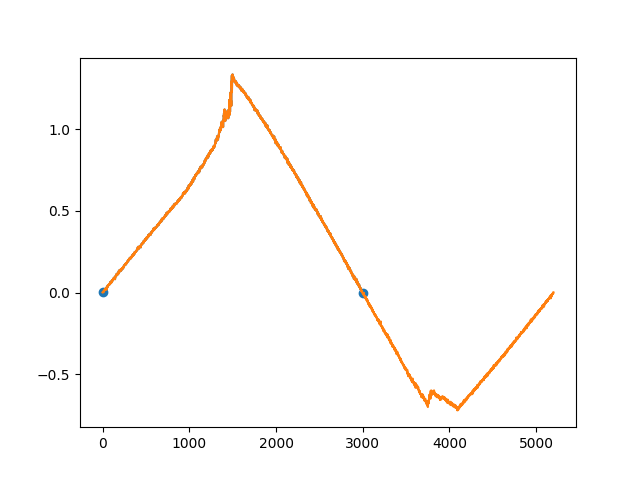

In [88]:
plt.plot(np.arange(len(arr_v)), arr_v)
plt.show()

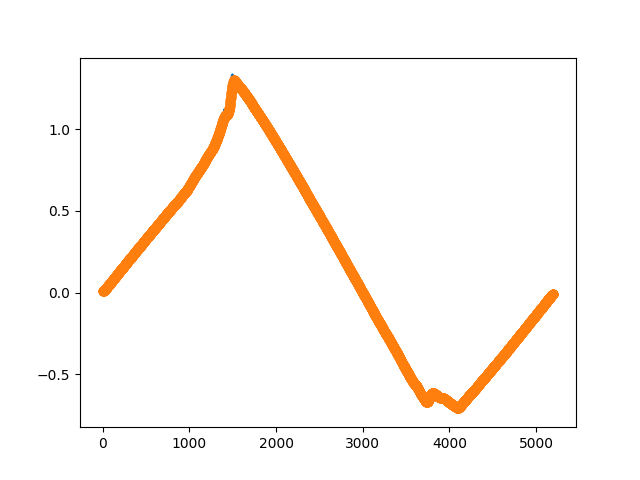

In [97]:
set_widget_backend()

V = arr_v
V_smooth = uniform_filter1d(V, size=51, mode='mirror')

plt.plot(np.arange(len(V)), V)
plt.plot(np.arange(len(V)), V_smooth, marker='o')
plt.show()

In [ ]:
min_dist = 

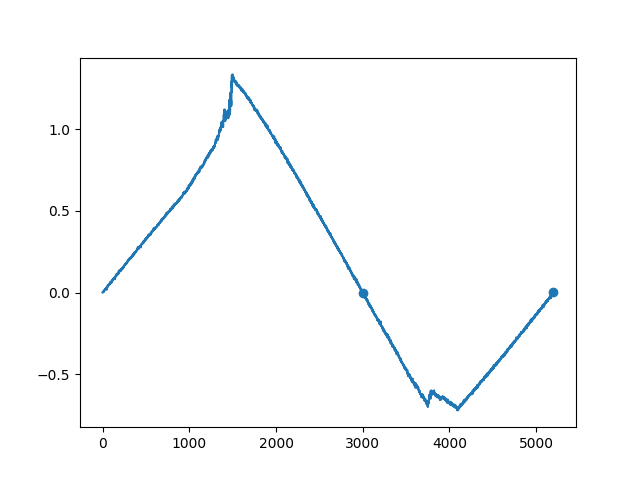

In [143]:
set_widget_backend()
n_zeros = 2


V = arr_v[: zero_idxs[n_zeros - 1] + 1]
V_zeros = zero_idxs[:n_zeros]

V_smooth = uniform_filter1d(V, size=100, mode='wrap')

plt.plot(np.arange(len(V)), V)
# plt.plot(np.arange(len(V)), V_smooth)
plt.scatter(np.arange(len(V))[V_zeros], V[V_zeros])
plt.show()

In [33]:
zero_idxs[:10]

array([ 3050,  5250,  8250, 10450, 13450, 15650, 18650, 20850, 23850,
       26050])

In [32]:
zero_idxs = find_zeros_smoothed(
    arr_v,
    window=101,
    chunk_size=500_000,
    min_distance=200,
)

get_num_periods(zero_idxs, segments_per_period=2)

10000

In [133]:
def estimate_frequency_fft(
    signal: np.ndarray,
    dt: float,
    min_rel_amp: float = 0.3,
) -> float:
    if signal.ndim != 1:
        raise ValueError("signal must be 1-dimensional")
    if signal.size < 2:
        raise ValueError("signal must contain at least 2 points")
    if dt <= 0:
        raise ValueError("dt must be positive")
    if not (0 < min_rel_amp <= 1):
        raise ValueError("min_rel_amp must be in range (0, 1]")

    signal_mean = np.mean(signal)

    spectrum = np.fft.rfft(signal - signal_mean)
    amplitudes = np.abs(spectrum)

    amplitudes[0] = 0.0

    max_amp = np.max(amplitudes)
    if max_amp == 0:
        raise ValueError("cannot estimate frequency of a constant signal")

    strong = amplitudes >= min_rel_amp * max_amp

    idxs = np.flatnonzero(strong)
    if idxs.size == 0:
        raise ValueError("no significant frequency component found")

    idx = idxs[0]

    return float(idx / (signal.size * dt))
    # freqs = np.fft.rfftfreq(signal.size, d=dt)
    # return float(freqs[idx])

In [12]:

def find_zeros(signal: np.ndarray) -> np.ndarray:
    signal = np.asarray(signal)

    if signal.ndim != 1:
        raise ValueError("signal must be 1-dimensional")

    if signal.size < 2:
        return np.array([], dtype=int)

    left = signal[:-1]
    right = signal[1:]

    crosses = (
        (left == 0)
        | (right == 0)
        | ((left < 0) & (right > 0))
        | ((left > 0) & (right < 0))
    )

    if not np.any(crosses):
        return np.array([], dtype=int)

    idxs = np.flatnonzero(crosses)

    chosen = np.where(
        np.abs(left[idxs]) <= np.abs(right[idxs]),
        idxs,
        idxs + 1,
    )

    mask = np.concatenate(([True], chosen[1:] != chosen[:-1]))

    return chosen[mask].astype(int)


def filter_zero_candidates(
    zero_idxs: np.ndarray,
    min_distance: int,
) -> np.ndarray:
    zero_idxs = np.asarray(zero_idxs, dtype=int)

    if min_distance < 1:
        raise ValueError("min_distance must be positive")

    if zero_idxs.size == 0:
        return np.array([], dtype=int)

    groups = np.split(
        zero_idxs,
        np.flatnonzero(np.diff(zero_idxs) >= min_distance) + 1,
    )

    result = [
        group[(group.size - 1) // 2]
        for group in groups
    ]

    return np.array(result, dtype=int)


def find_stable_zeros(
    signal: np.ndarray,
    *,
    min_distance: int,
) -> np.ndarray:
    zero_idxs = find_zeros(signal)

    return filter_zero_candidates(
        zero_idxs,
        min_distance=min_distance,
    )

In [15]:
zero_idxs = find_stable_zeros(
    arr_v,
    min_distance=5200 / 6
)

In [16]:
zero_idxs[:10]

array([    0,  3000,  5200,  8200, 10400, 13400, 15600, 18600, 20800,
       23800])

In [ ]:



V = arr_v[:1_000_000]
freq = estimate_frequency_fft(V, dt)
period_s = 1 / freq
period_samples = round(period_s / dt)
print(freq, period_s, period_samples)

192.30769230769232 0.0052 5200


In [13]:
def find_extrema(
    signal: np.ndarray,
    *,
    smooth: bool = True,
    smooth_window: int | None = None,
    smooth_mode: str = "mirror",
) -> tuple[int, int]:
    signal = np.asarray(signal)
    smooth_window = (smooth_window) if (smooth_window % 2 != 0) else (smooth_window + 1)
    smooth_window = min(5, max(smooth_window, signal.size))

    if signal.size == 0:
        raise ValueError("signal must not be empty")
    if not smooth:
        return int(np.argmin(signal)), int(np.argmax(signal))

    smoothed = savgol_filter(signal, window_length=smooth_window, polyorder=3, mode=smooth_mode)

    return int(np.argmin(smoothed)), int(np.argmax(smoothed))

In [22]:
n = 10000

maxima = np.empty(n, dtype=int)
minima = np.empty(n, dtype=int)

for i in range(n):
    start, end = get_period_indices(arr_v, i, zero_idxs, segments_per_period=2, period_start_segment_idx=0)
    V = arr_v[start : end + 1]

    window = int(0.01 * V.size)
    min_idx, max_idx = find_extrema(V, smooth=True, smooth_window=window, smooth_mode='wrap')

    minima[i] = start + min_idx
    maxima[i] = start + max_idx

In [23]:
maxima[:10]

array([ 1500,  6700, 11900, 17100, 22300, 27500, 32700, 37900, 43100,
       48300])

In [202]:
zero_idxs = np.concatenate([[0], zero_idxs])
zero_idxs

array([   0, 2999, 5199])

In [203]:
start, end = zero_idxs[0], zero_idxs[2]
V = arr_v[start : end + 1]
V_zeros = zero_idxs[0:3]

min_idx, max_idx = find_extrema(V, smooth_window=0.01 * 5200)

min_idx, max_idx

(4097, 1506)

In [185]:
V.shape

(5200,)

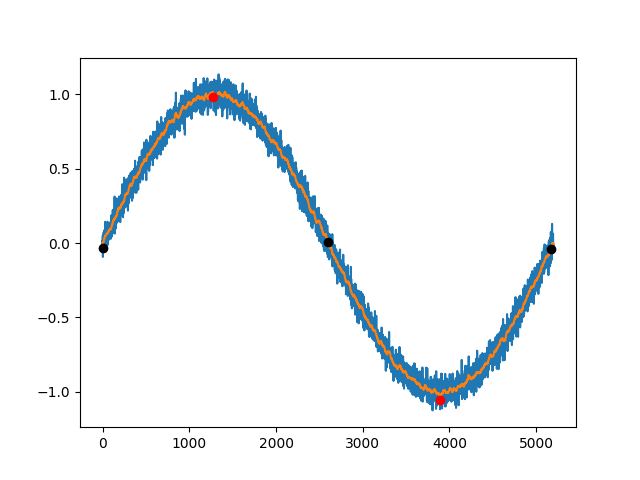

In [221]:
set_widget_backend()

t = np.arange(len(V))

V_smoothed = savgol_filter(V, window_length=51, polyorder=3, mode='mirror')

plt.plot(t, V, zorder=99)
plt.plot(t, V_smoothed, zorder=99)
plt.scatter(t[min_idx], V[min_idx], zorder=100, c='red')
plt.scatter(t[max_idx], V[max_idx], zorder=100, c='red')
plt.scatter(t[zero_idxs], V[zero_idxs], zorder=100, c='black')
plt.show()

In [206]:
def generate_sine_period(
    samples: int = 1000,
    *,
    amplitude: float = 1.0,
    noise_amplitude: float = 0.0,
    phase: float = 0.0,
    seed: int | None = None,
) -> np.ndarray:
    if samples < 2:
        raise ValueError("samples must be at least 2")

    rng = np.random.default_rng(seed)

    x = np.linspace(
        0,
        2 * np.pi,
        samples,
        endpoint=False,
    )

    signal = amplitude * np.sin(x + phase)

    if noise_amplitude > 0:
        signal += noise_amplitude * rng.standard_normal(samples)

    return signal

In [220]:
V = generate_sine_period(
    samples=5200,
    amplitude=1.0,
    noise_amplitude=0.05,
    seed=42,
)

zero_idxs = find_stable_zeros(V, min_distance=5200 / 6)
print(zero_idxs)

min_idx, max_idx = find_extrema(V, smooth_window=0.01 * 5200)
print(min_idx, max_idx)

[   9 2603 5175]
3893 1272


## Сглаживание токового сигнала

### ФНЧ Баттерворта

In [14]:
# Фильтр Баттерворта

def get_filter_coeffs(cutoff, fs, order=4):
    return butter(order, cutoff / (0.5 * fs), btype='low', analog=False)

def apply_filter(data, b, a):
    return filtfilt(b, a, data)

def plot_freq_response(b, a, fs, cutoff, ax_achx, ax_fchx):
    w, h = freqz(b, a, worN=8000, fs=fs)
    achx = 20 * np.log10(np.abs(h) + 1e-12)
    fchx = np.angle(h, deg=True)

    ax_achx.plot(w, achx)
    ax_achx.set_title('АЧХ')
    ax_achx.set_ylabel('Усиление, дБ')
    ax_achx.axvline(cutoff, color='r', linestyle='--', label=f'f_cut={cutoff} Гц')
    ax_achx.legend()
    ax_fchx.plot(w, np.unwrap(fchx))
    ax_fchx.set_title('ФЧХ')
    ax_fchx.set_ylabel('Фаза, град')

    for ax in [ax_achx, ax_fchx]:
        ax.set_xlabel('Частота, Гц')
        ax.grid(True, linestyle='--', alpha=0.5)

In [15]:
# получение спектра
fs = 1 / dt
freqs = np.fft.rfftfreq(N, dt)
spectrum = np.abs(np.fft.rfft(arr_i)) / N

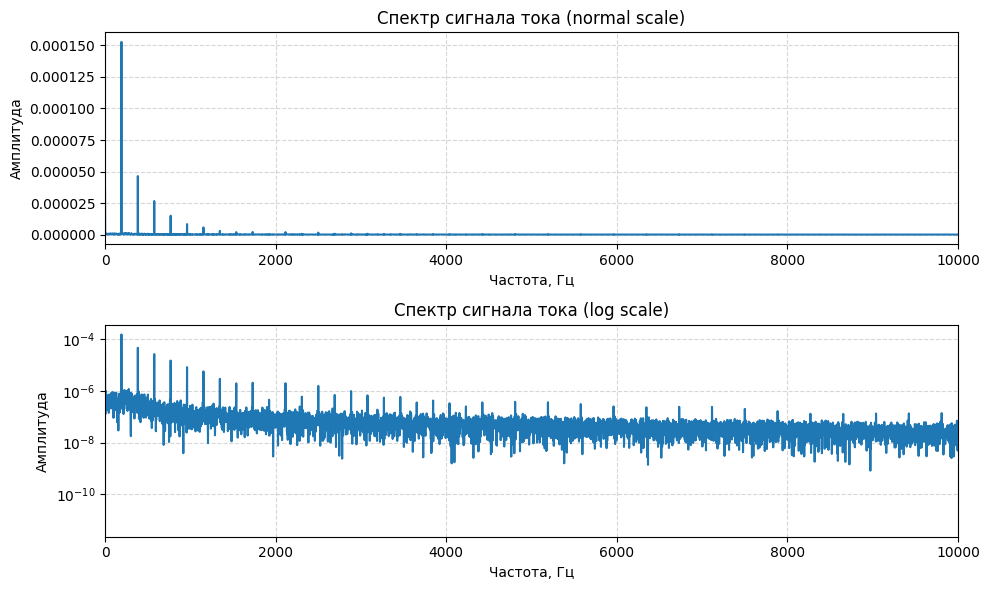

In [16]:
# визуализация спектра
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6))

ax1.plot(freqs, spectrum)
ax1.set_title('Спектр сигнала тока (normal scale)')
ax2.semilogy(freqs, spectrum + 1e-12)
ax2.set_title('Спектр сигнала тока (log scale)')

for ax in [ax1, ax2]:
    ax.set_xlabel('Частота, Гц')
    ax.set_ylabel('Амплитуда')
    ax.set_xlim(0, 10000)
    ax.grid(True, which='both', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Возьмем в качестве частоты среза $f = 5000$ Гц

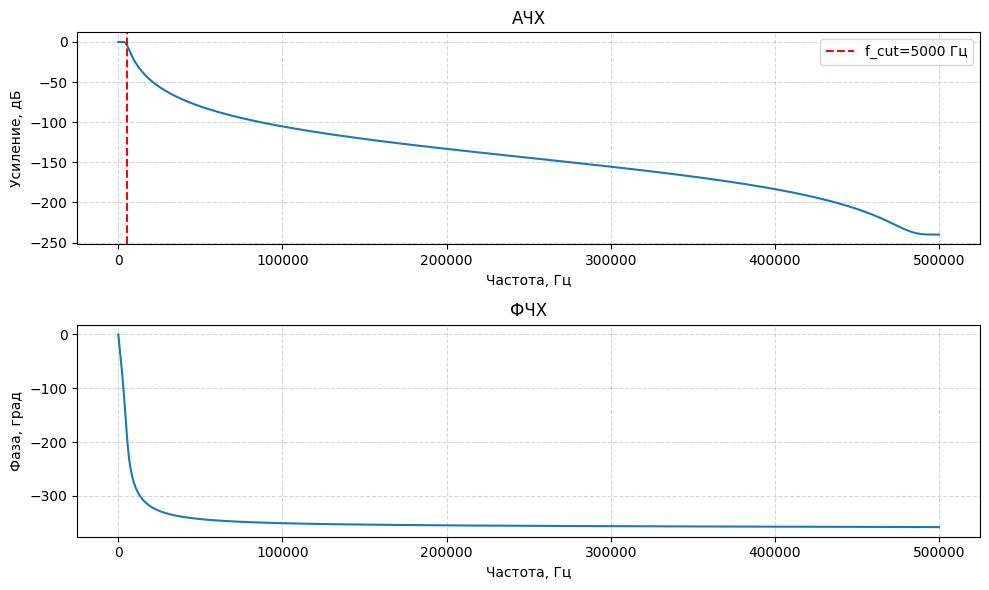

In [17]:
# Построим АЧХ и ФЧХ
fs = 1 / dt
cutoff = 5000
b, a = get_filter_coeffs(5000, fs, order=4)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6))
plot_freq_response(b, a, fs, 5000, ax1, ax2)
plt.tight_layout()
plt.show()

In [18]:
# Фильтрация сигнала
fs = 1 / dt
cutoff = 30000
b, a = get_filter_coeffs(cutoff, fs, order=4)

arr_i_filtered = apply_filter(arr_i, b, a)

NameError: name 'arr_t' is not defined

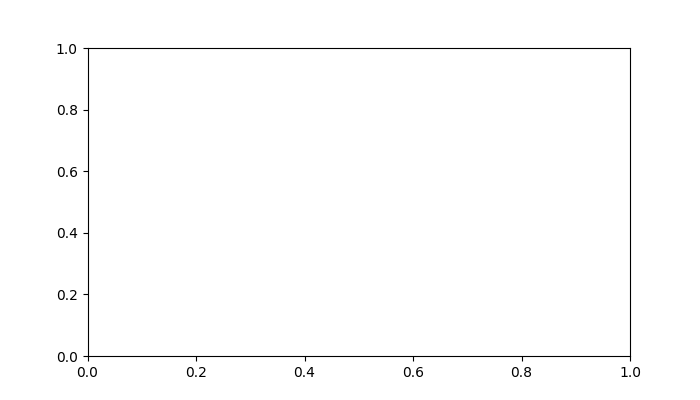

In [19]:
set_widget_backend()

t_end = 0.02
end_index = int(t_end // dt)

# визуализация токового сигнала
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(arr_t[:end_index], arr_i[:end_index], label="raw")
ax.plot(arr_t[:end_index], arr_i_filtered[:end_index], label="filtered")
ax.set_ylabel('I, [А]')
ax.set_xlim(arr_t[0], arr_t[end_index])

ax.set_xlabel("t, [с]")
ax.set_ylabel("I, [мА]")
ax.yaxis.set_major_formatter(formatter_to_mA)

ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Фильтр Савицкого - Голея

In [ ]:
arr_i_filtered = savgol_filter(arr_i, window_length=31, polyorder=3)

NameError: name 'arr_t' is not defined

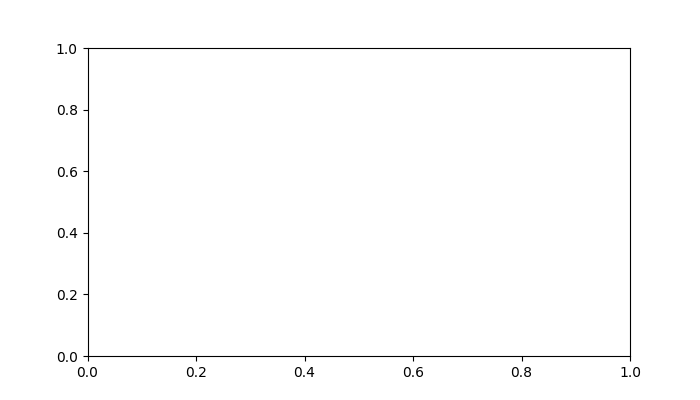

In [20]:
set_widget_backend()

t_end = 0.01
end_index = int(t_end // dt)

# визуализация токового сигнала
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(arr_t[:end_index], arr_i[:end_index], label="raw", alpha=0.5)
ax.plot(arr_t[:end_index], arr_i_filtered[:end_index], label="smoothed")
ax.set_ylabel('I, [А]')
ax.set_xlim(arr_t[0], arr_t[end_index])

ax.set_xlabel("t, [с]")
ax.set_ylabel("I, [мА]")
ax.yaxis.set_major_formatter(formatter_to_mA)

ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Финальный вариант

In [15]:
def filter_current(arr_i, high_smooth=True):
    if high_smooth:
        return savgol_filter(arr_i, window_length=101, polyorder=3)
    else:
        return savgol_filter(arr_i, window_length=31, polyorder=3)

In [22]:
# arr_i_filtered = filter_current(arr_i)

## Краткий обзор

In [23]:
# Получение G(t) со сглаженным током

# arr_g_filtered = np.empty_like(arr_v)
# np.divide(arr_i_filtered, arr_v, out=arr_g_filtered, where=(arr_v != 0))
# arr_g_filtered[arr_v == 0] = np.inf

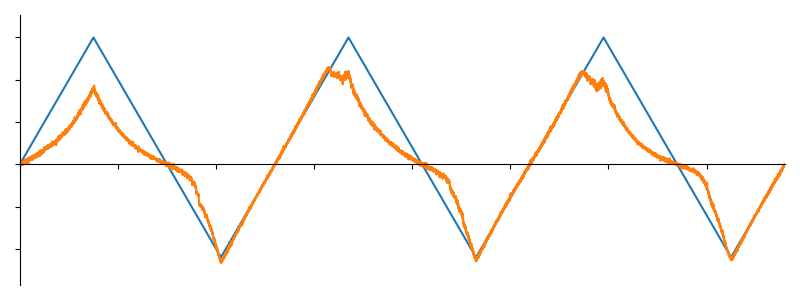

In [24]:
start = 0; end = 5200 * 3 + 1

T = build_time_array(start*dt, end*dt, dt, endpoint=False)
V = arr_v[start : end]
I = arr_i[start : end]
Vout = I * R

T *= 1000
Vout *= 2.5

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(T, V)
ax.plot(T, Vout)

# Сначала задаем лимиты, потом позиционируем оси
ax.set_xlim(T.min(), T.max())
y_min, y_max = min(V.min(), Vout.min()), max(V.max(), Vout.max())
ax.set_ylim(y_min - 0.1*(y_max-y_min), y_max + 0.1*(y_max-y_min))

# Убираем верхнюю и правую границы
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

# Перемещаем нижнюю и левую оси в начало координат (если 0 в диапазоне)
if ax.get_ylim()[0] <= 0 <= ax.get_ylim()[1]:
    ax.spines['bottom'].set_position('zero')
if ax.get_xlim()[0] <= 0 <= ax.get_xlim()[1]:
    ax.spines['left'].set_position('zero')

# Сдвигаем подписи осей в начало координат
ax.xaxis.set_label_coords(1.02, -0.02)
ax.yaxis.set_label_coords(-0.03, 1.02)

ax.tick_params(labelbottom=False, labelleft=False, bottom=True, left=True)

plt.tight_layout()
plt.show()

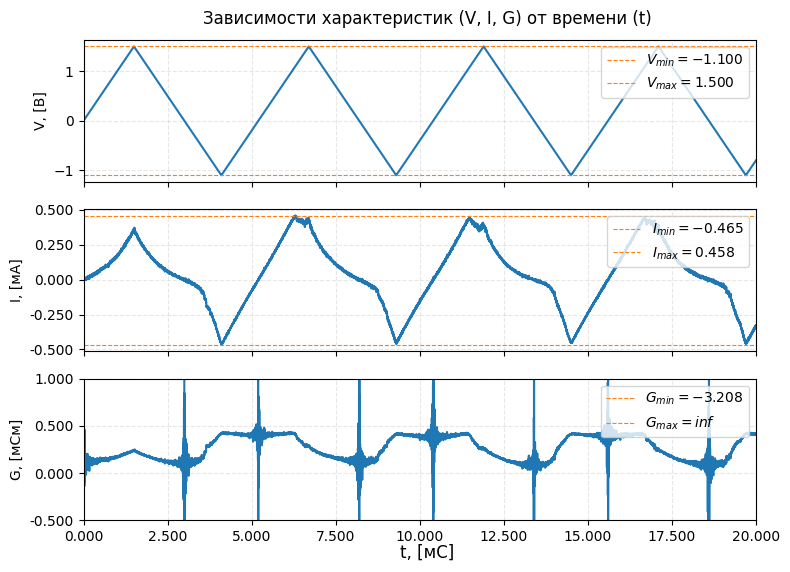

In [25]:
set_inline_backend()

t_end = 0.02
end = int(t_end // dt) + 1

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8, 6), sharex=True)

T = build_time_array(0, end*dt, dt, endpoint=False)
V = arr_v[: end]; I = arr_i[: end]
G = calculate_G(V, I)

plot_signal(ax1, T, V, ylabel='V, [В]')
plot_signal(ax2, T, I, ylabel='I, [мА]')
plot_signal(ax3, T, G, ylabel='G, [мСм]')
plot_bounding_lines(ax1, V, legend=True, legend_prefix="V")
plot_bounding_lines(ax2, I, legend=True, legend_prefix="I", legend_unit_scale=1e3)
plot_bounding_lines(ax3, G, legend=True, legend_prefix="G", legend_unit_scale=1e3)

ax1.set_xlim(T[0], T[-1])
ax2.yaxis.set_major_formatter(formatter_to_mA)
ax3.yaxis.set_major_formatter(formatter_to_mSm)

ax3.set_ylim(-5e-4, 1e-3)

fig.suptitle('Зависимости характеристик (V, I, G) от времени (t)', x=0.54, y=0.97)
fig.supxlabel('t, [мС]', x=0.54, y=0.05)
fig.gca().xaxis.set_major_formatter(formatter_to_mS)

plt.tight_layout()
plt.show()

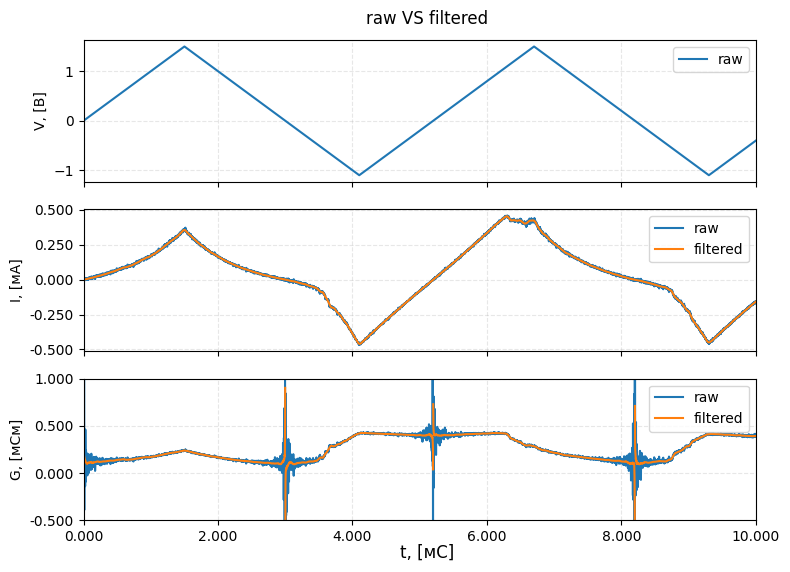

In [26]:
set_inline_backend()
# ==============================================================================

t_end = 0.01
end = int(t_end // dt) + 1

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8, 6), sharex=True)

T = build_time_array(0, end*dt, dt, endpoint=False)
V = arr_v[: end]; I = arr_i[: end]
I_smooth = filter_current(I, high_smooth=True)
G = calculate_G(V, I)
G_smooth = calculate_G(V, I_smooth)

ax1.plot(T, V, label='raw')
ax2.plot(T, I, label='raw')
ax3.plot(T, G, label='raw')
ax2.plot(T, I_smooth, label='filtered')
ax3.plot(T, G_smooth, label='filtered')

for ax in [ax1, ax2, ax3]:
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.legend(loc="upper right", fontsize="medium")
    ax.set_xlim(T[0], T[-1])

ax2.yaxis.set_major_formatter(formatter_to_mA)
ax3.yaxis.set_major_formatter(formatter_to_mSm)
ax3.set_ylim(-5e-4, 1e-3)

ax1.set_ylabel("V, [В]")
ax2.set_ylabel("I, [мА]")
ax3.set_ylabel("G, [мСм]")

fig.suptitle('raw VS filtered', x=0.54, y=0.97)
fig.supxlabel('t, [мС]', x=0.54, y=0.05)
fig.gca().xaxis.set_major_formatter(formatter_to_mS)

plt.tight_layout()
plt.show()

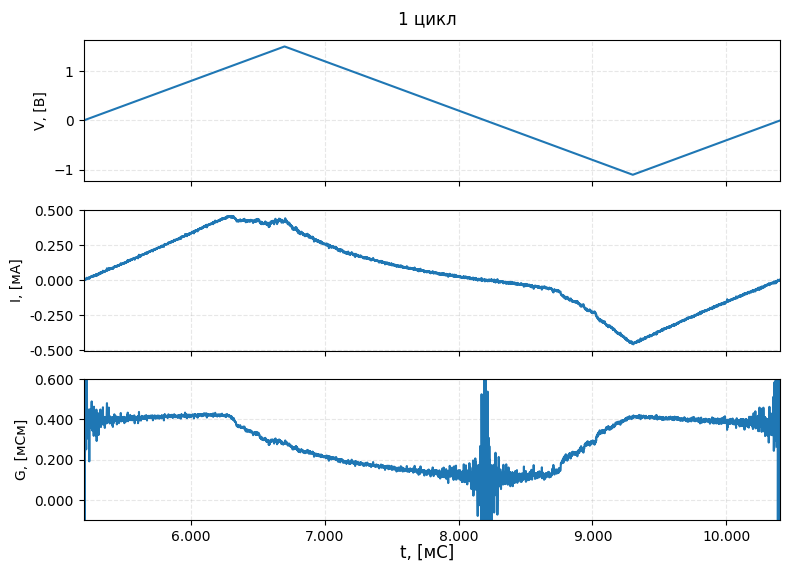

In [27]:
set_inline_backend()
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8, 6), sharex=True)

zero_idxs = np.where(arr_v == 0)[0]
start_idx = zero_idxs[2]
end_idx   = zero_idxs[4]

# T = build_time_array(end_idx - start_idx + 1, dt, start=start_idx)
T = build_time_array(start_idx*dt, end_idx*dt, dt)
V = arr_v[start_idx : end_idx + 1]; I = arr_i[start_idx : end_idx + 1]
G = calculate_G(V, I)

plot_signal(ax1, T, V, ylabel='V, [В]')
plot_signal(ax2, T, I, ylabel='I, [мА]')
plot_signal(ax3, T, G, ylabel='G, [мСм]')

ax1.set_xlim(T[0], T[-1])
ax2.yaxis.set_major_formatter(formatter_to_mA)
ax3.yaxis.set_major_formatter(formatter_to_mSm)
# ax3.set_xlim(8e-3, 8.5e-3)
ax3.set_ylim(-1e-4, 6e-4)

fig.suptitle('1 цикл', x=0.54, y=0.97)
fig.supxlabel('t, [мС]', x=0.54, y=0.05)
fig.gca().xaxis.set_major_formatter(formatter_to_mS)

plt.tight_layout()
plt.show()

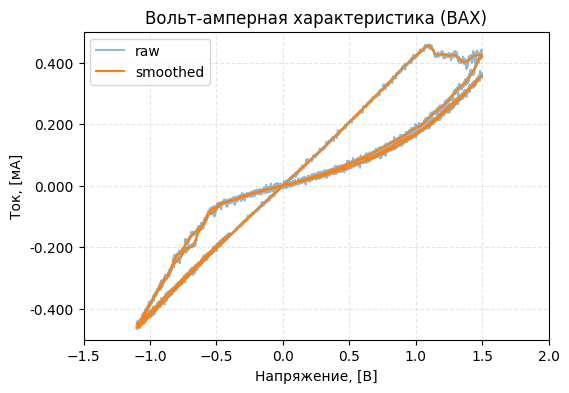

In [28]:
set_inline_backend()
t_end = 0.01
end = int(t_end // dt) + 1

V = arr_v[: end]; I = arr_i[: end]
G = calculate_G(V, I)
I_smooth = filter_current(I)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(V, I, label='raw', alpha=0.5)
ax.plot(V, I_smooth, label="smoothed")
ax.set(title="Вольт-амперная характеристика (ВАХ)", xlabel="Напряжение, [В]", ylabel="Ток, [мА]")
ax.set_xlim(-1.5, 2.0)
ax.set_ylim(-0.5e-3, 0.5e-3)
ax.yaxis.set_major_formatter(formatter_to_mA)
ax.grid(True, linestyle='--', alpha=0.3)
plt.legend()
plt.show()

In [17]:
zero_indices, peak_indices, valley_indices = find_extrema_and_zeros(arr_v)
extremum_indices = np.sort(np.concatenate([peak_indices, valley_indices]))
boundary_indices = np.sort(np.concatenate([zero_indices, peak_indices, valley_indices]))

# print(f"zero indexes: {zero_idxs}")
# print(f"peak indexes: {peak_idxs}")
# print(f"valley indexes: {valley_idxs}")
# print(f"extremum indexes: {extremum_idxs}")
# print(f"boundary indexes: {boundary_idxs}")

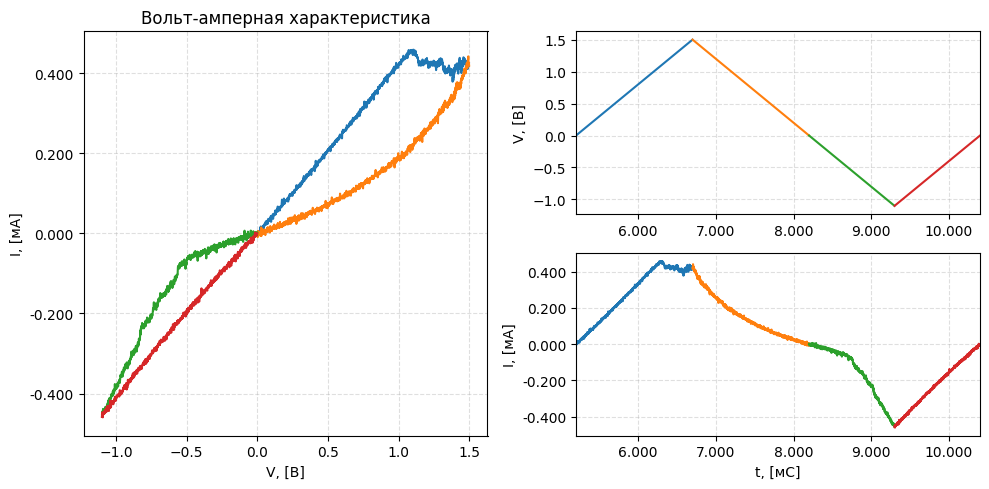

In [19]:
set_inline_backend()
fig = plt.figure(figsize=(10, 5))
ax_vah = plt.subplot2grid((2, 2), (0, 0), rowspan=2)
ax_v = plt.subplot2grid((2, 2), (0, 1), colspan=1)
ax_i = plt.subplot2grid((2, 2), (1, 1), colspan=1, sharex=ax_v)

start, end = zero_indices[2], zero_indices[2 * 2] + 1

T = build_time_array(start*dt, end*dt, dt, endpoint=False)
V = arr_v[start : end]; I = arr_i[start : end]
G = calculate_G(V, I)

plot_segments(ax_vah, V, I, boundary_indices[0 : ], segments_per_peroid=4)
plot_segments(ax_v, T, V, boundary_indices[0 : ], segments_per_peroid=4)
plot_segments(ax_i, T, I, boundary_indices[0 : ], segments_per_peroid=4)

ax_vah.set(xlabel="V, [В]", ylabel="I, [мА]", title="Вольт-амперная характеристика")
ax_v.set(ylabel="V, [В]")
ax_i.set(xlabel="t, [мС]", ylabel="I, [мА]")

ax_i.set_xlim(T[0], T[-1])
ax_v.set_xlim(T[0], T[-1])

ax_vah.yaxis.set_major_formatter(formatter_to_mA)
ax_v.xaxis.set_major_formatter(formatter_to_mS)
ax_i.xaxis.set_major_formatter(formatter_to_mS)
ax_i.yaxis.set_major_formatter(formatter_to_mA)

for ax in [ax_vah, ax_v, ax_i]:
    ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

## Извлечение циклов ВАХ

In [16]:
def get_period_indices(signal: np.ndarray, i: int, zero_indices:np.ndarray, segments_per_period: int = 1, period_start_segment_idx: int = 0):
    if (i < 0) or (segments_per_period < 1) or (period_start_segment_idx < 0):
        return (-1, -1)
    if len(zero_indices) == 0:
        return (0, len(signal))
    
    # normalize
    period_start_segment_idx %= segments_per_period

    if period_start_segment_idx >= len(zero_indices):
        return (0, len(signal)) if i == 0 else (-1, -1)

    incomplete_on_start = 1 if zero_indices[0 + period_start_segment_idx] != 0 else 0
    p_start, p_end = i * segments_per_period, (i + 1) * segments_per_period

    p_start += period_start_segment_idx
    p_end += period_start_segment_idx
    
    start_zero_idx = p_start - incomplete_on_start * segments_per_period
    end_zero_idx = p_end - incomplete_on_start * segments_per_period

    if start_zero_idx >= len(zero_indices):
        return (-1, -1)

    start   = (zero_indices[start_zero_idx]) if (start_zero_idx >= 0) else (0)
    end     = (zero_indices[end_zero_idx]) if (end_zero_idx < len(zero_indices)) else (len(signal))
        
    return start, end

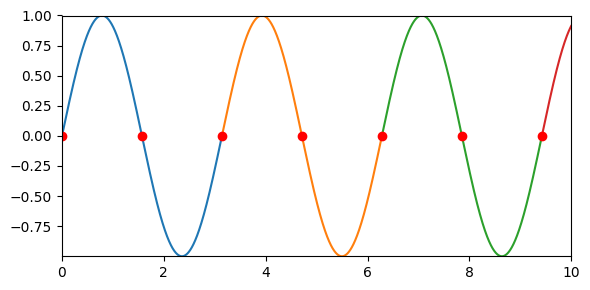

In [32]:
# ==============================================================================
# TEST CODE
# ==============================================================================
set_inline_backend()
t = np.arange(0, 10 + 1e-9, 1e-3)
signal = np.sin((t) * 2)

zero_indices, _, _ = find_extrema_and_zeros(signal)

fig, ax = plt.subplots(figsize=(6, 3))

ax.scatter(t[zero_indices], signal[zero_indices], color='red', zorder=1)

for i in range(0, 10):
    start, end = get_period_indices(signal, i, zero_indices=zero_indices, segments_per_period=2, period_start_segment_idx=0)
    if start != -1 and end != -1:
        ax.plot(t[start: end], signal[start: end], zorder=0)

ax.set_xlim(t[0], t[-1])
ax.set_ylim(min(signal), max(signal))

plt.tight_layout()
plt.show()

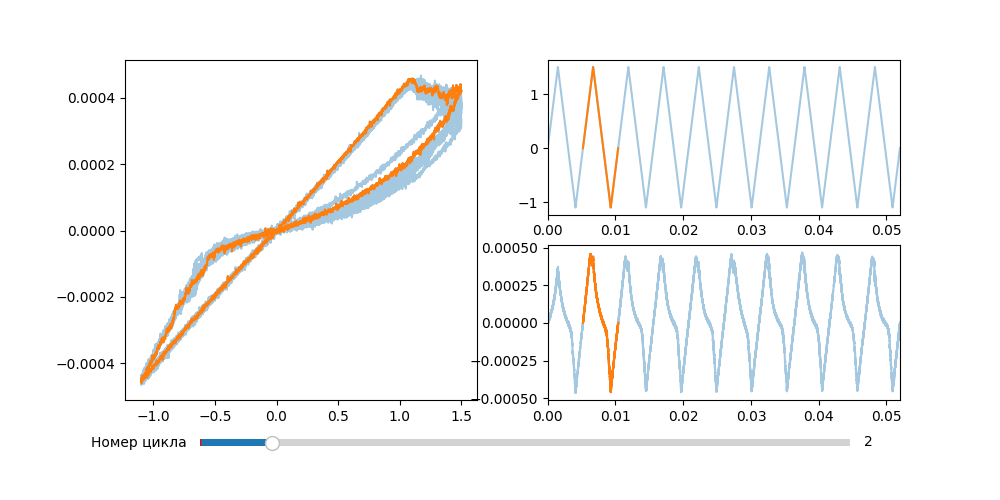

In [33]:
set_widget_backend()
# ==============================================================================
n = 10

start, _ = get_period_indices(arr_v, 0, zero_indices=arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)
_, end = get_period_indices(arr_v, n - 1, zero_indices=arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)
end += 1

T = build_time_array(start*dt, end*dt, dt, endpoint=False)
V = arr_v[start : end]; I = arr_i[start : end]
V_zeros = arr_v_zeros[arr_v_zeros >= start]

fig = plt.figure(figsize=(10, 5))
ax_vah = plt.subplot2grid((2, 2), (0, 0), rowspan=2)
ax_v = plt.subplot2grid((2, 2), (0, 1), colspan=1)
ax_i = plt.subplot2grid((2, 2), (1, 1), colspan=1, sharex=ax_v)
plt.subplots_adjust(bottom=0.2)

ax_i.set_xlim(T[0], T[-1])
ax_v.set_xlim(T[0], T[-1])
ax_i.set_xlabel("t, [мС]")

slider_ax = plt.axes([0.2, 0.1, 0.65, 0.03])
slider = Slider(slider_ax, 'Номер цикла', 1, n, valinit=1, valstep=1)

def update(val):
    ax_i.clear(); ax_v.clear(); ax_vah.clear()

    ax_i.plot(T, I, alpha=0.4)
    ax_v.plot(T, V, alpha=0.4)
    ax_vah.plot(V, I, alpha=0.4)
    ax_i.set_xlim(T[0], T[-1])
    ax_v.set_xlim(T[0], T[-1])
    
    start, end = get_period_indices(V, val - 1, V_zeros, segments_per_period=2, period_start_segment_idx=0)

    if start != -1 and end != -1:
        ax_i.plot(T[start:end], arr_i[start:end])
        ax_v.plot(T[start:end], arr_v[start:end])
        ax_vah.plot(arr_v[start:end], arr_i[start:end])

    fig.canvas.draw_idle()

slider.on_changed(update)
slider.set_val(2)

plt.show()

## Устранение разрывов сигнала $G(t)$

In [18]:
from scipy.interpolate import CubicSpline

In [19]:
def interpolate_outliers_nearest(signal, k=1.5):
    q1, q3 = np.percentile(signal, [25, 75])
    iqr = q3 - q1
    mask = (signal < q1 - k * iqr) | (signal > q3 + k * iqr)
    valid = np.where(~mask)[0]
    if valid.size < 2:
        return

    outliers = np.where(mask)[0]
    pos = np.searchsorted(valid, outliers, side='left')

    left_idx = np.clip(pos - 1, 0, valid.size - 1)
    left = np.where(pos > 0, valid[left_idx], -1)
    right_idx = np.clip(pos, 0, valid.size - 1)
    right = np.where(pos < valid.size, valid[right_idx], -1)
    
    d_l, d_r = np.abs(outliers - left), np.abs(right - outliers)
    signal[outliers] = signal[np.where((left != -1) & ((right == -1) | (d_l <= d_r)), left, right)]

def interpolate_outliers_linear(signal, k=1.5):
    q1, q3 = np.percentile(signal, [25, 75])
    iqr = q3 - q1
    mask = (signal < q1 - k * iqr) | (signal > q3 + k * iqr)
    valid = np.where(~mask)[0]
    if valid.size < 2:
        return

    outliers = np.flatnonzero(mask)
    signal[outliers] = CubicSpline(valid, signal[valid], bc_type='natural')(outliers)

def interpolate_outliers_cubic(signal, k=1.5):
    q1, q3 = np.percentile(signal, [25, 75])
    iqr = q3 - q1
    mask = (signal < q1 - k * iqr) | (signal > q3 + k * iqr)
    valid = np.where(~mask)[0]
    if valid.size < 2:
        return

    signal[mask] = np.interp(np.where(mask)[0], valid, signal[valid])

def interpolate_outliers_median(signal, break_index, window_size, k=1.5):
    interval_start = int(max(0, break_index - window_size // 2))
    interval_end = int(min(len(signal) - 1, break_index + window_size // 2) + 1)
    
    signal_window = signal[interval_start : interval_end]

    q1, q3 = np.percentile(signal_window, [25, 75])
    iqr = q3 - q1
    mask = (signal_window < q1 - k * iqr) | (signal_window > q3 + k * iqr)
    valid = np.where(~mask)[0]
    if valid.size < 2:
        return

    outliers = np.where(mask)[0]

    left = max(0, interval_start - window_size // 2)
    right = min(interval_end + window_size // 2, len(signal))

    processed = median_filter(signal[left : right], size=window_size, mode='wrap')
    
    signal[interval_start : interval_end][outliers] = processed[interval_start - left : len(processed) - (right - interval_end)][outliers]

In [20]:
def interpolate_break_median(signal, break_index, window_size):
    interval_start = int(max(0, break_index - window_size // 2))
    interval_end = int(min(len(signal) - 1, break_index + window_size // 2) + 1)

    left = max(0, interval_start - window_size // 2)
    right = min(interval_end + window_size // 2, len(signal))

    processed = median_filter(signal[left : right], size=window_size, mode='wrap')
    
    signal[interval_start : interval_end] = processed[interval_start - left : len(processed) - (right - interval_end)]  

In [21]:
def interpolate_break_with_line(signal, break_index, break_width, mode='mirror'):
    if break_width % 2 == 0 or break_width < 3:
        raise ValueError("break_width should be odd and > 1")
    assert mode in ['mirror', 'wrap'], "Incorrect mode was given"

    left = max(0, break_index - break_width // 2)
    right = min(break_index + break_width // 2, len(signal) - 1)

    left_out = break_index - break_width // 2 < 0
    right_out = break_index + break_width // 2 >= len(signal)

    x1 = left
    x2 = right
    if left_out:
        x1 = (len(signal) - break_width // 2 - break_index) if (mode == 'wrap') else (break_width // 2 - break_index)
    if right_out:
        x2 = (break_width // 2 - break_index) if (mode == 'wrap') else (len(signal) - break_width // 2 - break_index)

    x1 = int(x1)
    x2 = int(x2)
    y1 = signal[x1]
    y2 = signal[x2]
    k = (y2 - y1) / (break_width)

    left_offset = (break_width // 2 - break_index) if (left_out) else (0)
    width = right - left + 1
    signal[left : right + 1] = y1 + k * np.linspace(left_offset, left_offset + width, width)

In [58]:
# Подготовка тестовых интервалов

# Извлекаем 2 и 3-й циклы ВАХ
start, end = get_period_indices(arr_v, 1, arr_v_zeros, segments_per_period=4, period_start_segment_idx=0)
end += 1

T = build_time_array(start*dt, end*dt, dt, endpoint=False)
I = arr_i[start : end]; V = arr_v[start : end]; I_smooth = filter_current(I)

V_zeros = arr_v_zeros[(arr_v_zeros >= start) & (arr_v_zeros <= end)] - start

G = calculate_G(V, I)
G_filtered = calculate_G(V, I_smooth)

# ширина разрыва (5% от длины цикла)
break_length = int(0.05 * len(V))

### Вариант №1. Интерполяция линией

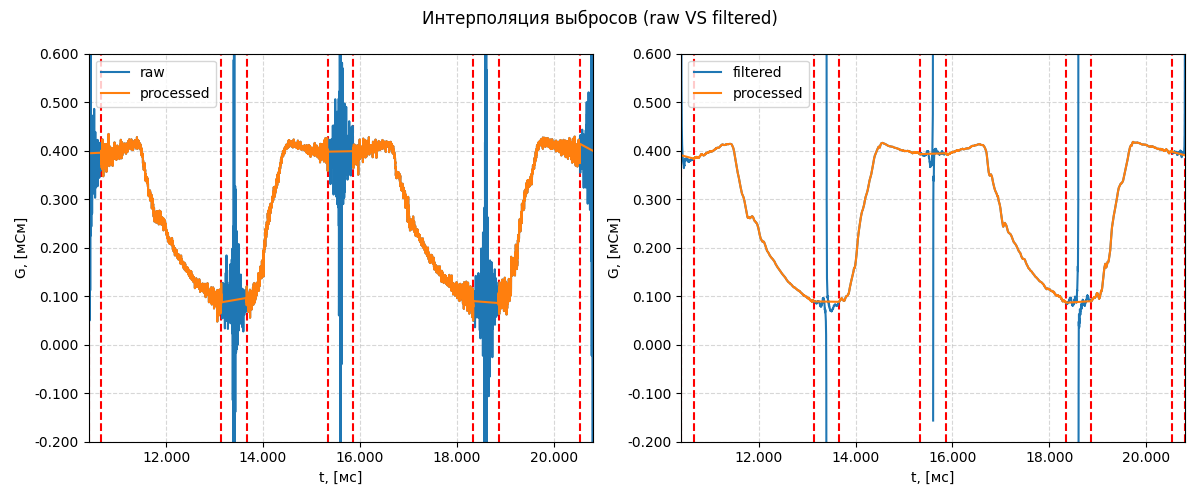

In [59]:
set_widget_backend()
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

window = break_length if break_length % 2 != 0 else break_length + 1

G_processed = G.copy()
G_filtered_processed = G_filtered.copy()

for zero_index in V_zeros:
    interpolate_break_with_line(G_processed, zero_index, window, mode='wrap')
    interpolate_break_with_line(G_filtered_processed, zero_index, window, mode='wrap')

    interval_start = int(max(0, zero_index - window // 2))
    interval_end = int(min(len(V) - 1, zero_index + window // 2) + 1)
    for ax in [ax1, ax2]:
        ax.axvline(T[interval_start], linestyle='--', color='red')
        ax.axvline(T[interval_end - 1], linestyle='--', color='red')

ax1.plot(T, G, label='raw')
ax1.plot(T, G_processed, label='processed')
ax2.plot(T, G_filtered, label='filtered')
ax2.plot(T, G_filtered_processed, label='processed')

for ax in [ax1, ax2]:
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_ylim(-0.2e-3, 0.6e-3)
    ax.set_xlim(T[0], T[-1])
    ax.xaxis.set_major_formatter(formatter_to_mS)
    ax.yaxis.set_major_formatter(formatter_to_mSm)
    ax.set_xlabel("t, [мc]")
    ax.set_ylabel("G, [мСм]")
    ax.legend()

fig.suptitle("Интерполяция выбросов (raw VS filtered)")
plt.tight_layout()
plt.show()

### Вариант №2. Интерполяция выбросов

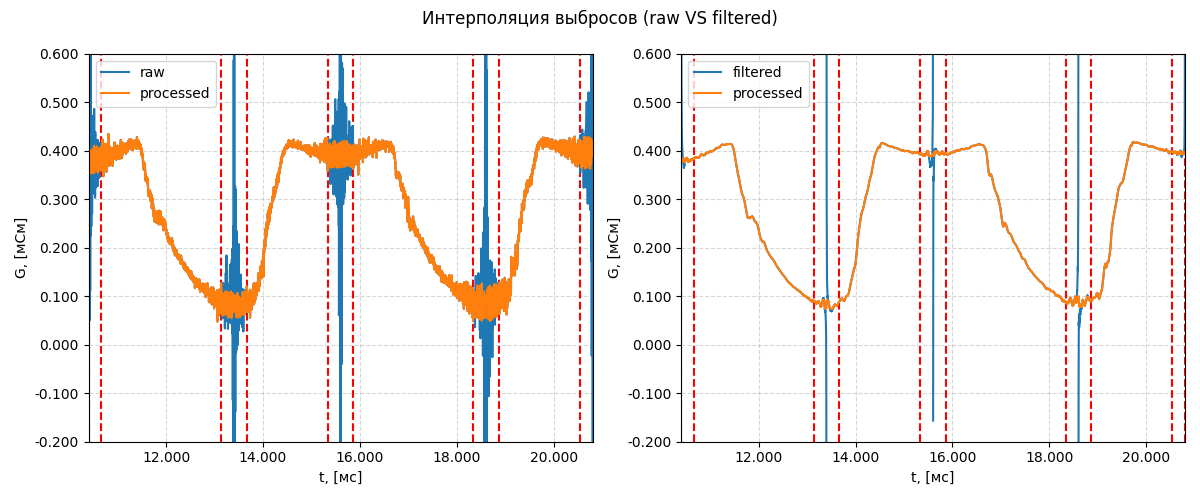

In [60]:
set_widget_backend()
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

window = break_length * 1.0

k = 0.5
G_processed = G.copy()
G_filtered_processed = G_filtered.copy()

for zero_index in V_zeros:
    interval_start = int(max(0, zero_index - window // 2))
    interval_end = int(min(len(V) - 1, zero_index + window // 2) + 1)

    interpolate_outliers_nearest(G_processed[interval_start : interval_end], k=k)
    interpolate_outliers_nearest(G_filtered_processed[interval_start : interval_end], k=k)

    # interpolate_outliers_linear(G_processed[interval_start : interval_end], k=k)
    # interpolate_outliers_linear(G_filtered_processed[interval_start : interval_end], k=k)

    # interpolate_outliers_cubic(G_processed[interval_start : interval_end], k=k)
    # interpolate_outliers_cubic(G_filtered_processed[interval_start : interval_end], k=k)

    for ax in [ax1, ax2]:
        ax.axvline(T[interval_start], linestyle='--', color='red')
        ax.axvline(T[interval_end - 1], linestyle='--', color='red')

ax1.plot(T, G, label='raw')
ax1.plot(T, G_processed, label='processed')
ax2.plot(T, G_filtered, label='filtered')
ax2.plot(T, G_filtered_processed, label='processed')

for ax in [ax1, ax2]:
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_ylim(-0.2e-3, 0.6e-3)
    ax.set_xlim(T[0], T[-1])
    ax.xaxis.set_major_formatter(formatter_to_mS)
    ax.yaxis.set_major_formatter(formatter_to_mSm)
    ax.set_xlabel("t, [мc]")
    ax.set_ylabel("G, [мСм]")
    ax.legend()

fig.suptitle("Интерполяция выбросов (raw VS filtered)")
plt.tight_layout()
plt.show()

### Вариант №3. Устранение разрывов медианным фильтром

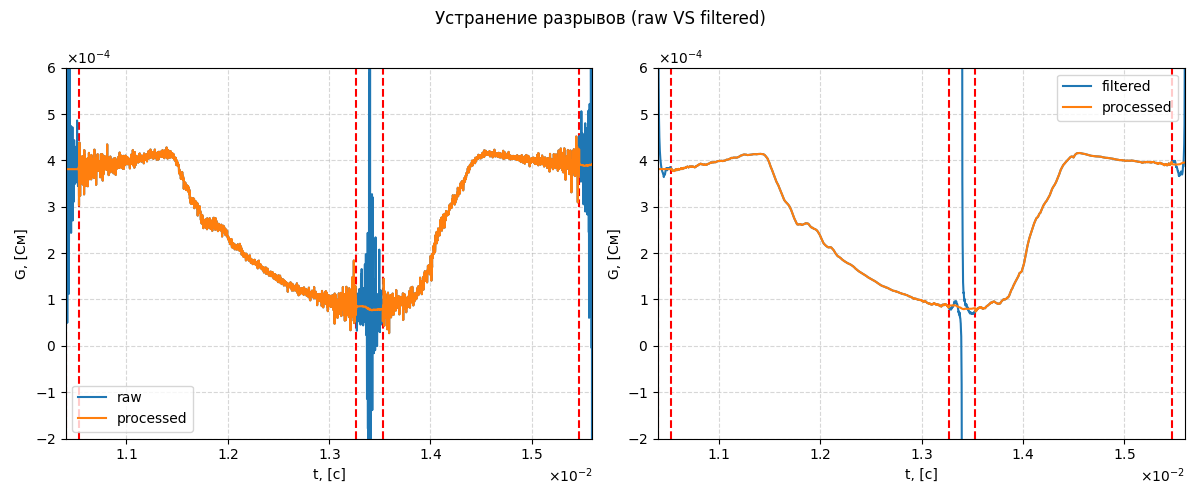

In [69]:
set_widget_backend()
# ==============================================================================

# window = int(break_length // 2.5)
window = break_length // 2
G_processed = G.copy()
G_filtered_processed = G_filtered.copy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

for zero_index in V_zeros:
    interval_start = int(max(0, zero_index - window // 2))
    interval_end = int(min(len(V) - 1, zero_index + window // 2) + 1)
    
    interpolate_break_median(G_processed, zero_index, window)
    interpolate_break_median(G_filtered_processed, zero_index, window)

    for ax in [ax1, ax2]:
        ax.axvline(T[interval_start], linestyle='--', color='red')
        ax.axvline(T[interval_end - 1], linestyle='--', color='red')

ax1.plot(T, G, label='raw')
ax1.plot(T, G_processed, label='processed')
ax2.plot(T, G_filtered, label='filtered')
ax2.plot(T, G_filtered_processed, label='processed')

for ax in [ax1, ax2]:
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_ylim(-0.2e-3, 0.6e-3)
    ax.set_xlim(T[0], T[5200])# T[-1])
    set_scientific_yaxis(ax)
    set_scientific_xaxis(ax)
    ax.set_xlabel("t, [c]")
    ax.set_ylabel("G, [См]")
    ax.legend()

fig.suptitle("Устранение разрывов (raw VS filtered)")
plt.tight_layout()
plt.show()

### Вариант №3. Комбинация двух способов

NameError: name 'break_length' is not defined

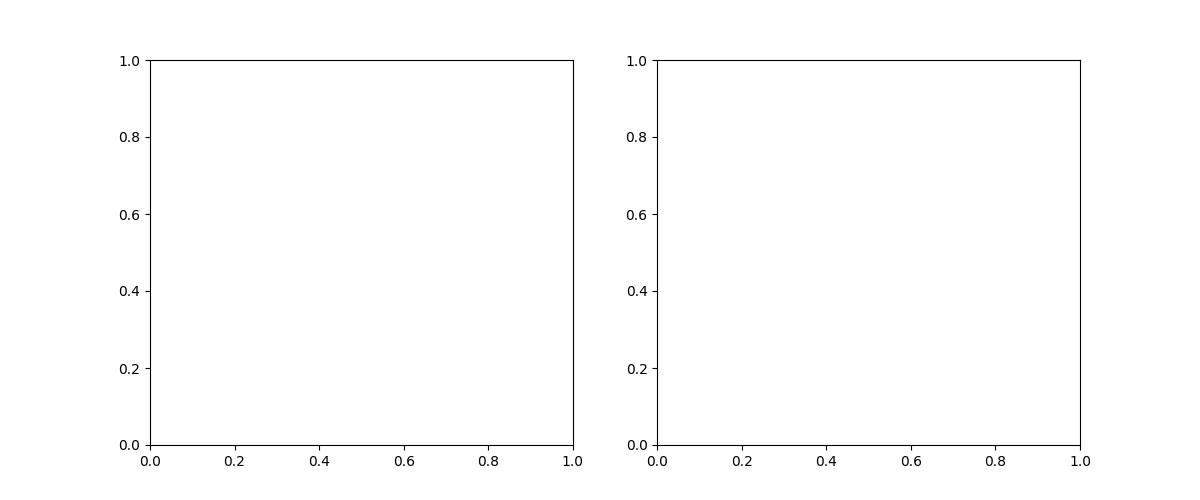

In [42]:
set_widget_backend()
# ==============================================================================

# 1. интерполяция выбросов
# 2. устранение разрывов медианным фильтром
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

k = 0.025
window = break_length
window_median = int(break_length // 6)

G_processed = G.copy()
G_filtered_processed = G_filtered.copy()

for zero_index in zero_indices:
    interval_start = int(max(0, zero_index - window // 2))
    interval_end = int(min(len(V) - 1, zero_index + window // 2) + 1)

    # interpolate_outliers_nearest(G_processed[interval_start : interval_end], k=k)
    # interpolate_outliers_nearest(G_filtered_processed[interval_start : interval_end], k=k)

    # interpolate_break_median(G_processed, zero_index, window_median)
    # interpolate_break_median(G_filtered_processed, zero_index, window_median)

    interpolate_outliers_median(G_processed, zero_index, window_median, k=k)
    interpolate_outliers_median(G_filtered_processed, zero_index, window_median, k=k)

    for ax in [ax1, ax2]:
        ax.axvline(T[interval_start], linestyle='--', color='red')
        ax.axvline(T[interval_end - 1], linestyle='--', color='red')

ax1.plot(T, G, label='raw')
ax1.plot(T, G_processed, label='processed')
ax2.plot(T, G_filtered, label='filtered')
ax2.plot(T, G_filtered_processed, label='processed')

for ax in [ax1, ax2]:
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_ylim(-0.2e-3, 0.6e-3)
    ax.set_xlim(T[0], T[-1])
    ax.xaxis.set_major_formatter(formatter_to_mS)
    ax.yaxis.set_major_formatter(formatter_to_mSm)
    ax.set_xlabel("t, [мc]")
    ax.set_ylabel("G, [мСм]")
    ax.legend()

fig.suptitle("Интерполяция выбросов (raw VS filtered)")
plt.tight_layout()
plt.show()

## Извлечение мемристивного тока $I_m(t)$. Извлечение переменной состояния $X$

In [43]:
test_params = {
    'phi': 0.99692315,
    'a_f': 9.98651968 * 0.000459433,
    'a_r': 9.56718777 * 0.000459433,
    'b_f': 2.69133521 / 1.5,
    'b_r': 2.40015179 / 1.5 
}

In [44]:
# Подготовка тестовых данных
params = test_params

# Извлекаем 2-й цикл ВАХ-ки
start, end = get_period_indices(arr_v, 1, segments_per_period=2, period_start_segment_idx=0)
end += 1

T = build_time_array(start*dt, end*dt, dt, endpoint=False)
I = arr_i[start : end]; V = arr_v[start : end]
G = calculate_G(V, I)

V_zeros = arr_v_zeros[(arr_v_zeros >= start) & (arr_v_zeros <= end)] - start

V0_idx = V_zeros[1]; V_max_idx = np.argmax(V); V_min_idx = np.argmin(V)

# Извлекаем мемристивный ток
I_s = extract_schottky_current(V, params['a_f'], params['a_r'], params['b_f'], params['b_r'])
I_m = extract_memristive_current(I, params['phi'], I_s)

# Проводимость и мемдуктивность
G = calculate_G(V, I)
G_m = calculate_G(V, I_m)

NameError: name 'get_zero_indices' is not defined

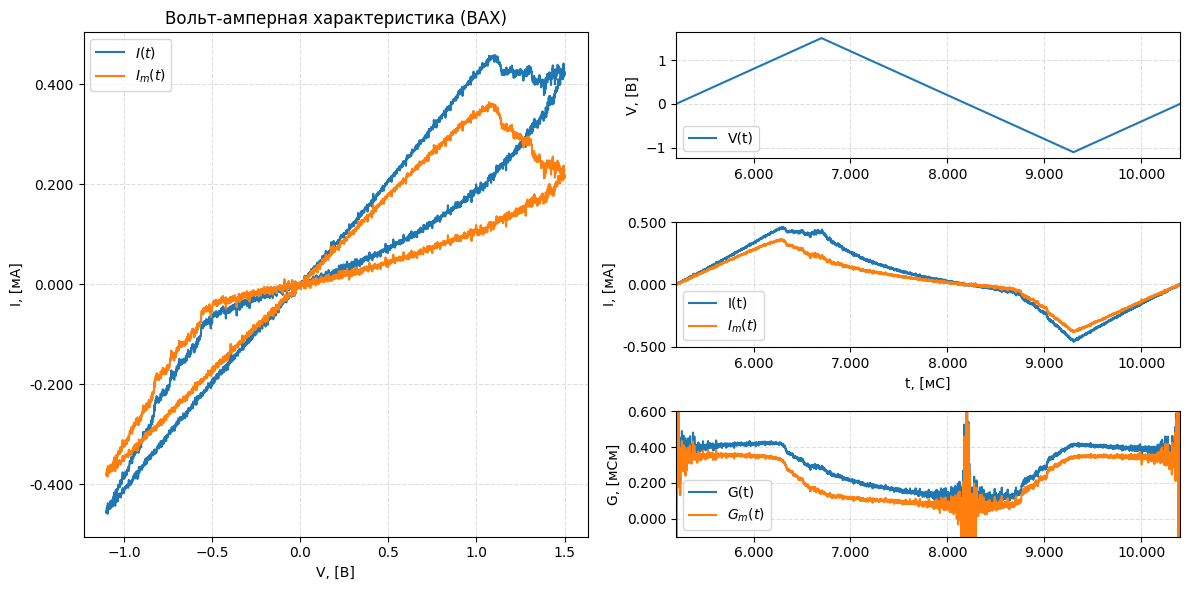

In [211]:
set_inline_backend()

fig = plt.figure(figsize=(12, 6))
ax_vah = plt.subplot2grid((3, 2), (0, 0), rowspan=3)
ax_v = plt.subplot2grid((3, 2), (0, 1), colspan=1)
ax_i = plt.subplot2grid((3, 2), (1, 1), colspan=1, sharex=ax_v)
ax_g = plt.subplot2grid((3, 2), (2, 1), colspan=1, sharex=ax_v)

# fig.delaxes(ax_vah)

ax_vah.plot(V, I, label='$I(t)$')
ax_vah.plot(V, I_m, label="$I_m(t)$")
ax_v.plot(T, V, label='V(t)')
ax_i.plot(T, I, label='I(t)')
ax_i.plot(T, I_m, label=r'$I_m(t)$')
ax_g.plot(T, G, label='G(t)')
ax_g.plot(T, G_m, label='$G_m(t)$')

ax_vah.set(title="Вольт-амперная характеристика (ВАХ)", xlabel="V, [В]", ylabel="I, [мА]")
ax_i.set(xlabel="t, [мС]", ylabel="I, [мА]")
ax_v.set_ylabel("V, [В]")
ax_g.set_ylabel("G, [мСм]")

# ax_vah.set_xlim(-1.5, 2.0)
# ax_vah.set_ylim(-0.5e-3, 0.5e-3)
ax_g.set_ylim(-0.1e-3, 0.6e-3)

ax_vah.yaxis.set_major_formatter(formatter_to_mA)
ax_i.yaxis.set_major_formatter(formatter_to_mA)
ax_g.yaxis.set_major_formatter(formatter_to_mSm)

for ax in [ax_vah, ax_v, ax_i, ax_g]:
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc="upper left", fontsize="medium")

for ax in [ax_v, ax_i, ax_g]:
    ax.set_xlim(T[0], T[-1])
    ax.xaxis.set_major_formatter(formatter_to_mS)
    ax.legend(loc="lower left", fontsize="medium")

plt.tight_layout()
plt.show()

In [212]:
# Подготовка данных №2

# Сглаживание тока
I_smoothed = filter_current(I, high_smooth=True)
I_m_smoothed = filter_current(I_m, high_smooth=True)

# находим обалсти HRS, LRS
source_reset = detect_reset(I_smoothed, V_max_idx, V0_idx, V_min_idx, starts_with_hrs=False)
source_set = detect_set(I_smoothed, V_max_idx, V0_idx, V_min_idx, starts_with_hrs=False)
target_reset = detect_reset(I_m_smoothed, V_max_idx, V0_idx, V_min_idx, starts_with_hrs=False)
target_set = detect_set(I_m_smoothed, V_max_idx, V0_idx, V_min_idx, starts_with_hrs=False)

# Параметры обработки
# ширина разрыва (5% от длины цикла)
break_width = (0.05 * len(V))
# длины окон для сглаживания (для предобработки + устранения разрывов)
filter_window = 51
interpolate_window = int(0.2e-3 // dt)
# области преобработочной фильтрации (HRS + LRS)
source_filter_intervals = [(V_min_idx, end - start), (0, source_reset), (V_max_idx, source_set)]
target_filter_intervals = [(V_min_idx, end - start), (0, target_reset), (V_max_idx, target_set)]

# Фильтрация + Устранение разрывов
G_filtered = G.copy()
for filter_interval in source_filter_intervals:
    f_start, f_end = filter_interval
    G_filtered[f_start : f_end] = savgol_filter(G[f_start : f_end], window_length=filter_window, polyorder=3, mode='mirror')
for zero_index in zero_indices:
    interpolate_break_median(G_filtered, zero_index, window_size=interpolate_window)

G_m_filtered = G_m.copy()
for filter_interval in target_filter_intervals:
    f_start, f_end = filter_interval
    G_m_filtered[f_start : f_end] = savgol_filter(G_m[f_start : f_end], window_length=filter_window, polyorder=3, mode='mirror')
for zero_index in zero_indices:
    interpolate_break_median(G_m_filtered, zero_index, window_size=interpolate_window)

# Переменная состояния X
G_m_on = np.max(G_m_filtered); G_m_off = np.min(G_m_filtered)
G_m_normalized = (G_m_filtered - G_m_off) / (G_m_on - G_m_off)

# Производная переменной состояния X
G_m_normalized_diff = np.zeros_like(G_m_normalized)
G_m_normalized_diff[:-1] = np.diff(G_m_normalized)

# R_On = 1 / np.max(W) 
# R_Off = 1 / np.min(W)

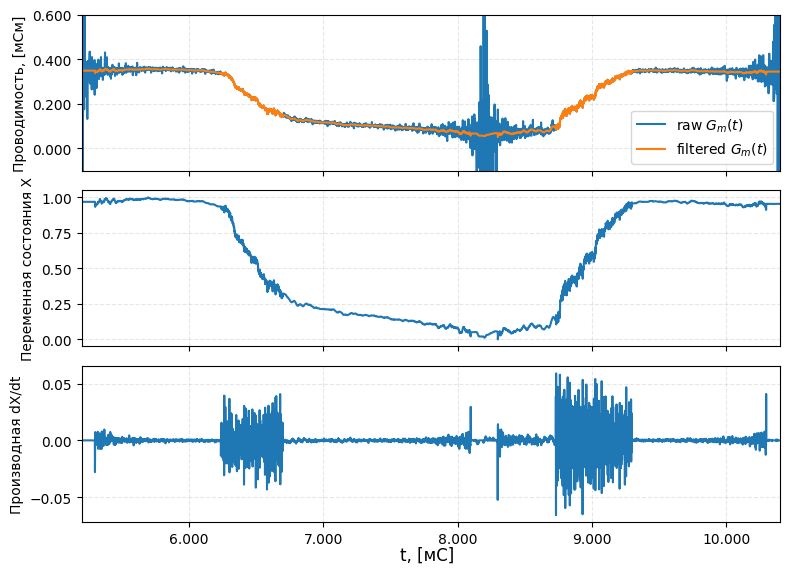

In [213]:
set_inline_backend()

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8, 6), sharex=True)

ax1.plot(T, G_m, label='raw $G_m(t)$')
ax1.plot(T, G_m_filtered, label='filtered $G_m(t)$')
ax2.plot(T, G_m_normalized)
ax3.plot(T, G_m_normalized_diff)

ax1.legend(loc="lower right", fontsize="medium")

for ax in [ax1, ax2, ax3]:
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.set_xlim(arr_t[start], arr_t[end])

ax1.set_ylim(-0.1e-3, 0.6e-3)
ax1.yaxis.set_major_formatter(formatter_to_mSm)

ax1.set_ylabel("Проводимость, [мСм]")
ax2.set_ylabel("Переменная состояния X")
ax3.set_ylabel("Производная dX/dt")

fig.supxlabel('t, [мС]', x=0.54, y=0.05)
fig.gca().xaxis.set_major_formatter(formatter_to_mS)

plt.tight_layout()
plt.show()

## Детекция ON, OFF, SET, RESET. Детекция HRS / LRS

In [16]:
params = np.array([[0.99979456, 0.01841604, 0.02753759, 2.74307016, 2.25557121],
       [0.99974745, 0.01792864, 0.03044526, 2.70788218, 2.20155342],
       [0.99975843, 0.02271833, 0.03093314, 2.53395145, 2.21263618],
       [0.99974469, 0.02046526, 0.03136271, 2.56145454, 2.18829945],
       [0.99886802, 0.0449092 , 0.04444087, 1.23018703, 1.16544187],
       [0.99981058, 0.02309113, 0.03964908, 2.68427883, 2.18697122],
       [0.9997617 , 0.03119519, 0.04097206, 2.3330632 , 2.03685027],
       [0.9997894 , 0.0160455 , 0.03322621, 2.79592022, 2.20817705],
       [0.99981691, 0.02189596, 0.0347627 , 2.66109878, 2.282056  ],
       [0.99983943, 0.01249029, 0.03607381, 3.06471958, 2.18862904],
       [0.99979848, 0.02027175, 0.03429412, 2.72191271, 2.27675754],
       [0.99975264, 0.02601538, 0.02789257, 2.46984468, 2.11215054],
       [0.9998534 , 0.01318743, 0.03633059, 3.12526454, 2.21690083],
       [0.99983349, 0.01132999, 0.03027808, 3.19788117, 2.36628929],
       [0.99983896, 0.01232838, 0.03083746, 3.09861713, 2.38667068],
       [0.9997374 , 0.03009156, 0.03595213, 2.27820547, 1.91080347],
       [0.99972311, 0.00686078, 0.01733857, 3.06583613, 2.34140179],
       [0.99981672, 0.01292288, 0.02480947, 3.05016475, 2.38772858],
       [0.99975446, 0.0176167 , 0.03008775, 2.60900938, 2.04628418],
       [0.99985953, 0.00941096, 0.03502889, 3.40514975, 2.41647335],
       [0.99957773, 0.02860134, 0.03585097, 1.98577995, 1.697855  ],
       [0.9998893 , 0.01776302, 0.04398995, 3.11462202, 2.47155679],
       [0.99986784, 0.01338063, 0.04230656, 3.19645481, 2.27681425],
       [0.99957966, 0.02650846, 0.02682501, 2.12105838, 2.00597524],
       [0.99983184, 0.01579299, 0.0285714 , 2.97823124, 2.42133221],
       [0.9997996 , 0.01965137, 0.03380826, 2.74895294, 2.2113022 ],
       [0.99923654, 0.01562007, 0.01721535, 2.03563153, 1.91291129],
       [0.99978927, 0.0095123 , 0.02800705, 3.03010024, 2.19915709],
       [0.99961777, 0.00898604, 0.01567205, 2.76561874, 2.16861727],
       [0.99962659, 0.01146307, 0.01868532, 2.69049651, 2.28950594],
       [0.99974197, 0.00837338, 0.02312921, 3.07681957, 2.18096701],
       [0.99980983, 0.00195845, 0.02204174, 4.21037762, 2.32225005],
       [0.99962016, 0.00683039, 0.01339076, 2.98603321, 2.3253035 ],
       [0.9995503 , 0.00781123, 0.01442633, 2.80665686, 2.26862565],
       [0.99943433, 0.0118146 , 0.01401292, 2.39973791, 2.17156468],
       [0.99957047, 0.0098169 , 0.01675968, 2.70580392, 2.17911688],
       [0.9993442 , 0.01065271, 0.01395342, 2.37613515, 2.04494559],
       [0.99927217, 0.0075136 , 0.01119202, 2.49826809, 2.0819234 ],
       [0.99951664, 0.0088215 , 0.01361672, 2.67879461, 2.19580073],
       [0.9990442 , 0.01237603, 0.01214881, 2.06313846, 1.92307893],
       [0.99908672, 0.00901317, 0.01139609, 2.24508562, 2.04233705],
       [0.99934937, 0.01145257, 0.01318634, 2.30502374, 2.16473786],
       [0.99916065, 0.01369762, 0.01517367, 2.01830205, 1.90064153],
       [0.9995876 , 0.01227783, 0.01539929, 2.62079766, 2.24524365],
       [0.99951278, 0.01712847, 0.0197925 , 2.23606912, 2.08743084],
       [0.99948431, 0.00672888, 0.01392341, 2.79219052, 2.19859292],
       [0.9994841 , 0.00868298, 0.01551797, 2.53377093, 2.097223  ],
       [0.99938084, 0.00946697, 0.01222567, 2.49247456, 2.13059983],
       [0.99917981, 0.0096233 , 0.01159072, 2.28090992, 2.04261354],
       [0.99955936, 0.00512831, 0.01152827, 2.93609949, 2.27386687],
       [0.99976024, 0.00391074, 0.01874446, 3.48171581, 2.20749717],
       [0.99921764, 0.02599311, 0.02625731, 1.734578  , 1.7420426 ],
       [0.9995186 , 0.01795764, 0.02109448, 2.18847796, 1.99747563],
       [0.99926966, 0.01888156, 0.01897356, 1.98670681, 1.85856475],
       [0.99942254, 0.00478878, 0.01151713, 2.9381783 , 2.2689148 ],
       [0.99957934, 0.0184708 , 0.0239248 , 2.29817712, 1.9916364 ],
       [0.999697  , 0.01625342, 0.02189591, 2.5863506 , 2.25786651],
       [0.99976407, 0.01105069, 0.02464575, 3.01727346, 2.25758666],
       [0.99966623, 0.02256276, 0.02600475, 2.18710832, 2.11088953],
       [0.99963611, 0.02862937, 0.02925596, 2.13712544, 2.05459087],
       [0.99979005, 0.01244574, 0.0296065 , 2.93426239, 2.24449785],
       [0.99980547, 0.01278326, 0.02771761, 2.92961775, 2.3060237 ],
       [0.99980628, 0.00774577, 0.02690738, 3.21635055, 2.30634851],
       [0.99945386, 0.01173766, 0.0134906 , 2.45180199, 2.17466818],
       [0.99970038, 0.00953165, 0.02006815, 2.8383273 , 2.1998554 ],
       [0.99968917, 0.00909264, 0.02164462, 2.83896719, 2.18732998],
       [0.99985703, 0.00328469, 0.02991649, 4.07044736, 2.39761875],
       [0.99979697, 0.00517453, 0.02722565, 3.50734121, 2.28757211],
       [0.99966734, 0.00797589, 0.01775306, 2.98772977, 2.34067326],
       [0.99953043, 0.01386057, 0.01788145, 2.25332914, 2.0496409 ],
       [0.99954268, 0.01966087, 0.02526798, 2.17398695, 1.93418966],
       [0.99976094, 0.00864121, 0.01950134, 3.14429454, 2.33095227],
       [0.99975078, 0.01163557, 0.02335374, 2.90430192, 2.34886713],
       [0.9997583 , 0.01403461, 0.02301272, 2.7845474 , 2.45708341],
       [0.99972497, 0.0146253 , 0.02088016, 2.6740571 , 2.24571124],
       [0.99966761, 0.01855644, 0.02448375, 2.41080782, 2.22442281],
       [0.99969182, 0.01492566, 0.02485516, 2.62501366, 2.23673999],
       [0.99981373, 0.01541788, 0.03143281, 2.87725766, 2.18185507],
       [0.99977171, 0.01601138, 0.03348494, 2.76873814, 2.20241041],
       [0.99987724, 0.01499366, 0.03539642, 3.1757425 , 2.47172015],
       [0.99986578, 0.0061759 , 0.04169352, 3.63947879, 2.24527655],
       [0.99979151, 0.0103409 , 0.01829397, 3.09425452, 2.44823463],
       [0.99985307, 0.00937873, 0.0346432 , 3.31574113, 2.28590957],
       [0.99979095, 0.01818835, 0.02657086, 2.62656571, 2.23042972],
       [0.99985714, 0.02366447, 0.0385529 , 2.74525228, 2.26915586],
       [0.99982857, 0.02371302, 0.0440467 , 2.62047362, 2.1688284 ],
       [0.99984777, 0.00867337, 0.02757249, 3.36277232, 2.3245848 ],
       [0.99982845, 0.02779042, 0.04127567, 2.423774  , 2.09502429],
       [0.99985547, 0.02214972, 0.03931197, 2.76958953, 2.31253841],
       [0.99987833, 0.01321587, 0.02985783, 3.20806613, 2.4786805 ],
       [0.99976906, 0.03157011, 0.04029263, 2.24470274, 1.96872908],
       [0.99984628, 0.01905408, 0.03581016, 2.75070734, 2.25587045],
       [0.99991756, 0.02267789, 0.04177752, 2.87773542, 2.27176236],
       [0.99988225, 0.02993299, 0.03903173, 2.70433891, 2.31745661],
       [0.99989458, 0.01049676, 0.04451309, 3.50712027, 2.43427661],
       [0.99989331, 0.01232645, 0.03860674, 3.33811904, 2.42490997],
       [0.99981131, 0.02347954, 0.02981432, 2.54269342, 2.33536396],
       [0.99984061, 0.01982752, 0.03243821, 2.75679599, 2.32897426],
       [0.99981045, 0.03223655, 0.04331175, 2.45850483, 2.16150533],
       [0.999818  , 0.02196294, 0.0370089 , 2.68459695, 2.2377005 ]])

In [17]:
# Извлекаем мемристивный ток для всех циклов
arr_i_m = np.empty_like(arr_i)

for j in range(N_cycles):
    start, end = get_period_indices(arr_v, 1 + j, arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)

    I = arr_i[start : end]; V = arr_v[start : end]

    phi, a_f, a_r, b_f, b_r = params[j]
    I_s = extract_schottky_current(V, a_f, a_r, b_f, b_r)
    I_m = extract_memristive_current(I, phi, I_s)
    arr_i_m[start : end] = I_m

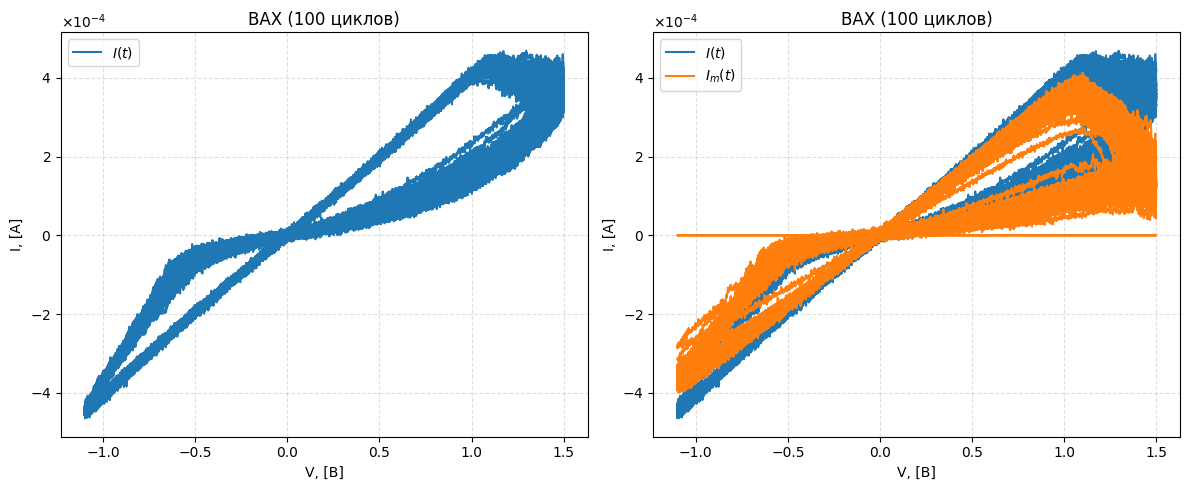

In [18]:
set_inline_backend()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(arr_v, arr_i, label='$I(t)$')
ax2.plot(arr_v, arr_i, label='$I(t)$')
ax2.plot(arr_v, arr_i_m, label="$I_m(t)$")

for ax in [ax1, ax2]:
    ax.set(title=f"ВАХ ({N_cycles} циклов)", xlabel="V, [В]", ylabel="I, [А]")
    set_scientific_yaxis(ax)
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc="upper left", fontsize="medium")

plt.tight_layout()
plt.show()

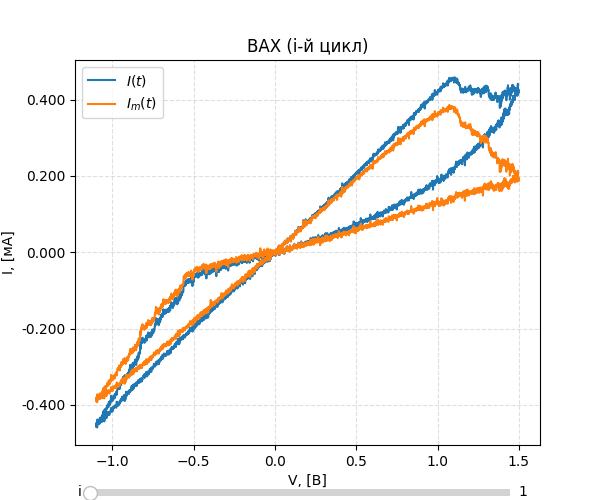

In [693]:
set_widget_backend()

# ==============================================================================

fig, ax = plt.subplots(figsize=(6, 5))

ax.set(title=f"ВАХ (i-й цикл)", xlabel="V, [В]", ylabel="I, [мА]")
ax.grid(True, linestyle='--', alpha=0.4)
ax.yaxis.set_major_formatter(formatter_to_mA)

slider_ax = plt.axes([0.15, 0.0, 0.7, 0.03])
slider = Slider(slider_ax, 'i', 1, N_cycles, valinit=1, valstep=1)

def update(val):
    for line in ax.get_lines():
        line.remove()

    i = val - 1
    start, end = get_period_indices(arr_v, val, arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)

    # i-й цикл ВАХ-ки
    v = arr_v[start : end]; i = arr_i[start : end]; i_m = arr_i_m[start : end]

    ax.plot(v, i, color='C0', label='$I(t)$')
    ax.plot(v, i_m, color='C1', label="$I_m(t)$")
    
    ax.relim()
    ax.legend(loc="upper left", fontsize="medium")

    fig.canvas.draw_idle()
    
slider.on_changed(update)
update(1)

plt.show()

### Детекция ON, OFF

In [22]:
def get_on_index(V_max_idx, V_min_idx, starts_with_hrs=True):
    return (min(V_max_idx, V_min_idx)) if (starts_with_hrs) else (max(V_max_idx, V_min_idx))

def get_off_index(V_max_idx, V_min_idx, starts_with_hrs=True):
    return (max(V_max_idx, V_min_idx)) if (starts_with_hrs) else (min(V_max_idx, V_min_idx))

### Детекция SET, RESET

#### Способ №1. Детекция изломов на графике ВАХ

In [17]:
def detect_breakpoint(
    y: np.ndarray,
    min_seg_len: int = 5,
    weights=(0.5, 0.5),
    x: np.ndarray = None
):
    # Кусочно-линейная аппроксимация с оптимизацией точки излома.
    # Минимизирует RSS двух прямых.
    
    n_points = len(y)
    
    valid_range = range(min_seg_len, n_points - min_seg_len + 1)
    best_k, best_rss = None, np.inf
    
    for k in valid_range:
        y1 = y[:k]
        y2 = y[k:]
        
        # Линейная аппроксимация по индексу (равномерная дискретизация)
        x1 = x[:k] if (x is not None) else np.arange(len(y1))
        x2 = x[k:] if (x is not None) else np.arange(len(y2))
        m1, c1 = np.polyfit(x1, y1, 1)
        m2, c2 = np.polyfit(x2, y2, 1)
        
        rss1 = np.sum((y1 - (m1*x1 + c1))**2)
        rss2 = np.sum((y2 - (m2*x2 + c2))**2)

        rss = weights[0] * rss1 + weights[1] * rss2

        # rss = np.sum((y1 - (m1*x1 + c1))**2) + np.sum((y2 - (m2*x2 + c2))**2)
        # rss = np.sum(np.abs(y1 - (m1*x1 + c1))) + np.sum(np.abs(y2 - (m2*x2 + c2)))
        
        if rss < best_rss:
            best_rss = rss
            best_k = k
    
    return best_k, best_rss

# ==================================================================================================

def detect_breakpoint_fast(
    smoothed_signal: np.ndarray,
    min_seg_len: int = 5
):
    n_points = len(smoothed_signal)

    # Кумулятивные суммы для O(1) вычисления моментов сегментов
    y = smoothed_signal
    idx = np.arange(n_points)
    cum_y = np.concatenate(([0], np.cumsum(y)))
    cum_y2 = np.concatenate(([0], np.cumsum(y**2)))
    cum_xy = np.concatenate(([0], np.cumsum(idx * y)))

    # Закрытая формула RSS для линейной регрессии без повторного polyfit
    def _calc_rss(n, Sx, Sxx, Sy, Syy, Sxy):
        denom = n * Sxx - Sx**2
        if denom == 0: return np.inf
        m = (n * Sxy - Sx * Sy) / denom
        c = (Sy - m * Sx) / n
        return max(0.0, Syy - m * Sxy - c * Sy)

    valid_range = range(min_seg_len, n_points - min_seg_len + 1)
    best_k, best_rss = -1, np.inf

    for k in valid_range:
        n1, n2 = k, n_points - k
        Sx1, Sxx1 = n1*(n1-1)//2, (n1-1)*n1*(2*n1-1)//6
        rss1 = _calc_rss(n1, Sx1, Sxx1, cum_y[k], cum_y2[k], cum_xy[k])

        Sx2, Sxx2 = n2*(n2-1)//2, (n2-1)*n2*(2*n2-1)//6
        Sy2 = cum_y[-1] - cum_y[k]
        Sxy2 = (cum_xy[-1] - cum_xy[k]) - k * Sy2
        rss2 = _calc_rss(n2, Sx2, Sxx2, Sy2, cum_y2[-1] - cum_y2[k], Sxy2)

        rss = rss1 + rss2
        if rss < best_rss:
            best_rss, best_k = rss, k

    return best_k, best_rss

# ==================================================================================================

def detect_breakpoint_fastest(
    y: np.ndarray,
    min_seg_len: int = 3,
    weights=(0.5, 0.5),
    x: np.ndarray = None
):
    n_points = len(y)
    
    # Если x не задан — используем равномерную сетку
    if x is None:
        x = np.arange(n_points)
    
    # Кумулятивные суммы для O(1) вычисления статистик сегментов
    cum_y = np.concatenate(([0], np.cumsum(y)))
    cum_y2 = np.concatenate(([0], np.cumsum(y**2)))
    cum_x = np.concatenate(([0], np.cumsum(x)))
    cum_x2 = np.concatenate(([0], np.cumsum(x**2)))
    cum_xy = np.concatenate(([0], np.cumsum(x * y)))

    # Закрытая формула RSS для линейной регрессии
    def _calc_rss(n, Sx, Sxx, Sy, Syy, Sxy):
        denom = n * Sxx - Sx**2
        if denom == 0: 
            return np.inf
        m = (n * Sxy - Sx * Sy) / denom
        c = (Sy - m * Sx) / n
        return max(0.0, Syy - 2*m*Sxy - 2*c*Sy + m**2*Sxx + 2*m*c*Sx + n*c**2)

    def _calc_total_rss(k):
        # Сегмент 1: [0, k)
        n1 = k
        Sx1 = cum_x[k] - cum_x[0]
        Sxx1 = cum_x2[k] - cum_x2[0]
        Sy1 = cum_y[k] - cum_y[0]
        Syy1 = cum_y2[k] - cum_y2[0]
        Sxy1 = cum_xy[k] - cum_xy[0]
        rss1 = _calc_rss(n1, Sx1, Sxx1, Sy1, Syy1, Sxy1)
        
        # Сегмент 2: [k, n_points)
        n2 = n_points - k
        Sx2 = cum_x[-1] - cum_x[k]
        Sxx2 = cum_x2[-1] - cum_x2[k]
        Sy2 = cum_y[-1] - cum_y[k]
        Syy2 = cum_y2[-1] - cum_y2[k]
        Sxy2 = cum_xy[-1] - cum_xy[k]
        rss2 = _calc_rss(n2, Sx2, Sxx2, Sy2, Syy2, Sxy2)
        
        return weights[0] * rss1 + weights[1] * rss2

    def _calc_grad(k, rss):
        if k + 1 >= n_points - min_seg_len:
            return 0
        rss2 = _calc_total_rss(k + 1)
        return rss2 - rss

    valid_range = range(min_seg_len, n_points - min_seg_len + 1)
    if len(valid_range) < 2:
        return min_seg_len, np.inf

    # Бинарный поиск точки излома
    k = -1
    k_prev = -3
    left = valid_range[0]
    right = valid_range[-1]

    while np.abs(k - k_prev) > 1:
        k_prev = k
        k = (left + right) // 2
        rss = _calc_total_rss(k)
        grad = _calc_grad(k, rss)

        if grad < 0:
            left = k
        else:
            right = k

    best_k = k
    best_rss = _calc_total_rss(best_k)
    return best_k, best_rss

break detected on t = 0.693387


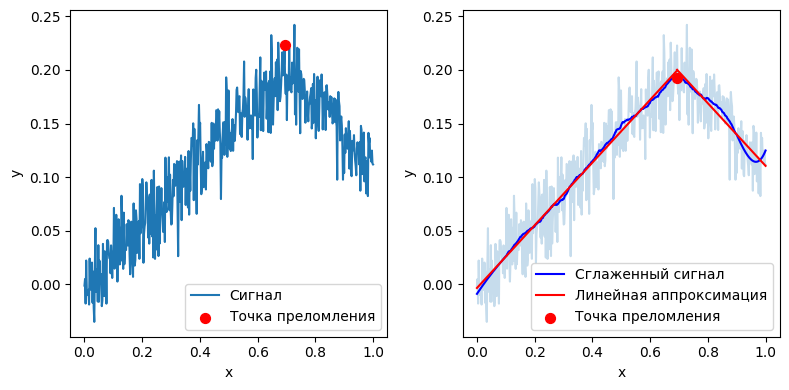

In [20]:
# ==============================================================================
# TEST CODE
# ==============================================================================
set_inline_backend()

t = np.linspace(0, 1, 500)
# clean = np.where(t < 0.4, 0.5*t, 0.2 + 0.1*(t-0.4))  # Излом в t=0.4
clean = np.where(t < 0.7, 0.2/0.7*t, 0.2 + -0.3*(t-0.7))  # Излом в t=0.7
noisy = clean + np.random.normal(0, 0.02, size=t.shape)

smoothed = savgol_filter(noisy, window_length=101, polyorder=3)

min_seg_len = 10
index, _ = detect_breakpoint_fastest(smoothed, min_seg_len)

if index != -1:
    print(f"break detected on t = {t[index]:.6f}")

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))

    axes[0].plot(t, noisy, zorder=0, label='Сигнал')
    axes[0].scatter(t[index], noisy[index], s=50, c='red', zorder=1, label='Точка преломления')

    y1 = smoothed[:index]
    y2 = smoothed[index:]
    x1, x2 = np.arange(len(y1)), np.arange(len(y2))
    m1, c1 = np.polyfit(x1, y1, 1)
    m2, c2 = np.polyfit(x2, y2, 1)

    axes[1].plot(t, noisy, alpha=0.25, zorder=0)
    axes[1].plot(t, smoothed, color='blue', zorder=0, label='Сглаженный сигнал')
    axes[1].plot(t[:index], m1*x1 + c1, alpha=1, color='red', zorder=1, label='Линейная аппроксимация')
    axes[1].plot(t[index:], m2*x2 + c2, alpha=1, color='red', zorder=1)
    axes[1].scatter(t[index], smoothed[index], s=50, c='red', zorder=1, label='Точка преломления')

    for ax in [axes[0], axes[1]]:
        ax.set(xlabel='x', ylabel='y')
        ax.legend(loc='lower right')
    
    rss = np.sum((y1 - (m1*x1 + c1))**2) + np.sum((y2 - (m2*x2 + c2))**2)

    plt.tight_layout()
    plt.show()
else:
    print(f"Empty search interval")

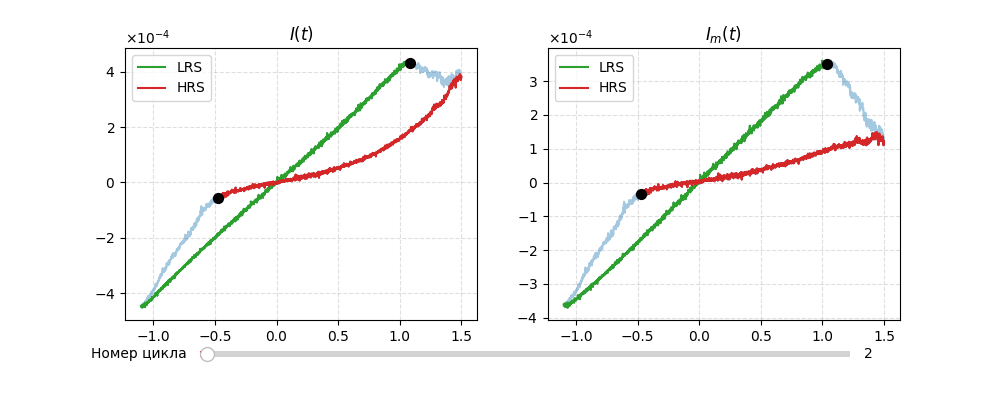

In [43]:
set_widget_backend()
# ==============================================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
plt.subplots_adjust(bottom=0.2)

slider_ax = plt.axes([0.2, 0.1, 0.65, 0.03])
slider = Slider(slider_ax, 'Номер цикла', 1, N_cycles, valinit=1, valstep=1)

def update(val):
    ax1.clear()
    ax2.clear()

    for ax in [ax1, ax2]:
        set_scientific_yaxis(ax)
        ax.grid(True, linestyle='--', alpha=0.4)

    ax1.set_title("$I(t)$")
    ax2.set_title("$I_m(t)$")

    start, end = get_period_indices(arr_v, val - 1 + 1, arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)

    V = arr_v[start : end]
    I = arr_i[start : end]; I_m = arr_i_m[start : end]
    I_smooth = filter_current(I); I_m_smooth = filter_current(I_m)

    V_zeros = arr_v_zeros[(arr_v_zeros >= start) & (arr_v_zeros <= end)] - start
    V0_idx = V_zeros[1]; V_max_idx = np.argmax(V); V_min_idx = np.argmin(V)

    on_index = V_min_idx; off_index = V_max_idx

    set_weights = (5, 0.5)
    reset_weights = (1, 0.5)

    set_index, _ = detect_breakpoint_fastest(I_smooth[V0_idx : V_min_idx + 1], weights=set_weights, x=V[V0_idx : V_min_idx + 1])
    set_index += V0_idx
    reset_index, _ = detect_breakpoint_fastest(I_smooth[ : V_max_idx + 1], weights=reset_weights, x=V[ : V_max_idx + 1])

    mem_set_index, _ = detect_breakpoint_fastest(I_m_smooth[V0_idx : V_min_idx + 1], weights=set_weights, x=V[V0_idx : V_min_idx + 1])
    mem_set_index += V0_idx
    mem_reset_index, _ = detect_breakpoint_fastest(I_m_smooth[ : V_max_idx + 1], weights=reset_weights, x=V[ : V_max_idx + 1])

    for ax, i, set_idx, reset_idx in zip([ax1, ax2], [I, I_m], [set_index, mem_set_index], [reset_index, mem_reset_index]):
        ax.plot(V, i, alpha=0.4, zorder=99)

        if reset_idx != -1:
            ax.scatter(V[reset_idx], i[reset_idx], color='black', s=50, zorder=100)
            ax.plot(
                np.concatenate([V[on_index : ], V[ : reset_idx]], axis=0),
                np.concatenate([i[on_index : ], i[ : reset_idx]], axis=0),
                color='C2', label="LRS", zorder=99)

        if set_idx != -1:
            ax.scatter(V[set_idx], i[set_idx], color='black', s=50, zorder=100)
            ax.plot(V[off_index : set_idx], i[off_index : set_idx], color='C3', label="HRS", zorder=99)
        
        if reset_idx != -1 or set_idx != -1:
            ax.legend(loc='upper left')

    fig.canvas.draw_idle()
    # fig.canvas.draw()

    # output_dir = os.path.join(os.getcwd(), '..', 'temp', 'results', 'set_reset')
    # fig.savefig(os.path.join(output_dir, f"cycle_{val:03d}.png"), dpi=100, bbox_inches='tight')
    # plt.close(fig)

slider.on_changed(update)
slider.set_val(2)

# for i in range(N_cycles):
#     slider.set_val(i + 1)

plt.show()

#### Способ №2. По производной

In [35]:
def detect_breakpoint(
    y: np.ndarray,
    window: int = 101,
    x: np.ndarray = None,
    eps: float = 1e-12,
):
    y = np.asarray(y)

    if x is not None:
        x = np.asarray(x)

        if len(x) != len(y):
            raise ValueError("x and y must have the same length")

        dy = np.gradient(y, x)
    else:
        dy = np.gradient(y)

    n_points = len(y)

    if n_points < 2 * window:
        raise ValueError("Signal is too short for the given window")

    valid_range = range(window, n_points - window + 1)

    best_k = None
    best_score = np.inf

    for k in valid_range:
        dy_left = dy[k - window : k]
        dy_right = dy[k : k + window]

        left_energy = np.mean(dy_left ** 2)
        right_energy = np.mean(dy_right ** 2)

        score = left_energy / (right_energy + eps)

        if score < best_score:
            best_score = score
            best_k = k

    return best_k, best_score

In [39]:
def detect_breakpoint(
    y: np.ndarray,
    min_seg_len: int = 5,
    x: np.ndarray = None,
    eps: float = 1e-12,
):
    """
    Поиск точки излома как границы между активным участком и плато.

    Для каждой точки k считается:
        left_energy  = mean(dy_left ** 2)
        right_energy = mean(dy_right ** 2)

    Критерий:
        score = right_energy / (left_energy + eps)

    Минимизируется score.
    """

    y = np.asarray(y)

    if x is not None:
        x = np.asarray(x)

        if len(x) != len(y):
            raise ValueError("x and y must have the same length")

        dy = np.gradient(y, x)
    else:
        dy = np.gradient(y)

    n_points = len(y)

    if n_points < 2 * min_seg_len:
        raise ValueError("Signal is too short for the given min_seg_len")

    valid_range = range(min_seg_len, n_points - min_seg_len + 1)

    best_k = None
    best_score = np.inf

    for k in valid_range:
        dy_left = dy[:k]
        dy_right = dy[k:]

        left_energy = np.mean(dy_left ** 2)
        right_energy = np.mean(dy_right ** 2)

        score = left_energy / (right_energy + eps)

        if score < best_score:
            best_score = score
            best_k = k

    return best_k, best_score

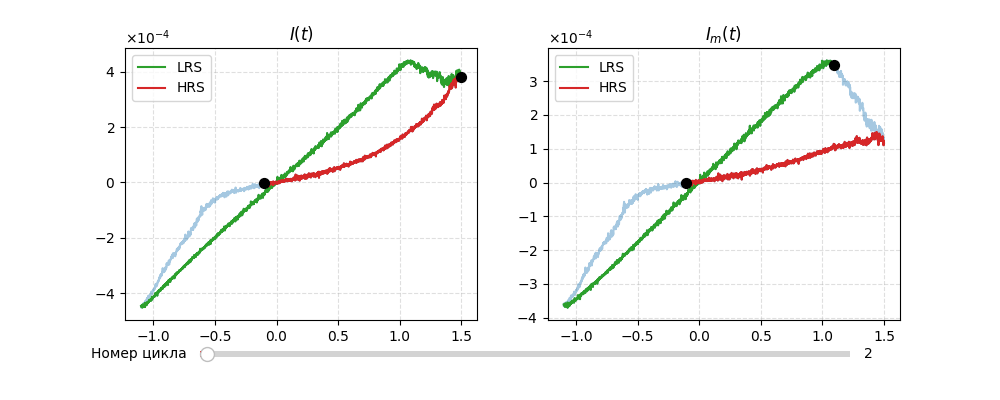

In [40]:
set_widget_backend()
# ==============================================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
plt.subplots_adjust(bottom=0.2)

slider_ax = plt.axes([0.2, 0.1, 0.65, 0.03])
slider = Slider(slider_ax, 'Номер цикла', 1, N_cycles, valinit=1, valstep=1)

def update(val):
    ax1.clear()
    ax2.clear()

    for ax in [ax1, ax2]:
        set_scientific_yaxis(ax)
        ax.grid(True, linestyle='--', alpha=0.4)

    ax1.set_title("$I(t)$")
    ax2.set_title("$I_m(t)$")

    start, end = get_period_indices(arr_v, val - 1 + 1, arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)

    V = arr_v[start : end]
    I = arr_i[start : end]; I_m = arr_i_m[start : end]
    I_smooth = filter_current(I); I_m_smooth = filter_current(I_m)

    V_zeros = arr_v_zeros[(arr_v_zeros >= start) & (arr_v_zeros <= end)] - start
    V0_idx = V_zeros[1]; V_max_idx = np.argmax(V); V_min_idx = np.argmin(V)

    on_index = V_min_idx; off_index = V_max_idx

    set_index, _ = detect_breakpoint(I_smooth[V0_idx : V_min_idx + 1], x=V[V0_idx : V_min_idx + 1])
    set_index += V0_idx
    reset_index, _ = detect_breakpoint(I_smooth[ : V_max_idx + 1], x=V[ : V_max_idx + 1])

    mem_set_index, _ = detect_breakpoint(I_m_smooth[V0_idx : V_min_idx + 1], x=V[V0_idx : V_min_idx + 1])
    mem_set_index += V0_idx
    mem_reset_index, _ = detect_breakpoint(I_m_smooth[ : V_max_idx + 1], x=V[ : V_max_idx + 1])

    for ax, i, set_idx, reset_idx in zip([ax1, ax2], [I, I_m], [set_index, mem_set_index], [reset_index, mem_reset_index]):
        ax.plot(V, i, alpha=0.4, zorder=99)

        if reset_idx != -1:
            ax.scatter(V[reset_idx], i[reset_idx], color='black', s=50, zorder=100)
            ax.plot(
                np.concatenate([V[on_index : ], V[ : reset_idx]], axis=0),
                np.concatenate([i[on_index : ], i[ : reset_idx]], axis=0),
                color='C2', label="LRS", zorder=99)

        if set_idx != -1:
            ax.scatter(V[set_idx], i[set_idx], color='black', s=50, zorder=100)
            ax.plot(V[off_index : set_idx], i[off_index : set_idx], color='C3', label="HRS", zorder=99)
        
        if reset_idx != -1 or set_idx != -1:
            ax.legend(loc='upper left')

    fig.canvas.draw_idle()
    # fig.canvas.draw()

    # output_dir = os.path.join(os.getcwd(), '..', 'temp', 'results', 'set_reset')
    # fig.savefig(os.path.join(output_dir, f"cycle_{val:03d}.png"), dpi=100, bbox_inches='tight')
    # plt.close(fig)

slider.on_changed(update)
slider.set_val(2)

# for i in range(N_cycles):
#     slider.set_val(i + 1)

plt.show()

#### Способ №2. Анализ производной ($dG/dt$) с обратным трейсингом

In [95]:
def detect_breakpoint(dG: np.ndarray, noise_threshold: float = 0.005):
    # 1. Сглаживаем сигнал для стабильной производной
    # G_smooth = savgol_filter(G_norm, window_length=smooth_window, polyorder=poly_order)
    
    # # Считаем производную (разность между соседними точками)
    # dG = np.gradient(G_smooth)
    
    # Находим самый крутой спад (минимум производной)
    idx_steepest_drop = np.argmin(dG)
    
    # Обратный трейсинг: идем назад от спада, пока не выйдем на плато LRS
    idx = idx_steepest_drop
    for i in range(idx_steepest_drop, 0, -1):
        if abs(dG[i]) < noise_threshold:
            idx = i
            break
            
    return idx

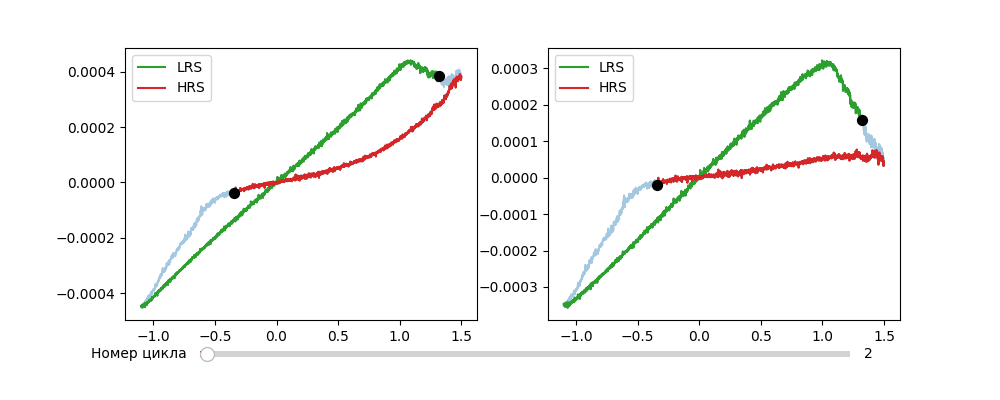

In [97]:
set_widget_backend()
# ==============================================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
plt.subplots_adjust(bottom=0.2)

slider_ax = plt.axes([0.2, 0.1, 0.65, 0.03])
slider = Slider(slider_ax, 'Номер цикла', 1, N_cycles, valinit=1, valstep=1)

def update(val):
    ax1.clear()
    ax2.clear()

    start, end = get_period_indices(arr_v, val - 1 + 1, arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)

    V = arr_v[start : end]
    I = arr_i[start : end]; I_m = arr_i_m[start : end]
    # I_smooth = filter_current(I); I_m_smooth = filter_current(I_m)

    V_zeros = arr_v_zeros[(arr_v_zeros >= start) & (arr_v_zeros <= end)] - start
    V0_idx = V_zeros[1]; V_max_idx = np.argmax(V); V_min_idx = np.argmin(V)

    on_index = V_min_idx; off_index = V_max_idx

    break_length = int(0.075 * len(V)) + 1
    G = calculate_G(V, I); G_m = calculate_G(V, I_m)
    for g in [G, G_m]:
        interpolate_break_with_line(g, 0, break_length)
        interpolate_break_with_line(g, V0_idx, break_length)
        interpolate_break_with_line(g, len(V) - 1, break_length)

    G_smooth = savgol_filter(G, window_length=101, polyorder=3)
    G_m_smooth = savgol_filter(G, window_length=101, polyorder=3)

    G_on = np.max(G_smooth); G_off = np.min(G_smooth)
    G_norm = (G_smooth - G_off) / (G_on - G_off)
    G_m_on = np.max(G_m_smooth); G_m_off = np.min(G_m_smooth)
    G_m_norm = (G_m_smooth - G_m_off) / (G_m_on - G_m_off)

    dG = np.gradient(G_norm)
    dG_m = np.gradient(G_m_norm)

    set_index = detect_breakpoint(dG[V0_idx : V_min_idx + 1], noise_threshold=0.005)
    set_index += V0_idx
    reset_index = detect_breakpoint(dG[ : V_max_idx + 1], noise_threshold=0.005)

    mem_set_index = detect_breakpoint(dG_m[V0_idx : V_min_idx + 1], noise_threshold=0.005)
    mem_set_index += V0_idx
    mem_reset_index = detect_breakpoint(dG_m[ : V_max_idx + 1], noise_threshold=0.005)

    for ax, i, set_idx, reset_idx in zip([ax1, ax2], [I, I_m], [set_index, mem_set_index], [reset_index, mem_reset_index]):
        ax.plot(V, i, alpha=0.4, zorder=0)

        if reset_idx != -1:
            ax.scatter(V[reset_idx], i[reset_idx], color='black', s=50, zorder=1)
            ax.plot(
                np.concatenate([V[on_index : ], V[ : reset_idx]], axis=0),
                np.concatenate([i[on_index : ], i[ : reset_idx]], axis=0),
                color='C2', label="LRS", zorder=0)

        if set_idx != -1:
            ax.scatter(V[set_idx], i[set_idx], color='black', s=50, zorder=1)
            ax.plot(V[off_index : set_idx], i[off_index : set_idx], color='C3', label="HRS", zorder=0)
        
        if reset_idx != -1 or set_idx != -1:
            ax.legend(loc='upper left')

    fig.canvas.draw_idle()

slider.on_changed(update)
slider.set_val(2)

plt.show()

In [ ]:
def detect_onset_deviation(smoothed_signal: np.ndarray, base_window: int = 50, threshold: float = 3.0):
    """
    base_window: количество точек в начале сигнала, которые гарантированно являются "плато".
    threshold: во сколько раз падение должно превышать уровень шума, чтобы считаться изломом.
    """
    # 1. Строим базовую линию по начальному участку
    x_base = np.arange(base_window)
    y_base = smoothed_signal[:base_window]
    m, c = np.polyfit(x_base, y_base, 1)
    
    # 2. Оцениваем стандартное отклонение (уровень шума) на плато
    noise_std = np.std(y_base - (m * x_base + c))
    
    # 3. Идем по сигналу и ищем "точку отрыва"
    for i in range(base_window, len(smoothed_signal)):
        expected_y = m * i + c
        
        # Если сигнал просел относительно предсказанной прямой больше, чем порог шума
        if (expected_y - smoothed_signal[i]) > threshold * noise_std:
            return i # Это и будет ваша красная стрелка
            
    return None

In [ ]:
set_widget_backend()
# ==============================================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
plt.subplots_adjust(bottom=0.2)

slider_ax = plt.axes([0.2, 0.1, 0.65, 0.03])
slider = Slider(slider_ax, 'Номер цикла', 1, N_cycles, valinit=1, valstep=1)

def update(val):
    ax1.clear()
    ax2.clear()

    start, end = get_period_indices(arr_v, val - 1 + 1, arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)

    V = arr_v[start : end]
    I = arr_i[start : end]; I_m = arr_i_m[start : end]
    
    G = calculate_G(V, I); G_m = calculate_G(V, I_m)
    
    break_length = int(0.075 * len(V))
    for g in [G, G_m]:
        interpolate_break_with_line(g, 0, break_length)
        interpolate_break_with_line(g, V0_idx, break_length)
        interpolate_break_with_line(g, len(V) - 1, break_length)

    V_zeros = arr_v_zeros[(arr_v_zeros >= start) & (arr_v_zeros <= end)] - start
    V0_idx = V_zeros[1]; V_max_idx = np.argmax(V); V_min_idx = np.argmin(V)

    on_index = V_min_idx; off_index = V_max_idx

    set_index, _ = detect_onset_deviation([V0_idx : V_min_idx + 1])
    set_index += V0_idx
    reset_index, _ = detect_breakpoint_fastest(I_smooth[ : V_max_idx + 1])

    mem_set_index, _ = detect_breakpoint_fastest(I_m_smooth[V0_idx : V_min_idx + 1])
    mem_set_index += V0_idx
    mem_reset_index, _ = detect_breakpoint_fastest(I_m_smooth[ : V_max_idx + 1])    

    for ax, i, set_idx, reset_idx in zip([ax1, ax2], [I, I_m], [set_index, mem_set_index], [reset_index, mem_reset_index]):
        ax.plot(V, i, alpha=0.4, zorder=0)

        if reset_idx != -1:
            ax.scatter(V[reset_idx], i[reset_idx], color='black', s=50, zorder=1)
            ax.plot(
                np.concatenate([V[on_index : ], V[ : reset_idx]], axis=0),
                np.concatenate([i[on_index : ], i[ : reset_idx]], axis=0),
                color='C2', label="LRS", zorder=0)

        if set_idx != -1:
            ax.scatter(V[set_idx], i[set_idx], color='black', s=50, zorder=1)
            ax.plot(V[off_index : set_idx], i[off_index : set_idx], color='C3', label="HRS", zorder=0)
        
        if reset_idx != -1 or set_idx != -1:
            ax.legend(loc='upper left')

    fig.canvas.draw_idle()

slider.on_changed(update)
slider.set_val(2)

plt.show()

#### Способ №3. Детекция флуктуаций

In [21]:
import ruptures as rpt

In [120]:
np.random.seed(42)
N = 5000
t = np.linspace(0, 5, N)

# Базовый стохастический шум ("затишье")
signal = np.random.normal(0, 0.005, N) 

# Известные точки конца всплесков (Черные стрелки)
black_1 = 1600
black_2 = 4100

# Истинные точки начала всплесков (Красные стрелки) - для проверки алгоритмов
true_red_1 = 1200
true_red_2 = 3800

# Генерируем всплески с переменной амплитудой
burst_1_len = black_1 - true_red_1
signal[true_red_1:black_1] += np.random.normal(0, 0.08, burst_1_len) * np.linspace(0.1, 1, burst_1_len)

burst_2_len = black_2 - true_red_2
signal[true_red_2:black_2] += np.random.normal(0, 0.05, burst_2_len) * np.linspace(1, 0.2, burst_2_len)

# Разбиваем на два рабочих среза:
# Срез 1: от начала до первой черной точки
slice_1 = signal[0:black_1]
# Срез 2: от первой черной точки до второй черной точки
slice_2 = signal[black_1:black_2]

In [23]:
# 2. РЕАЛИЗАЦИЯ АЛГОРИТМОВ
# ==========================================

def algo_1_knee(sig):
    """Метод 'Колена' по кумулятивной энергии"""
    energy = sig**2
    cum_energy = np.cumsum(energy)
    
    # Прямая линия от старта до финиша: Ax + By + C = 0
    x = np.arange(len(cum_energy))
    x1, y1 = x[0], cum_energy[0]
    x2, y2 = x[-1], cum_energy[-1]
    
    A = y2 - y1
    B = -(x2 - x1)
    C = x2 * y1 - y2 * x1
    
    # Считаем перпендикулярное расстояние от каждой точки кривой до прямой
    distances = np.abs(A * x + B * cum_energy + C) / np.sqrt(A**2 + B**2)
    
    # Точка излома - максимальное отдаление от прямой
    return np.argmax(distances), cum_energy

def algo_2_moving_variance(sig, window=25, k_sigma=5):
    """Скользящее окно с адаптивным порогом"""
    weights = np.ones(window) / window
    # Считаем скользящую энергию (дисперсию нулевого среднего)
    moving_energy = np.convolve(sig**2, weights, mode='valid')
    
    # Калибруемся по начальному "тихому" участку (предполагаем, что первые 200 точек - тишина)
    calib_mean = np.mean(moving_energy[:200])
    calib_std = np.std(moving_energy[:200])
    threshold = calib_mean + k_sigma * calib_std
    
    # Ищем первое стабильное превышение порога
    crossings = np.where(moving_energy > threshold)[0]
    if len(crossings) > 0:
        return crossings[0] + window // 2, moving_energy, threshold
    return 0, moving_energy, threshold

def algo_3_ruptures(sig):
    """Статистический Change-Point Detection (CUSUM / L2)"""
    # Используем модуль сигнала, чтобы искать изменение амплитуды флуктуаций
    algo = rpt.Binseg(model="l2", jump=5).fit(np.abs(sig))
    result = algo.predict(n_bkps=1)
    return result[0]

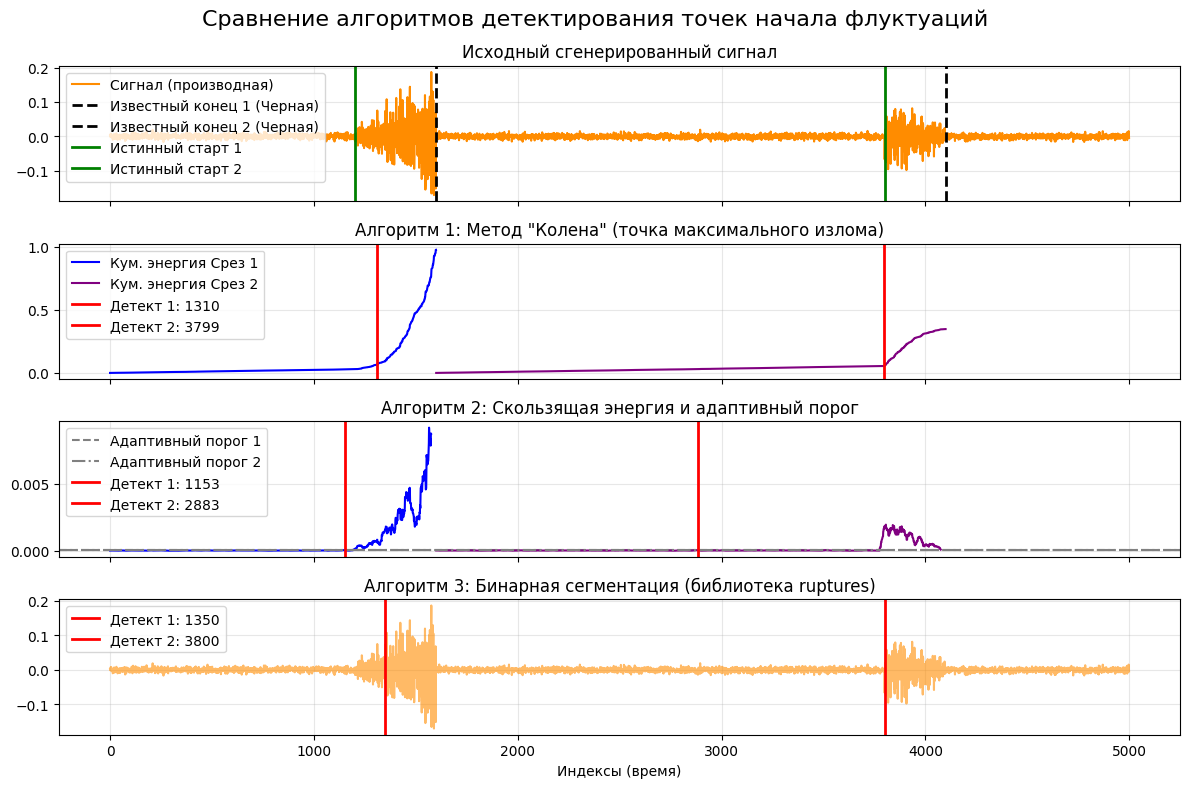

In [25]:
# 3. ПРИМЕНЕНИЕ АЛГОРИТМОВ
# ==========================================

# Поиск Красной 1 (на slice_1)
p1_1, cum1 = algo_1_knee(slice_1)
p2_1, mov1, thr1 = algo_2_moving_variance(slice_1)
p3_1 = algo_3_ruptures(slice_1)

# Поиск Красной 2 (на slice_2, не забываем прибавить offset=black_1)
p1_2, cum2 = algo_1_knee(slice_2)
p2_2, mov2, thr2 = algo_2_moving_variance(slice_2)
p3_2 = algo_3_ruptures(slice_2)

p1_2 += black_1
p2_2 += black_1
p3_2 += black_1


# ==========================================
# 4. ВИЗУАЛИЗАЦИЯ (Subplots)
# ==========================================
fig, axs = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
fig.suptitle('Сравнение алгоритмов детектирования точек начала флуктуаций', fontsize=16)

# --- График 1: Исходный сигнал ---
axs[0].plot(signal, color='darkorange', label='Сигнал (производная)')
axs[0].axvline(black_1, color='black', linestyle='--', lw=2, label='Известный конец 1 (Черная)')
axs[0].axvline(black_2, color='black', linestyle='--', lw=2, label='Известный конец 2 (Черная)')
axs[0].axvline(true_red_1, color='green', lw=2, label='Истинный старт 1')
axs[0].axvline(true_red_2, color='green', lw=2, label='Истинный старт 2')
axs[0].set_title('Исходный сгенерированный сигнал')
axs[0].legend(loc='upper left')
axs[0].grid(True, alpha=0.3)

# --- График 2: Алгоритм 1 (Кумулятивная энергия) ---
axs[1].plot(np.arange(len(cum1)), cum1, color='blue', label='Кум. энергия Срез 1')
axs[1].plot(np.arange(black_1, black_1 + len(cum2)), cum2, color='purple', label='Кум. энергия Срез 2')
axs[1].axvline(p1_1, color='red', lw=2, label=f'Детект 1: {p1_1}')
axs[1].axvline(p1_2, color='red', lw=2, label=f'Детект 2: {p1_2}')
axs[1].set_title('Алгоритм 1: Метод "Колена" (точка максимального излома)')
axs[1].legend(loc='upper left')
axs[1].grid(True, alpha=0.3)

# --- График 3: Алгоритм 2 (Скользящее окно) ---
axs[2].plot(np.arange(len(mov1)), mov1, color='blue')
axs[2].axhline(thr1, color='gray', linestyle='--', label='Адаптивный порог 1')
axs[2].plot(np.arange(black_1, black_1 + len(mov2)), mov2, color='purple')
axs[2].axhline(thr2, color='gray', linestyle='-.', label='Адаптивный порог 2')
axs[2].axvline(p2_1, color='red', lw=2, label=f'Детект 1: {p2_1}')
axs[2].axvline(p2_2, color='red', lw=2, label=f'Детект 2: {p2_2}')
axs[2].set_title('Алгоритм 2: Скользящая энергия и адаптивный порог')
axs[2].legend(loc='upper left')
axs[2].grid(True, alpha=0.3)

# --- График 4: Алгоритм 3 (Ruptures) ---
axs[3].plot(signal, color='darkorange', alpha=0.6)
axs[3].axvline(p3_1, color='red', lw=2, label=f'Детект 1: {p3_1}')
axs[3].axvline(p3_2, color='red', lw=2, label=f'Детект 2: {p3_2}')
axs[3].set_title('Алгоритм 3: Бинарная сегментация (библиотека ruptures)')
axs[3].legend(loc='upper left')
axs[3].grid(True, alpha=0.3)

plt.xlabel('Индексы (время)')
plt.tight_layout()
plt.show()

$$I = \phi I_M(V,t) + (1 - \phi)I_S(V)$$

$$I_S = \alpha_f e^{\beta_f V} - \alpha_r e^{\beta_r V}$$

#### Итог

In [25]:
def detect_set(V, I, on_index, V0_index, k=1.0, starts_with_hrs=True):
    if starts_with_hrs:
        index, _ = detect_breakpoint_fastest(I[0 : on_index + 1], weights=(k, 1.0), x=V[0 : on_index + 1])
        return index
    else:
        index, _ = detect_breakpoint_fastest(I[V0_index : on_index + 1], weights=(k, 1.0), x=V[V0_index : on_index + 1])
        return V0_index + index

# ==============================================================================

def detect_reset(V, I, off_index, V0_index, k=1.0, starts_with_hrs=True):
    if starts_with_hrs:
        index, _ = detect_breakpoint_fastest(I[V0_index : off_index + 1], weights=(k, 1.0), x=V[V0_index : off_index + 1])
        return V0_index + index
    else:
        index, _ = detect_breakpoint_fastest(I[0 : off_index + 1], weights=(k, 1.0), x=V[0 : off_index + 1])
        return index

## Алгоритм поиска параметров тока Шоттки

### Анализ поведения

In [54]:
# Подготовка данных

# Извлекаем 2-й цикл ВАХ-ки
start, end = get_period_indices(arr_v, 1, segments_per_period=2, period_start_segment_idx=0)
# Находим нули и экстремумы
zero_indices = np.concatenate([[0], get_zero_indices(V[1 : -1]), [len(V) - 1]], axis=0)
peak_indices, _ = find_peaks(V); peak_index = peak_indices[0]
valley_indices, _ = find_peaks(-V); valley_index = valley_indices[0]
# Извлекаем ток и напряжение
T = arr_t[start : end]
I = arr_i[start : end]; V = arr_v[start : end]; G = arr_g[start : end]

# Вариант №1. min-max нормализация (НЕ СОХРАНЯЕТ ФОРМУ G(t))
# I_min = np.min(I); I_max = np.max(I)
# V_min = np.min(V); V_max = np.max(V)
# I_normalized = 2 * (I - I_min) / (I_max - I_min) - 1
# V_normalized = 2 * (V - V_min) / (V_max - V_min) - 1

# Вариант №2. min-max нормализация отдельно по положительной и отрицательной областям (НЕ СОХРАНЯЕТ ФОРМУ G(t))
# I_normalized = np.zeros_like(I)
# pos, neg = I > 0, I < 0
# if pos.any(): I_normalized[pos] = I[pos] / I[pos].max()
# if neg.any(): I_normalized[neg] = I[neg] / np.abs(I[neg].min())
# V_normalized = np.zeros_like(V)
# pos, neg = V > 0, V < 0
# if pos.any(): V_normalized[pos] = V[pos] / V[pos].max()
# if neg.any(): V_normalized[neg] = V[neg] / np.abs(V[neg].min())

# Вариант №3. max-нормализация (СОХРАНЯЕТ ФОРМУ G(t))
I_max = np.max(np.abs(I))
I_normalized = I / I_max
V_max = np.max(np.abs(V))
V_normalized = V / V_max

# Проводимость
G = np.empty_like(V)
np.divide(I_normalized, V_normalized, out=G, where=(V_normalized != 0))
G[V_normalized == 0] = np.inf

In [55]:
param_ranges = {
    'phi': (0.9, 1, 0.0001),
    
    # 'a_f': (1e-6, 1e-2, 1e-6),
    'a_f': (1e-3, 1e0, 1e-6),
    
    # 'a_r': (1e-6, 1e-2, 1e-6),
    'a_r': (1e-3, 1e0, 1e-6),
    
    'b_f': (5, 10, 0.01),
    # 'b_f': (-10, 10, 0.01),
    
    'b_r': (-10, -5, 0.01)
    # 'b_r': (-10, 10, 0.01)
}

init_params = {
    'phi': 0.995,
    'a_f': 0.021,
    'a_r': 0.0224,
    'b_f': 9.84,
    'b_r': -9.71
}

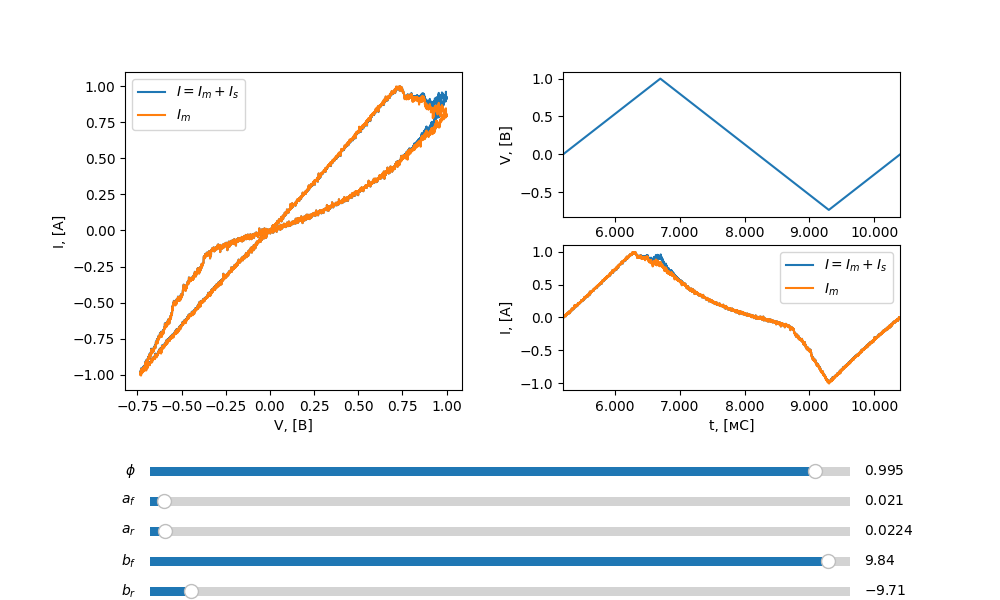

In [56]:
set_widget_backend()
# ==============================================================================

fig = plt.figure(figsize=(10, 6))
ax_vah = plt.subplot2grid((2, 2), (0, 0), rowspan=2)
ax_v = plt.subplot2grid((2, 2), (0, 1), colspan=1)
ax_i = plt.subplot2grid((2, 2), (1, 1), colspan=1, sharex=ax_v)
plt.subplots_adjust(bottom=0.35, wspace=0.3)

ax_v.plot(T, V_normalized)
ax_i.set_xlim(T[0], T[-1])
ax_v.set_xlim(T[0], T[-1])

ax_i.set_xlabel("t, [мС]"); ax_i.set_ylabel("I, [А]")
ax_v.set_ylabel("V, [В]")
ax_vah.set_xlabel("V, [В]"); ax_vah.set_ylabel("I, [А]")
ax_v.xaxis.set_major_formatter(formatter_to_mS)
ax_i.xaxis.set_major_formatter(formatter_to_mS)

slider_phi_ax = plt.axes([0.15, 0.2, 0.7, 0.03])
slider_a_f_ax = plt.axes([0.15, 0.15, 0.7, 0.03])
slider_a_r_ax = plt.axes([0.15, 0.1, 0.7, 0.03])
slider_b_f_ax = plt.axes([0.15, 0.05, 0.7, 0.03])
slider_b_r_ax = plt.axes([0.15, 0.0, 0.7, 0.03])
# =====
slider_phi = Slider(slider_phi_ax, r'$\phi$', param_ranges['phi'][0], param_ranges['phi'][1], valinit=init_params['phi'], valstep=param_ranges['phi'][2])
slider_a_f = Slider(slider_a_f_ax, r'$a_f$', param_ranges['a_f'][0], param_ranges['a_f'][1], valinit=init_params['a_f'], valstep=param_ranges['a_f'][2])
slider_a_r = Slider(slider_a_r_ax, r'$a_r$', param_ranges['a_r'][0], param_ranges['a_r'][1], valinit=init_params['a_r'], valstep=param_ranges['a_r'][2])
slider_b_f = Slider(slider_b_f_ax, r'$b_f$', param_ranges['b_f'][0], param_ranges['b_f'][1], valinit=init_params['b_f'], valstep=param_ranges['b_f'][2])
slider_b_r = Slider(slider_b_r_ax, r'$b_r$', param_ranges['b_r'][0], param_ranges['b_r'][1], valinit=init_params['b_r'], valstep=param_ranges['b_r'][2])

def update(phi, a_f, a_r, b_f, b_r):
    for line in ax_vah.get_lines():
        line.remove()
    for line in ax_i.get_lines():
        line.remove()

    I_s = extract_schottky_current(V_normalized, a_f, a_r, b_f, b_r)
    I_m = extract_memristive_current(I_normalized, phi, I_s)

    ax_i.plot(T, I_normalized, color='C0', label=r'$I = I_m + I_s$')
    ax_i.plot(T, I_m, color='C1', label=r'$I_m$')
    ax_vah.plot(V_normalized, I_normalized, color='C0', label=r'$I = I_m + I_s$')
    ax_vah.plot(V_normalized, I_m, color='C1', label=r'$I_m$')

    for ax in [ax_vah, ax_i]:
        ax.relim()
        ax.legend()

    fig.canvas.draw_idle()

def update_phi(val):
    update(val, slider_a_f.val, slider_a_r.val, slider_b_f.val, slider_b_r.val)
def update_a_f(val):
    update(slider_phi.val, val, slider_a_r.val, slider_b_f.val, slider_b_r.val)
def update_a_r(val):
    update(slider_phi.val, slider_a_f.val, val, slider_b_f.val, slider_b_r.val)
def update_b_f(val):
    update(slider_phi.val, slider_a_f.val, slider_a_r.val, val, slider_b_r.val)
def update_b_r(val):
    update(slider_phi.val, slider_a_f.val, slider_a_r.val, slider_b_f.val, val)
    
slider_phi.on_changed(update_phi)
slider_a_f.on_changed(update_a_f)
slider_a_r.on_changed(update_a_r)
slider_b_f.on_changed(update_b_f)
slider_b_r.on_changed(update_b_r)

update(init_params['phi'], init_params['a_f'], init_params['a_r'], init_params['b_f'], init_params['b_r'])

plt.show()

$$I = \phi I_M(V,t) + (1 - \phi)I_S(V)$$

$$I_S = \alpha_f e^{\beta_f V} - \alpha_r e^{\beta_r V}$$

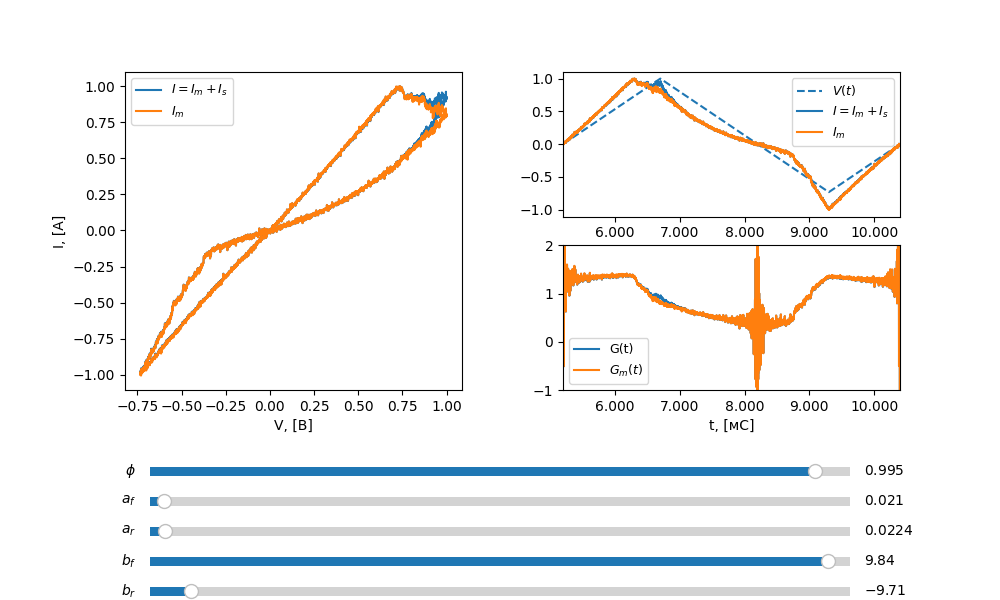

In [153]:
set_widget_backend()
# ==============================================================================

fig = plt.figure(figsize=(10, 6))
ax_vah = plt.subplot2grid((2, 2), (0, 0), rowspan=2)
ax_v_i = plt.subplot2grid((2, 2), (0, 1), colspan=1)
ax_g = plt.subplot2grid((2, 2), (1, 1), colspan=1, sharex=ax_v_i)
plt.subplots_adjust(bottom=0.35, wspace=0.3)

ax_g.set_xlim(T[0], T[-1])
ax_v_i.set_xlim(T[0], T[-1])

ax_g.set(xlabel="t, [мС]")
ax_vah.set(xlabel="V, [В]", ylabel="I, [А]")
ax_v.xaxis.set_major_formatter(formatter_to_mS)
ax_i.xaxis.set_major_formatter(formatter_to_mS)
ax_g.xaxis.set_major_formatter(formatter_to_mS)

slider_phi_ax = plt.axes([0.15, 0.2, 0.7, 0.03])
slider_a_f_ax = plt.axes([0.15, 0.15, 0.7, 0.03])
slider_a_r_ax = plt.axes([0.15, 0.1, 0.7, 0.03])
slider_b_f_ax = plt.axes([0.15, 0.05, 0.7, 0.03])
slider_b_r_ax = plt.axes([0.15, 0.0, 0.7, 0.03])
# =====
slider_phi = Slider(slider_phi_ax, r'$\phi$', param_ranges['phi'][0], param_ranges['phi'][1], valinit=init_params['phi'], valstep=param_ranges['phi'][2])
slider_a_f = Slider(slider_a_f_ax, r'$a_f$', param_ranges['a_f'][0], param_ranges['a_f'][1], valinit=init_params['a_f'], valstep=param_ranges['a_f'][2])
slider_a_r = Slider(slider_a_r_ax, r'$a_r$', param_ranges['a_r'][0], param_ranges['a_r'][1], valinit=init_params['a_r'], valstep=param_ranges['a_r'][2])
slider_b_f = Slider(slider_b_f_ax, r'$b_f$', param_ranges['b_f'][0], param_ranges['b_f'][1], valinit=init_params['b_f'], valstep=param_ranges['b_f'][2])
slider_b_r = Slider(slider_b_r_ax, r'$b_r$', param_ranges['b_r'][0], param_ranges['b_r'][1], valinit=init_params['b_r'], valstep=param_ranges['b_r'][2])

def update(phi, a_f, a_r, b_f, b_r):
    for line in ax_vah.get_lines():
        line.remove()
    for line in ax_v_i.get_lines():
        line.remove()
    for line in ax_g.get_lines():
        line.remove()

    I_s = extract_schottky_current(V_normalized, a_f, a_r, b_f, b_r)
    I_m = extract_memristive_current(I_normalized, phi, I_s)

    # Проводимость и мемдуктивность
    G_m = np.empty_like(V)
    np.divide(I_m, V_normalized, out=G_m, where=(V_normalized != 0))
    G_m[V_normalized == 0] = np.inf

    ax_v_i.plot(T, V_normalized, color="C0", linestyle='--', label='$V(t)$')
    ax_v_i.plot(T, I_normalized, color='C0', label=r'$I = I_m + I_s$')
    ax_v_i.plot(T, I_m, color='C1', label=r'$I_m$')
    ax_g.plot(T, G, label='G(t)', color="C0")
    ax_g.plot(T, G_m, label='$G_m(t)$', color="C1")
    ax_vah.plot(V_normalized, I_normalized, color='C0', label=r'$I = I_m + I_s$')
    ax_vah.plot(V_normalized, I_m, color='C1', label=r'$I_m$')

    # set_scientific_yaxis(ax_g)
    ax_g.set_ylim(-1, 2)

    for ax in [ax_vah, ax_v_i, ax_g]:
        ax.relim()
        ax.legend(fontsize=9)

    fig.canvas.draw_idle()

def update_phi(val):
    update(val, slider_a_f.val, slider_a_r.val, slider_b_f.val, slider_b_r.val)
def update_a_f(val):
    update(slider_phi.val, val, slider_a_r.val, slider_b_f.val, slider_b_r.val)
def update_a_r(val):
    update(slider_phi.val, slider_a_f.val, val, slider_b_f.val, slider_b_r.val)
def update_b_f(val):
    update(slider_phi.val, slider_a_f.val, slider_a_r.val, val, slider_b_r.val)
def update_b_r(val):
    update(slider_phi.val, slider_a_f.val, slider_a_r.val, slider_b_f.val, val)
    
slider_phi.on_changed(update_phi)
slider_a_f.on_changed(update_a_f)
slider_a_r.on_changed(update_a_r)
slider_b_f.on_changed(update_b_f)
slider_b_r.on_changed(update_b_r)

update(init_params['phi'], init_params['a_f'], init_params['a_r'], init_params['b_f'], init_params['b_r'])

plt.show()

### Оптимизация v.1

__Идея:__

* Задача оптимизации: минимизация кривизны секции HRS на графике ВАХ-ки.
* Условие: максимальное отклонение произвольной точки в секциях SET + LRS не превышает 0.01 [мА] (значение подобрано эмпирически).

In [ ]:
def target_function(V, I, phi, a_f, a_r, b_f, b_r, peak_index, mid_zero_index, valley_index, lrs_end_index, hrs_end_index, tol=1e-3, penalty=1e-4):
    I_s = extract_schottky_current(V, a_f, a_r, b_f, b_r)
    I_m = extract_memristive_current(I, phi, I_s)

    # get HRS by pass only smoothed snippet of the I_m (faster that smooth and pass whole I_m)
    I_m_third_section_smoothed = I_m[mid_zero_index : valley_index + 1]# filter_current(I_m[mid_zero_index : valley_index + 1])
    I_m_hrs_end_index = mid_zero_index + detect_set_index(I_m_third_section_smoothed, mid_zero_index=0, valley_index=(valley_index - mid_zero_index))

    I_m_HRS = I_m[peak_index : I_m_hrs_end_index]
    I_SET = I[hrs_end_index : valley_index]
    I_LRS = np.concatenate([I[valley_index : ], I[ : lrs_end_index]], axis=0)
    I_m_SET = I_m[hrs_end_index : valley_index]
    I_m_LRS = np.concatenate([I_m[valley_index : ], I_m[ : lrs_end_index]], axis=0)

    # calculate RSS(HRS) — RSS of HRS-curve
    # x = np.arange(len(I_m_HRS))
    # m, c = np.polyfit(x, I_m_HRS, 1)
    # rss = np.sum((I_m_HRS - (m*x + c))**2)
    V_m_HRS = V[peak_index : I_m_hrs_end_index]
    m, c = np.polyfit(V_m_HRS, I_m_HRS, 1)
    rss = np.sum((I_m_HRS - (m*V_m_HRS + c))**2)
    
    # calculate dev_max(SET + LRS) — maximum deviation of intervals SET + LRS
    dev_set = np.abs(I_m_SET - I_SET)
    dev_lrs = np.abs(I_m_LRS - I_LRS)
    max_dev = max(np.max(dev_set), np.max(dev_lrs))
    violation = np.maximum(0, max_dev - tol)

    return rss + penalty * (violation ** 2)

In [ ]:
# Подготовка тестовых данных

# Считываем 2-й цикл ВАХ-ки
start, end = get_period_indices(arr_v, 1, segments_per_period=2, period_start_segment_idx=0)
I = arr_i[start : end]; V = arr_v[start : end]; I_smoothed = filter_current(I, high_smooth=True)
T = arr_t[start : end]

# Находим нули и экстремумы
mid_zero_index = get_zero_indices(V[1 : -1])[0]
zero_indices = np.concatenate([[0], [mid_zero_index], [len(V) - 1]], axis=0)
peak_indices, _ = find_peaks(V);        peak_index = peak_indices[0]
valley_indices, _ = find_peaks(-V);     valley_index = valley_indices[0]

# Нормализация
I_max = np.max(np.abs(I))
I_normalized = I / I_max
V_max = np.max(np.abs(V))
V_normalized = V / V_max

# Проводиомсть
G = np.empty_like(V)
np.divide(I, V, out=G, where=(V != 0))
G[V == 0] = np.inf

# Находим обалсти LRS, HRS
lrs_end_index = detect_reset_index(I_smoothed, peak_index=peak_index)
hrs_end_index = detect_set_index(I_smoothed, valley_index=valley_index, mid_zero_index=mid_zero_index)

In [63]:
# Вычисление целевой функции при изменении каждого параметра при фиксации всех остальных
# (грубая оценка поведения целевой функции)

init_params = {
    'phi': 0.995,
    'a_f': 0.021,
    'a_r': 0.0224,
    'b_f': 9.84,
    'b_r': -9.71
}

param_ranges = {
    'phi': (0.99, 1, 0.001),
    'a_f': (1e-3, 1e0, 1e-4),
    'a_r': (1e-3, 1e0, 1e-4),
    'b_f': (5, 10, 0.01),
    'b_r': (-10, -5, 0.01)
}

phi_values = np.arange(param_ranges['phi'][0], param_ranges['phi'][1] + 1e-9, param_ranges['phi'][2])
a_f_values = np.arange(param_ranges['a_f'][0], param_ranges['a_f'][1] + 1e-9, param_ranges['a_f'][2])
a_r_values = np.arange(param_ranges['a_r'][0], param_ranges['a_r'][1] + 1e-9, param_ranges['a_r'][2])
b_f_values = np.arange(param_ranges['b_f'][0], param_ranges['b_f'][1] + 1e-9, param_ranges['b_f'][2])
b_r_values = np.arange(param_ranges['b_r'][0], param_ranges['b_r'][1] + 1e-9, param_ranges['b_r'][2])

# ==============================================================================

target_simplified = lambda phi, a_f, a_r, b_f, b_r : target_function(
    V_normalized, I_normalized, phi, a_f, a_r, b_f, b_r, peak_index, mid_zero_index, valley_index, lrs_end_index=lrs_end_index, hrs_end_index=hrs_end_index, 
    tol=0.01, penalty=1e2)

# ==============================================================================

phi_targets = []
for phi in tqdm(phi_values, desc="Phi"):
    target = target_simplified(phi, init_params['a_f'], init_params['a_r'], init_params['b_f'], init_params['b_r'])
    phi_targets += [target]

a_f_targets = []
for a_f in tqdm(a_f_values, desc='a_f'):
    target = target_simplified(init_params['phi'], a_f, init_params['a_r'], init_params['b_f'], init_params['b_r'])
    a_f_targets += [target]

a_r_targets = []
for a_r in tqdm(a_r_values, desc='a_r'):
    target = target_simplified(init_params['phi'], init_params['a_f'], a_r, init_params['b_f'], init_params['b_r'])
    a_r_targets += [target]

b_f_targets = []
for b_f in tqdm(b_f_values, desc='b_f'):
    target = target_simplified(init_params['phi'], init_params['a_f'], init_params['a_r'], b_f, init_params['b_r'])
    b_f_targets += [target]

b_r_targets = []
for b_r in tqdm(b_r_values, desc='b_r'):
    target = target_simplified(init_params['phi'], init_params['a_f'], init_params['a_r'], init_params['b_f'], b_r)
    b_r_targets += [target]

a_f:  15%|█▍        | 1451/9991 [00:03<00:20, 424.32it/s]


KeyboardInterrupt: 

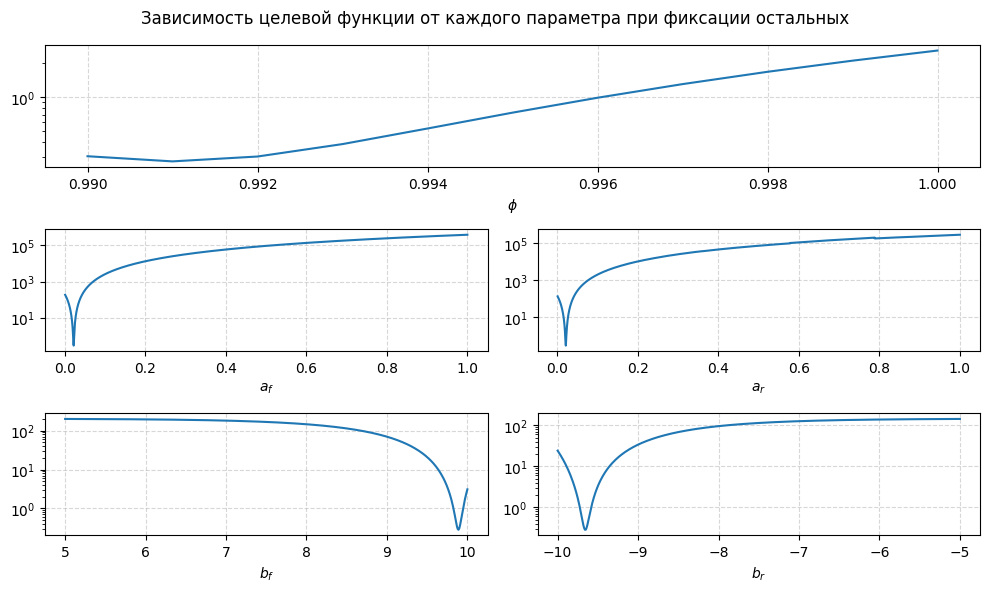

In [ ]:
fig = plt.figure(figsize=(10, 6))
ax_phi = plt.subplot2grid((3, 2), (0, 0), colspan=2)
ax_a_f = plt.subplot2grid((3, 2), (1, 0))
ax_a_r = plt.subplot2grid((3, 2), (1, 1))
ax_b_f = plt.subplot2grid((3, 2), (2, 0))
ax_b_r = plt.subplot2grid((3, 2), (2, 1))
axes = [ax_phi, ax_a_f, ax_a_r, ax_b_f, ax_b_r]
# plt.subplots_adjust(bottom=0.35, wspace=0.3)

ax_phi.plot(phi_values, phi_targets)
ax_phi.set_xlabel(r'$\phi$')

ax_a_f.plot(a_f_values, a_f_targets)
ax_a_f.set_xlabel(r'$a_f$')

ax_a_r.plot(a_r_values, a_r_targets)
ax_a_r.set_xlabel(r'$a_r$')

ax_b_f.plot(b_f_values, b_f_targets)
ax_b_f.set_xlabel(r'$b_f$')

ax_b_r.plot(b_r_values, b_r_targets)
ax_b_r.set_xlabel(r'$b_r$')

for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_yscale('log')

fig.suptitle("Зависимость целевой функции от каждого параметра при фиксации остальных")
plt.tight_layout()
plt.show()

In [ ]:
# Запуск оптимизации

target_simplified = lambda phi, a_f, a_r, b_f, b_r : target_function(
    V_normalized, I_normalized, phi, a_f, a_r, b_f, b_r, peak_index, mid_zero_index, valley_index, lrs_end_index=lrs_end_index, hrs_end_index=hrs_end_index, 
    tol=0.01, penalty=1e3)

# ==============================================================================

param_bounds = [
    (0.9, 1.0),
    (1e-4, 1e1),
    (1e-4, 1e1),
    (0, 10),
    (-10, 0),
]

history = []

def history_callback(intermediate_result):
    history.append(intermediate_result.x)
    # return intermediate_result.fun > 0.01

result = differential_evolution(
    func=lambda p: target_simplified(p[0], p[1], p[2], p[3], p[4]),
    bounds=param_bounds,
    seed=42,
    maxiter=500,
    # atol=0, tol=0,
    callback=history_callback
)

phi, a_f, a_r, b_f, b_r = result.x

print(f"Success = {result.success}")
print(f"phi = {phi}")
print(f"a_f = {a_f}")
print(f"a_r = {a_r}")
print(f"b_f = {b_f}")
print(f"b_r = {b_r}")

print(f"target = {target_simplified(phi, a_f, a_r, b_f, b_r)}")

Success = True
phi = 0.9951592632058518
a_f = 0.69858907905103
a_r = 3.9655057255844715
b_f = 5.219879325179558
b_r = -2.57285257534311
target = 1.2623281853350816


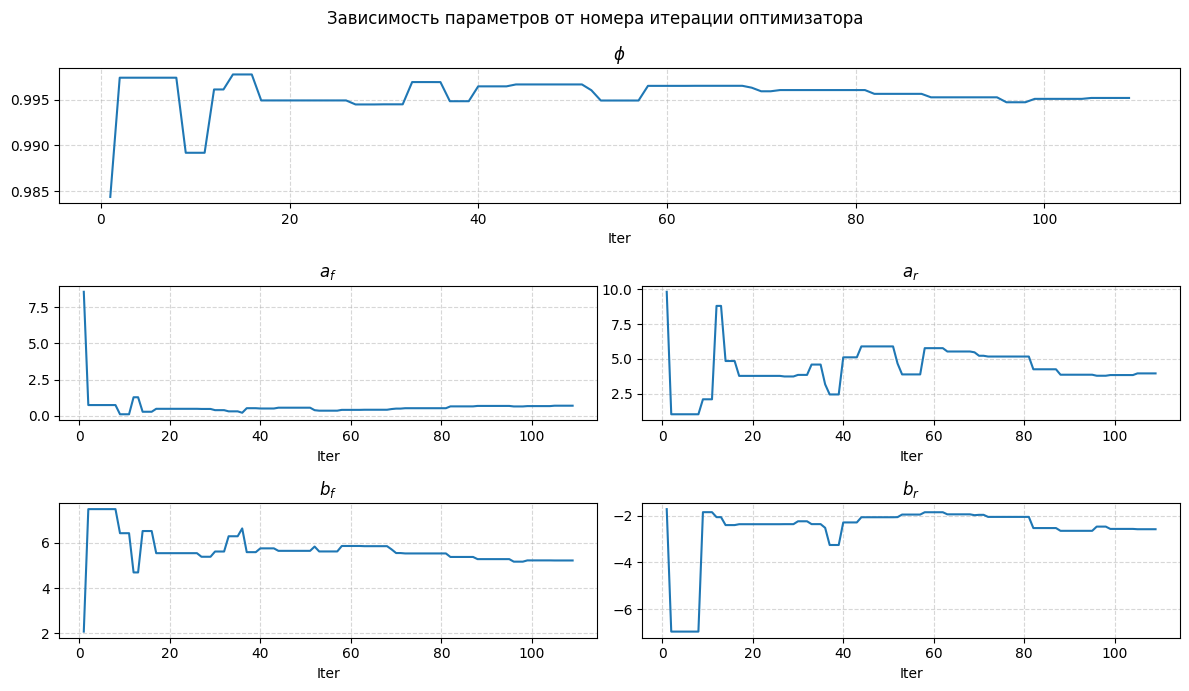

In [ ]:
history = np.array(history)

fig = plt.figure(figsize=(12, 7))
ax_phi = plt.subplot2grid((3, 2), (0, 0), colspan=2)
ax_a_f = plt.subplot2grid((3, 2), (1, 0))
ax_a_r = plt.subplot2grid((3, 2), (1, 1))
ax_b_f = plt.subplot2grid((3, 2), (2, 0))
ax_b_r = plt.subplot2grid((3, 2), (2, 1))
axes = [ax_phi, ax_a_f, ax_a_r, ax_b_f, ax_b_r]

n_iters = history.shape[0]
iters = np.linspace(1, n_iters, n_iters).astype(int)

ax_phi.plot(iters, history[:, 0])
ax_phi.set_title(r'$\phi$')

ax_a_f.plot(iters,  history[:, 1])
ax_a_f.set_title(r'$a_f$')

ax_a_r.plot(iters,  history[:, 2])
ax_a_r.set_title(r'$a_r$')

ax_b_f.plot(iters,  history[:, 3])
ax_b_f.set_title(r'$b_f$')

ax_b_r.plot(iters,  history[:, 4])
ax_b_r.set_title(r'$b_r$')

for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_xlabel("Iter")
    # ax.set_yscale('symlog')

fig.suptitle("Зависимость параметров от номера итерации оптимизатора")
plt.tight_layout()
plt.show()

In [ ]:
phi, a_f, a_r, b_f, b_r = result.x

I_s_normalized = extract_schottky_current(V_normalized, a_f, a_r, b_f, b_r)
I_m_normalized = extract_memristive_current(I_normalized, phi, I_s_normalized)

I_m = I_m_normalized * I_max

G_m = np.empty_like(I_m)
np.divide(I_m, V, out=G_m, where=(V != 0))
G_m[V == 0] = np.inf

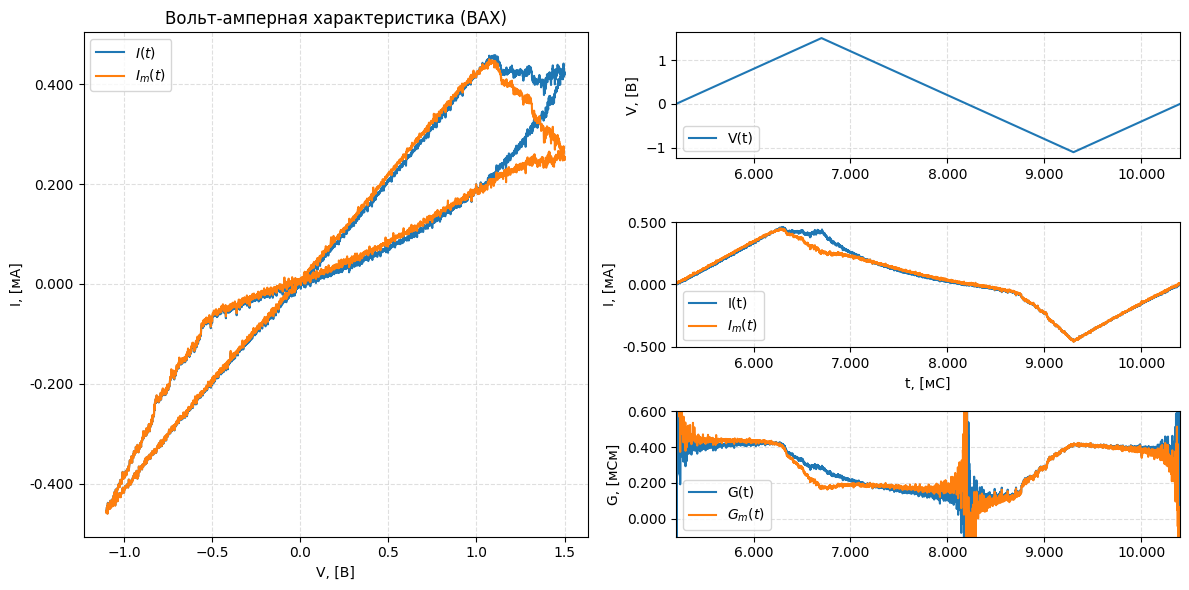

In [ ]:
fig = plt.figure(figsize=(12, 6))
ax_vah = plt.subplot2grid((3, 2), (0, 0), rowspan=3)
ax_v = plt.subplot2grid((3, 2), (0, 1), colspan=1)
ax_i = plt.subplot2grid((3, 2), (1, 1), colspan=1, sharex=ax_v)
ax_g = plt.subplot2grid((3, 2), (2, 1), colspan=1, sharex=ax_v)

# fig.delaxes(ax_vah)

ax_vah.plot(V, I, label='$I(t)$')
ax_vah.plot(V, I_m, label="$I_m(t)$")
ax_v.plot(T, V, label='V(t)')
ax_i.plot(T, I, label='I(t)')
ax_i.plot(T, I_m, label=r'$I_m(t)$')
ax_g.plot(T, G, label='G(t)')
ax_g.plot(T, G_m, label='$G_m(t)$')

ax_vah.set(title="Вольт-амперная характеристика (ВАХ)", xlabel="V, [В]", ylabel="I, [мА]")
ax_i.set(xlabel="t, [мС]", ylabel="I, [мА]")
ax_v.set_ylabel("V, [В]")
ax_g.set_ylabel("G, [мСм]")

ax_g.set_ylim(-0.1e-3, 0.6e-3)

ax_vah.yaxis.set_major_formatter(formatter_to_mA)
ax_i.yaxis.set_major_formatter(formatter_to_mA)
ax_g.yaxis.set_major_formatter(formatter_to_mSm)

for ax in [ax_vah, ax_v, ax_i, ax_g]:
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc="upper left", fontsize="medium")

for ax in [ax_v, ax_i, ax_g]:
    ax.set_xlim(arr_t[start], arr_t[end])
    ax.xaxis.set_major_formatter(formatter_to_mS)
    ax.legend(loc="lower left", fontsize="medium")

plt.tight_layout()
plt.show()

In [ ]:
# Сглаживание мемристивного тока
I_m_smoothed = filter_current(I_m)

# находим обалсти HRS, LRS
source_lrs_end = lrs_end_index
source_hrs_end = hrs_end_index
target_lrs_end = detect_reset_index(I_m_smoothed, peak_index=peak_index)
target_hrs_end = detect_set_index(I_m_smoothed, mid_zero_index=mid_zero_index, valley_index=valley_index)

# области преобработочной фильтрации (HRS + LRS)
source_filter_intervals = [(valley_index, len(V)), (0, source_lrs_end), (peak_index, source_hrs_end)]
target_filter_intervals = [(valley_index, len(V)), (0, target_lrs_end), (peak_index, target_hrs_end)]

# длины окон для сглаживания (для предобработки + устранения разрывов)
filter_window = 51
interpolate_window = int(0.05 * len(V))

G_filtered = G.copy()
for filter_interval in source_filter_intervals:
    f_start, f_end = filter_interval
    G_filtered[f_start : f_end] = savgol_filter(G[f_start : f_end], window_length=filter_window, polyorder=3, mode='mirror')
interpolate_breaks(G_filtered, zero_indices, window_size=interpolate_window)

G_m_filtered = G_m.copy()
for filter_interval in target_filter_intervals:
    f_start, f_end = filter_interval
    G_m_filtered[f_start : f_end] = savgol_filter(G_m[f_start : f_end], window_length=filter_window, polyorder=3, mode='mirror')
interpolate_breaks(G_m_filtered, zero_indices, window_size=interpolate_window)

# Переменная состояния X
G_m_on = np.max(G_m_filtered); G_m_off = np.min(G_m_filtered)
G_m_normalized = (G_m_filtered - G_m_off) / (G_m_on - G_m_off + 1e-12)

# Производная переменной состояния X
G_m_normalized_diff = np.zeros_like(G_m_normalized)
G_m_normalized_diff[:-1] = np.diff(G_m_normalized)

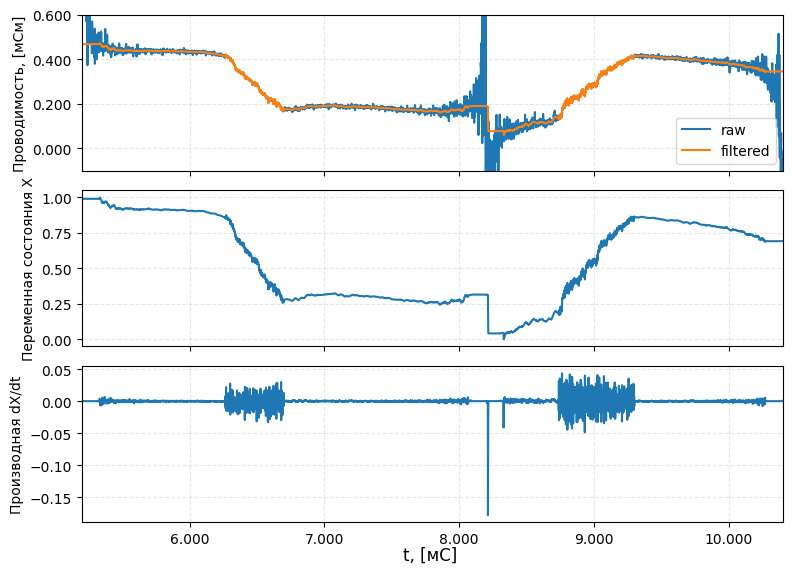

In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8, 6), sharex=True)

ax1.plot(T, G_m, label='raw')
ax1.plot(T, G_m_filtered, label='filtered')
# ax1.plot(T, G_m, alpha=0.4, label='$G_m$')
ax2.plot(T, G_m_normalized)
ax3.plot(T, G_m_normalized_diff)

ax1.legend(loc="lower right", fontsize="medium")

for ax in [ax1, ax2, ax3]:
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.set_xlim(arr_t[start], arr_t[end])

ax1.set_ylim(-0.1e-3, 0.6e-3)
ax1.yaxis.set_major_formatter(formatter_to_mSm)

ax1.set_ylabel("Проводимость, [мСм]")
ax2.set_ylabel("Переменная состояния X")
ax3.set_ylabel("Производная dX/dt")

fig.supxlabel('t, [мС]', x=0.54, y=0.05)
fig.gca().xaxis.set_major_formatter(formatter_to_mS)

plt.tight_layout()
plt.show()

### Оптимизация v.2

__Идея:__

* Задача оптимизации: минимизация кривизны секции LRS, HRS на графике проводимости.
* Условие: максимальное отклонение произвольной точки в секции SET не превышает 1% размахма по току

In [ ]:
def target_function(params, V, I, V_peak_index, V_midzero_index, V_valley_index, set_index, reset_index, tol=1e-3, penalty=1e-4):
    phi, a_f, a_r, b_f, b_r = params
    
    I_s = extract_schottky_current(V, a_f, a_r, b_f, b_r)
    I_m = extract_memristive_current(I, phi, I_s)

    on_index = get_on_index(V_peak_index, V_valley_index, starts_with_hrs=False)
    off_index = get_off_index(V_peak_index, V_valley_index, starts_with_hrs=False)

    # additional step: save 3rd section of smoothed I_m (to pass only smoothed snippet of the I_m (faster that smooth and pass whole I_m)
    I_m_first_section_smoothed = filter_current(I_m[ : V_peak_index + 1])
    I_m_third_section_smoothed = filter_current(I_m[V_midzero_index : V_valley_index + 1])
    mem_set_index = V_midzero_index + detect_set(I_m_third_section_smoothed, V_peak_index=-1, V_midzero_index=0, V_valley_index=(V_valley_index - V_midzero_index), starts_with_hrs=False)
    mem_reset_index = detect_reset(I_m_first_section_smoothed, V_peak_index=V_peak_index, V_midzero_index=-1, V_valley_index=-1, starts_with_hrs=False)

    # get G_m_HRS
    I_m_HRS = I_m[off_index : mem_set_index]; V_m_HRS = V[off_index : mem_set_index]
    G_m_HRS = np.empty_like(I_m_HRS)
    np.divide(I_m_HRS, V_m_HRS, out=G_m_HRS, where=(V_m_HRS != 0))
    G_m_HRS[V_m_HRS == 0] = np.inf
    # remove break
    break_length = int(0.05 * len(V))
    interpolate_break_with_line(G_m_HRS, V_midzero_index - off_index, (break_length + int(break_length % 2 == 0)))

    # get G_m_LRS
    I_m_LRS_1 = I_m[on_index : ]; V_m_LRS_1 = V[on_index : ]
    I_m_LRS_2 = I_m[ : mem_reset_index]; V_m_LRS_2 = V[ : mem_reset_index]

    V_m_LRS = np.concatenate([V_m_LRS_1, V_m_LRS_2], axis=0)
    I_m_LRS = np.concatenate([I_m_LRS_1, I_m_LRS_2], axis=0)

    G_m_LRS = np.empty_like(I_m_LRS)
    np.divide(I_m_LRS, V_m_LRS, out=G_m_LRS, where=(V_m_LRS != 0))
    G_m_LRS[V_m_LRS == 0] = np.inf

    # remove breaks
    break_length = int(0.05 * len(V))
    break_length += int(break_length % 2 == 0)
    interpolate_break_with_line(G_m_LRS, len(V) - on_index, break_length)

    # # get SET + LRS sections with normalized I_m (to avoid small values while calculating violation)
    # I_SET = I[set_index : on_index]
    # I_LRS = np.concatenate([I[on_index : ], I[ : reset_index]], axis=0)
    # I_m_SET = I_m[set_index : on_index]
    # I_m_LRS = np.concatenate([I_m[V_valley_index : ], I_m[ : reset_index]], axis=0)

    # calculate RSS(HRS) — RSS of HRS-curve
    x1 = np.arange(len(G_m_HRS))
    m1, c1 = np.polyfit(x1, G_m_HRS, 1)
    rss_hrs = np.sum((G_m_HRS - (m1*x1 + c1))**2)

    # calculate RSS(LRS) — RSS of LRS-curve
    x2 = np.arange(len(G_m_LRS))
    m2, c2 = np.polyfit(x2, G_m_LRS, 1)
    rss_lrs = np.sum((G_m_LRS - (m2*x2 + c2))**2)

    # # calculate dev_max(SET + LRS) — maximum deviation of intervals SET + LRS
    # dev_set = np.abs(I_m_SET - I_SET)
    # dev_lrs = np.abs(I_m_LRS - I_LRS)
    # max_dev = max(np.max(dev_set), np.max(dev_lrs))
    # violation = np.maximum(0, max_dev - tol)

    return rss_hrs + rss_lrs + penalty * m1**2 + penalty * m2**2 \
        + 10e9 * int((I_m[off_index] - I_m[set_indexa]) < 0.1) \
        + 10e9 * int(I_m[off_index] < 0.1)

In [75]:
# Подготовка данных

# Считываем 2-й цикл ВАХ-ки
start, end = get_period_indices(arr_v, 1, segments_per_period=2, period_start_segment_idx=0)
I = arr_i[start : end]; V = arr_v[start : end]; I_smoothed = filter_current(I, high_smooth=True)
T = arr_t[start : end]

# Находим нули и экстремумы
zero_indices, peak_indices, valley_indices = find_extrema_and_zeros(V[1:-1])
zero_indices = np.concatenate([[0], zero_indices, [len(V) - 1]], axis=0)

peak_index = peak_indices[0]
valley_index = valley_indices[0]
mid_zero_index = zero_indices[1]

# Нормализация
I_max = np.max(np.abs(I))
I_normalized = I / I_max
V_max = np.max(np.abs(V))
V_normalized = V / V_max

# Проводиомсть
G = np.empty_like(V)
np.divide(I, V, out=G, where=(V != 0))
G[V == 0] = np.inf

# Находим обалсти SET, RESET
reset_index = detect_reset(I_smoothed, peak_index, mid_zero_index, valley_index, starts_with_hrs=False)
set_index = detect_set(I_smoothed, peak_index, mid_zero_index, valley_index, starts_with_hrs=False)

In [76]:
# Запуск оптимизации

target_simplified = lambda phi, a_f, a_r, b_f, b_r : target_function(
    V_normalized, I_normalized, 
    phi, a_f, a_r, b_f, b_r, peak_index, mid_zero_index, valley_index, set_index, reset_index, 
    tol=0.01, penalty=1e3)

# ==============================================================================

param_bounds = [
    (0.9, 1.0),
    (1e-3, 1e1),
    (1e-3, 1e1),
    (0, 10),
    (-10, 0),
]

history = []

def history_callback(intermediate_result):
    history.append(intermediate_result.x)

result = differential_evolution(
    func=lambda p: target_simplified(p[0], p[1], p[2], p[3], p[4]),
    bounds=param_bounds,
    seed=42,
    maxiter=500,
    callback=history_callback
)

phi, a_f, a_r, b_f, b_r = result.x

print(f"Success = {result.success}")
print(f"phi = {phi}")
print(f"a_f = {a_f}")
print(f"a_r = {a_r}")
print(f"b_f = {b_f}")
print(f"b_r = {b_r}")

Success = True
phi = 0.9828867556689226
a_f = 2.2003690658644643
a_r = 2.299822886055827
b_f = 5.298842152467568
b_r = -5.215554699058341


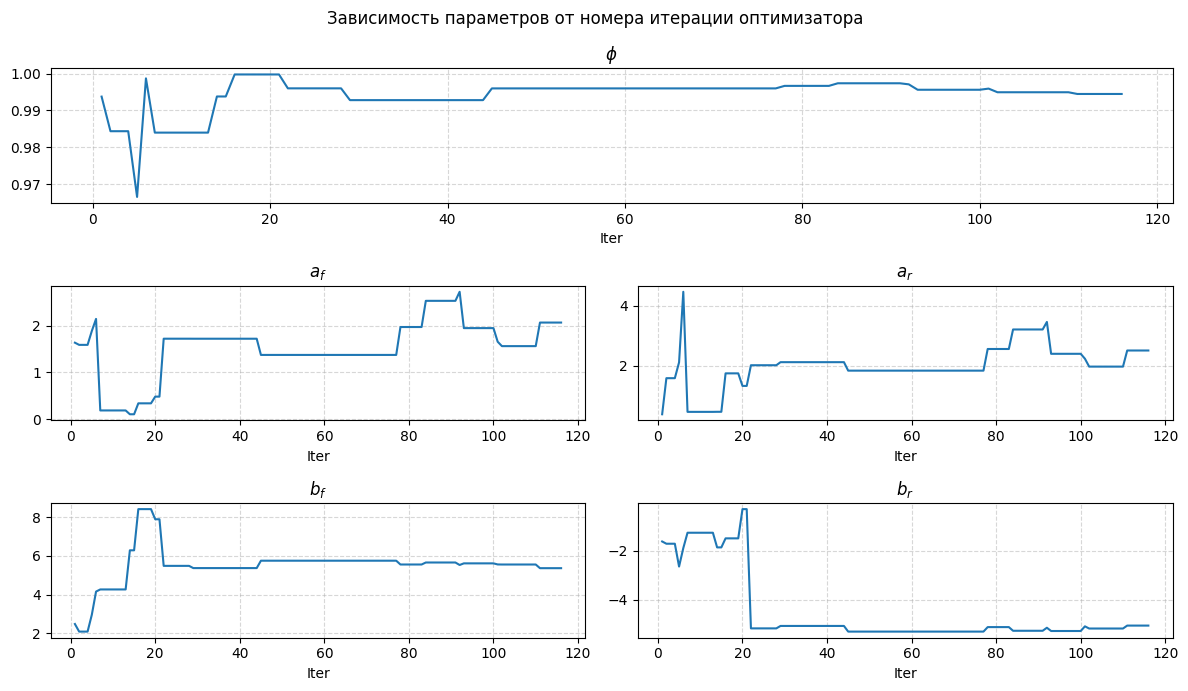

In [77]:
set_inline_backend()

history = np.array(history)

fig = plt.figure(figsize=(12, 7))
ax_phi = plt.subplot2grid((3, 2), (0, 0), colspan=2)
ax_a_f = plt.subplot2grid((3, 2), (1, 0))
ax_a_r = plt.subplot2grid((3, 2), (1, 1))
ax_b_f = plt.subplot2grid((3, 2), (2, 0))
ax_b_r = plt.subplot2grid((3, 2), (2, 1))
axes = [ax_phi, ax_a_f, ax_a_r, ax_b_f, ax_b_r]

n_iters = history.shape[0]
iters = np.linspace(1, n_iters, n_iters).astype(int)

ax_phi.plot(iters, history[:, 0])
ax_phi.set_title(r'$\phi$')

ax_a_f.plot(iters,  history[:, 1])
ax_a_f.set_title(r'$a_f$')

ax_a_r.plot(iters,  history[:, 2])
ax_a_r.set_title(r'$a_r$')

ax_b_f.plot(iters,  history[:, 3])
ax_b_f.set_title(r'$b_f$')

ax_b_r.plot(iters,  history[:, 4])
ax_b_r.set_title(r'$b_r$')

for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_xlabel("Iter")
    # ax.set_yscale('symlog')

fig.suptitle("Зависимость параметров от номера итерации оптимизатора")
plt.tight_layout()
plt.show()

In [78]:
phi, a_f, a_r, b_f, b_r = result.x

I_s_normalized = extract_schottky_current(V_normalized, a_f, a_r, b_f, b_r)
I_m_normalized = extract_memristive_current(I_normalized, phi, I_s_normalized)

I_m = I_m_normalized * I_max

G_m = np.empty_like(I_m)
np.divide(I_m, V, out=G_m, where=(V != 0))
G_m[V == 0] = np.inf

In [ ]:
# I_m_HRS = I_m[peak_index : target_hrs_end]
# V_m_HRS = V[peak_index : target_hrs_end]
# G_m_HRS = np.empty_like(I_m_HRS)
# np.divide(I_m_HRS, V_m_HRS, out=G_m_HRS, where=(V_m_HRS != 0))
# G_m_HRS[V_m_HRS == 0] = np.inf

# break_length = int(0.05 * len(V))
# interpolate_break_with_line(G_m_HRS, mid_zero_index - peak_index, (break_length + int(break_length % 2 == 0)))

# x = np.arange(len(G_m_HRS))
# m, c = np.polyfit(x, G_m_HRS, 1)
# rss = np.sum((G_m_HRS - (m*x + c))**2)

# target = target_simplified(phi, a_f, a_r, b_f, b_r)

# print(f"rss = {rss}")
# print(f"target = {target}")

# print(f"max_dev = {np.sqrt((target - rss) / 1e2)}")

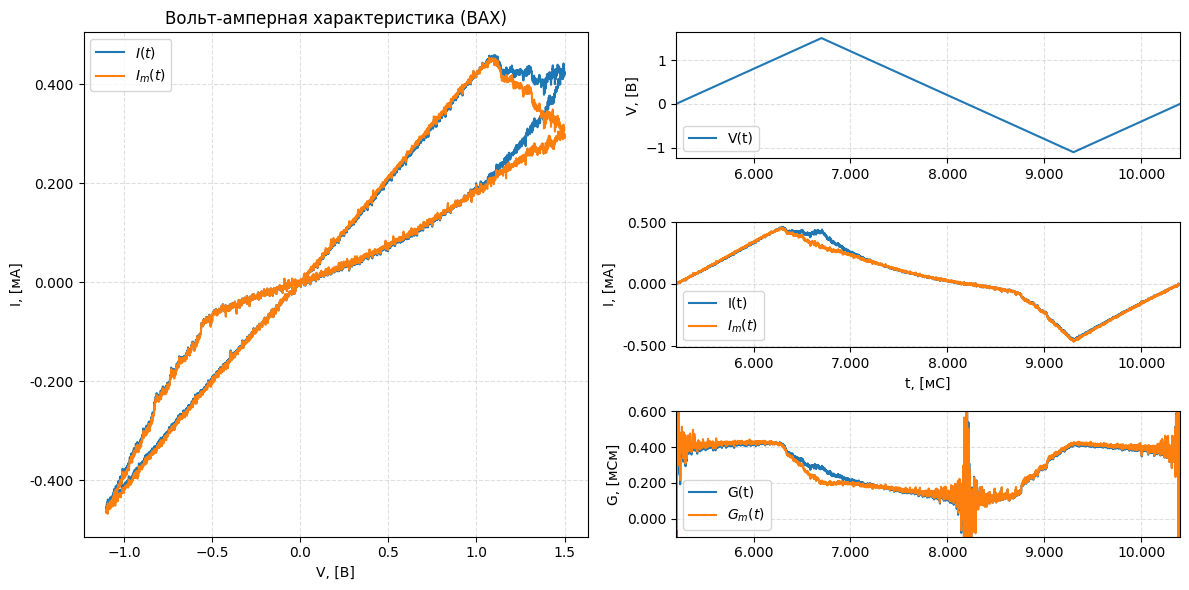

In [80]:
fig = plt.figure(figsize=(12, 6))
ax_vah = plt.subplot2grid((3, 2), (0, 0), rowspan=3)
ax_v = plt.subplot2grid((3, 2), (0, 1), colspan=1)
ax_i = plt.subplot2grid((3, 2), (1, 1), colspan=1, sharex=ax_v)
ax_g = plt.subplot2grid((3, 2), (2, 1), colspan=1, sharex=ax_v)

# fig.delaxes(ax_vah)

ax_vah.plot(V, I, label='$I(t)$')
ax_vah.plot(V, I_m, label="$I_m(t)$")
ax_v.plot(T, V, label='V(t)')
ax_i.plot(T, I, label='I(t)')
ax_i.plot(T, I_m, label=r'$I_m(t)$')
ax_g.plot(T, G, label='G(t)')
ax_g.plot(T, G_m, label='$G_m(t)$')

ax_vah.set(title="Вольт-амперная характеристика (ВАХ)", xlabel="V, [В]", ylabel="I, [мА]")
ax_i.set(xlabel="t, [мС]", ylabel="I, [мА]")
ax_v.set_ylabel("V, [В]")
ax_g.set_ylabel("G, [мСм]")

ax_g.set_ylim(-0.1e-3, 0.6e-3)

ax_vah.yaxis.set_major_formatter(formatter_to_mA)
ax_i.yaxis.set_major_formatter(formatter_to_mA)
ax_g.yaxis.set_major_formatter(formatter_to_mSm)

for ax in [ax_vah, ax_v, ax_i, ax_g]:
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc="upper left", fontsize="medium")

for ax in [ax_v, ax_i, ax_g]:
    ax.set_xlim(arr_t[start], arr_t[end])
    ax.xaxis.set_major_formatter(formatter_to_mS)
    ax.legend(loc="lower left", fontsize="medium")

plt.tight_layout()
plt.show()

In [82]:
# Сглаживание мемристивного тока
I_m_smoothed = filter_current(I_m)

# находим обалсти HRS, LRS
source_reset = detect_reset(I_smoothed, peak_index, mid_zero_index, valley_index, starts_with_hrs=False)
source_set = detect_set(I_smoothed, peak_index, mid_zero_index, valley_index, starts_with_hrs=False)
target_reset = detect_reset(I_m_smoothed, peak_index, mid_zero_index, valley_index, starts_with_hrs=False)
target_set = detect_set(I_m_smoothed, peak_index, mid_zero_index, valley_index, starts_with_hrs=False)

# области преобработочной фильтрации (HRS + LRS)
source_filter_intervals = [(valley_index, len(V)), (0, source_reset), (peak_index, source_set)]
target_filter_intervals = [(valley_index, len(V)), (0, target_reset), (peak_index, target_set)]

# длины окон для сглаживания (для предобработки + устранения разрывов)
filter_window = 51
interpolate_window = int(0.05 * len(V))

G_filtered = G.copy()
for filter_interval in source_filter_intervals:
    f_start, f_end = filter_interval
    G_filtered[f_start : f_end] = savgol_filter(G[f_start : f_end], window_length=filter_window, polyorder=3, mode='mirror')
for zero_index in zero_indices:
    interpolate_break_median(G_filtered, zero_index, window_size=interpolate_window)

G_m_filtered = G_m.copy()
for filter_interval in target_filter_intervals:
    f_start, f_end = filter_interval
    G_m_filtered[f_start : f_end] = savgol_filter(G_m[f_start : f_end], window_length=filter_window, polyorder=3, mode='mirror')
for zero_index in zero_indices:
    interpolate_break_median(G_m_filtered, zero_index, window_size=interpolate_window)

# Переменная состояния X
G_m_on = np.max(G_m_filtered); G_m_off = np.min(G_m_filtered)
G_m_normalized = (G_m_filtered - G_m_off) / (G_m_on - G_m_off + 1e-12)

# Производная переменной состояния X
G_m_normalized_diff = np.zeros_like(G_m_normalized)
G_m_normalized_diff[:-1] = np.diff(G_m_normalized)

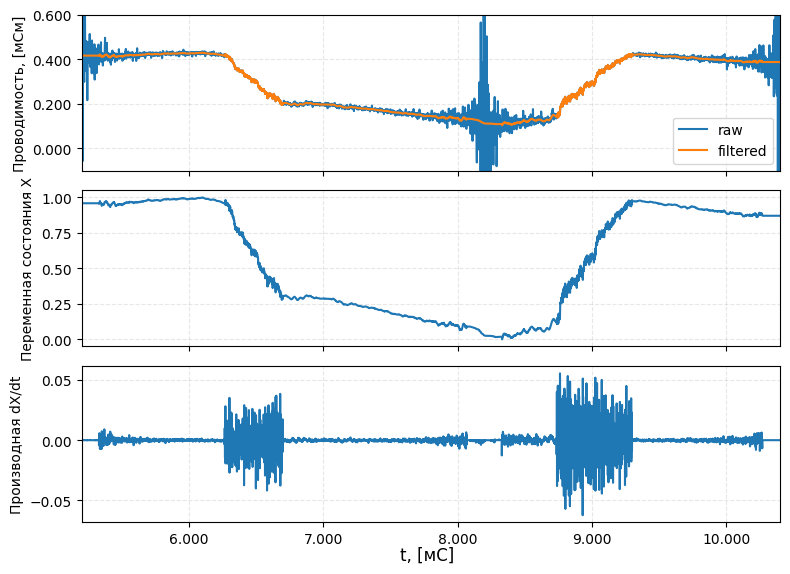

In [83]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8, 6), sharex=True)

ax1.plot(T, G_m, label='raw')
ax1.plot(T, G_m_filtered, label='filtered')
# ax1.plot(T, G_m, alpha=0.4, label='$G_m$')
ax2.plot(T, G_m_normalized)
ax3.plot(T, G_m_normalized_diff)

ax1.legend(loc="lower right", fontsize="medium")

for ax in [ax1, ax2, ax3]:
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.set_xlim(arr_t[start], arr_t[end])

ax1.set_ylim(-0.1e-3, 0.6e-3)
# ax2.set_ylim(-0.1e-3, 0.6e-3)
ax1.yaxis.set_major_formatter(formatter_to_mSm)
# ax2.yaxis.set_major_formatter(formatter_to_mA)

ax1.set_ylabel("Проводимость, [мСм]")
ax2.set_ylabel("Переменная состояния X")
ax3.set_ylabel("Производная dX/dt")

# fig.suptitle('raw VS filtered', x=0.54, y=0.97)
fig.supxlabel('t, [мС]', x=0.54, y=0.05)
fig.gca().xaxis.set_major_formatter(formatter_to_mS)

plt.tight_layout()
plt.show()

### Оптимизация v.3

__Идея:__

* Обработка второй версии с исключением поиска SET / RESET. Будем искать HRS, LRS по заведомо минимально возоможным точкам SET, RESET.
* Таким образом предполагается, что оптимизатор максимально сможет выпрямить будущие области SET / RESET.

In [ ]:
def target_function(params, V, I, V_max_idx, V0_idx, V_min_idx, min_set_index, min_reset_index, tol=1e-3, penalty=1e-4):
    phi, a_f, a_r, b_f, b_r = params
    
    I_s = extract_schottky_current(V, a_f, a_r, b_f, b_r)
    I_m = extract_memristive_current(I, phi, I_s)

    on_index = get_on_index(V_max_idx, V_min_idx, starts_with_hrs=False)
    off_index = get_off_index(V_max_idx, V_min_idx, starts_with_hrs=False)

    break_length = int(0.05 * len(V))
    break_length += int(break_length % 2 == 0)

    # get G_m_HRS
    I_m_HRS = I_m[off_index : min_set_index]; V_m_HRS = V[off_index : min_set_index]
    G_m_HRS = calculate_G(V_m_HRS, I_m_HRS)

    # get G_m_LRS
    I_m_LRS_1 = I_m[on_index : ]; V_m_LRS_1 = V[on_index : ]
    I_m_LRS_2 = I_m[ : min_reset_index]; V_m_LRS_2 = V[ : min_reset_index]

    V_m_LRS = np.concatenate([V_m_LRS_1, V_m_LRS_2], axis=0)
    I_m_LRS = np.concatenate([I_m_LRS_1, I_m_LRS_2], axis=0)

    G_m_LRS = calculate_G(V_m_LRS, I_m_LRS)

    # interpolate breaks
    interpolate_break_with_line(G_m_HRS, V0_idx - off_index, break_length)
    interpolate_break_with_line(G_m_LRS, len(V) - on_index, break_length)

    # calculate RSS(HRS) — RSS of HRS-curve
    x1 = np.arange(len(G_m_HRS))
    m1, c1 = np.polyfit(x1, G_m_HRS, 1)
    rss_hrs = np.sum((G_m_HRS - (m1*x1 + c1))**2)

    # calculate RSS(LRS) — RSS of LRS-curve
    x2 = np.arange(len(G_m_LRS))
    m2, c2 = np.polyfit(x2, G_m_LRS, 1)
    rss_lrs = np.sum((G_m_LRS - (m2*x2 + c2))**2)

    # calculate slope of HRS and LRS
    hrs_slope = (I_m_HRS[-1] - I_m_HRS[0]) / np.abs(V_m_HRS[-1] - V_m_HRS[0])
    lrs_slope = (I_m_LRS[-1] - I_m_LRS[0]) / np.abs(V_m_LRS[-1] - V_m_LRS[0])

    return rss_hrs + rss_lrs \
        + penalty * m1**2 + penalty * m2**2 \
        + 10e9 * (hrs_slope > 0) \
        + 10e9 * (lrs_slope < 0)

In [ ]:
# Подготовка данных

# Считываем 2-й цикл ВАХ-ки
start, end = get_period_indices(arr_v, 1, segments_per_period=2, period_start_segment_idx=0)
I = arr_i[start : end]; V = arr_v[start : end]; I_smoothed = filter_current(I, high_smooth=True)
T = arr_t[start : end]

# Находим нули и экстремумы
mid_zero_index = get_zero_indices(V[1 : -1])[0]
zero_indices = np.concatenate([[0], [mid_zero_index], [len(V) - 1]], axis=0)
peak_indices, _ = find_peaks(V);        peak_index = peak_indices[0]
valley_indices, _ = find_peaks(-V);     valley_index = valley_indices[0]

# Нормализация
I_max = np.max(np.abs(I))
I_normalized = I / I_max
V_max = np.max(np.abs(V))
V_normalized = V / V_max

# Проводиомсть
G = np.empty_like(V)
np.divide(I, V, out=G, where=(V != 0))
G[V == 0] = np.inf

# Находим обалсти LRS, HRS
lrs_end_index = detect_reset_index(I_smoothed, peak_index=peak_index)
hrs_end_index = detect_set_index(I_smoothed, valley_index=valley_index, mid_zero_index=mid_zero_index)

In [ ]:
# Запуск оптимизации

target_simplified = lambda phi, a_f, a_r, b_f, b_r : target_function(
    V_normalized, I_normalized, 
    phi, a_f, a_r, b_f, b_r, peak_index, mid_zero_index, valley_index, hrs_end_index=hrs_end_index, lrs_end_index=lrs_end_index, 
    tol=0.01, penalty_s=1e1, penalty_v=1e3)

# ==============================================================================

param_bounds = [
    (0.9, 1.0),
    (1e-3, 1e1),
    (1e-3, 1e1),
    (0, 10),
    (-10, 0),
]

history = []

def history_callback(intermediate_result):
    history.append(intermediate_result.x)

result = differential_evolution(
    func=lambda p: target_simplified(p[0], p[1], p[2], p[3], p[4]),
    bounds=param_bounds,
    seed=42,
    maxiter=500,
    callback=history_callback
)

phi, a_f, a_r, b_f, b_r = result.x

print(f"Success = {result.success}")
print(f"phi = {phi}")
print(f"a_f = {a_f}")
print(f"a_r = {a_r}")
print(f"b_f = {b_f}")
print(f"b_r = {b_r}")

Success = True
phi = 0.9994380586699031
a_f = 2.230473155518384
a_r = 6.467653167333646
b_f = 6.521068824322909
b_r = -4.883422615519369


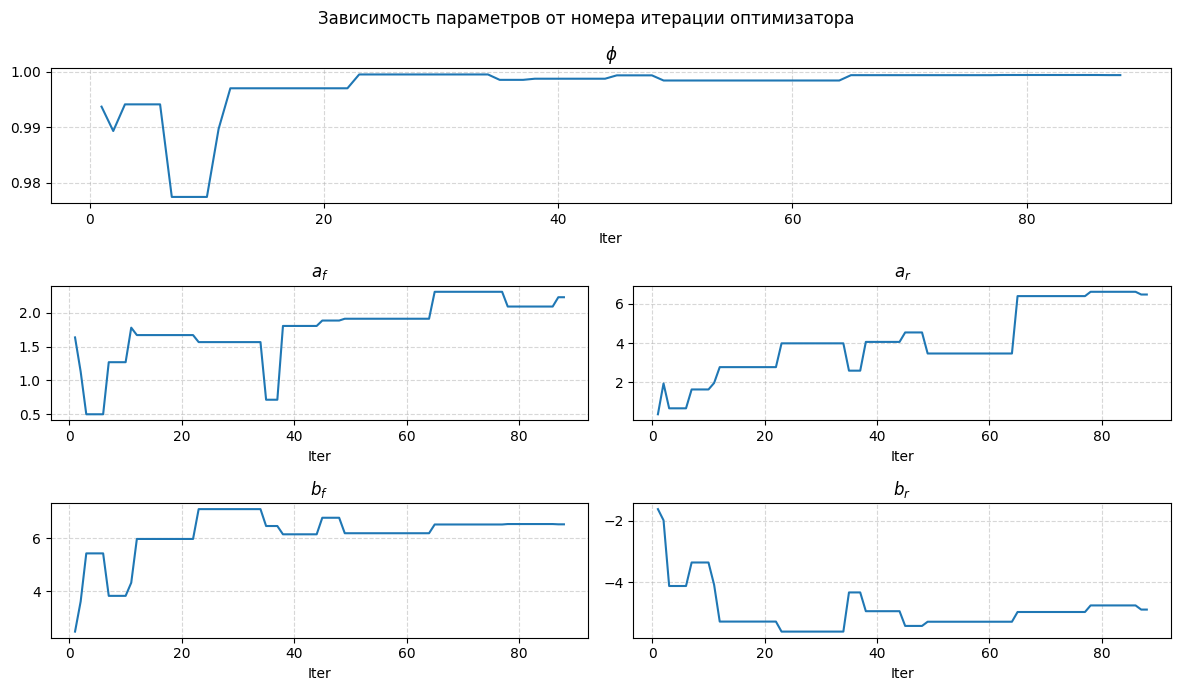

In [ ]:
history = np.array(history)

fig = plt.figure(figsize=(12, 7))
ax_phi = plt.subplot2grid((3, 2), (0, 0), colspan=2)
ax_a_f = plt.subplot2grid((3, 2), (1, 0))
ax_a_r = plt.subplot2grid((3, 2), (1, 1))
ax_b_f = plt.subplot2grid((3, 2), (2, 0))
ax_b_r = plt.subplot2grid((3, 2), (2, 1))
axes = [ax_phi, ax_a_f, ax_a_r, ax_b_f, ax_b_r]

n_iters = history.shape[0]
iters = np.linspace(1, n_iters, n_iters).astype(int)

ax_phi.plot(iters, history[:, 0])
ax_phi.set_title(r'$\phi$')

ax_a_f.plot(iters,  history[:, 1])
ax_a_f.set_title(r'$a_f$')

ax_a_r.plot(iters,  history[:, 2])
ax_a_r.set_title(r'$a_r$')

ax_b_f.plot(iters,  history[:, 3])
ax_b_f.set_title(r'$b_f$')

ax_b_r.plot(iters,  history[:, 4])
ax_b_r.set_title(r'$b_r$')

for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_xlabel("Iter")
    # ax.set_yscale('symlog')

fig.suptitle("Зависимость параметров от номера итерации оптимизатора")
plt.tight_layout()
plt.show()

In [ ]:
phi, a_f, a_r, b_f, b_r = result.x

I_s_normalized = extract_schottky_current(V_normalized, a_f, a_r, b_f, b_r)
I_m_normalized = extract_memristive_current(I_normalized, phi, I_s_normalized)

I_m = I_m_normalized * I_max

G_m = np.empty_like(I_m)
np.divide(I_m, V, out=G_m, where=(V != 0))
G_m[V == 0] = np.inf

In [ ]:
I_m_HRS = I_m[peak_index : target_hrs_end]
V_m_HRS = V[peak_index : target_hrs_end]
G_m_HRS = np.empty_like(I_m_HRS)
np.divide(I_m_HRS, V_m_HRS, out=G_m_HRS, where=(V_m_HRS != 0))
G_m_HRS[V_m_HRS == 0] = np.inf

break_length = int(0.05 * len(V))
interpolate_break_with_line(G_m_HRS, mid_zero_index - peak_index, (break_length + int(break_length % 2 == 0)))

slope = np.abs(G_m_HRS[0] - G_m_HRS[-1])

target = target_simplified(phi, a_f, a_r, b_f, b_r)

print(f"slope = {slope}")
print(f"target = {target}")
print(f"max_dev = {np.sqrt((target - rss) / 1e2)}")

slope = 2.7540128975024126e-05
target = 5.604955773436181
max_dev = 0.23668807982167095


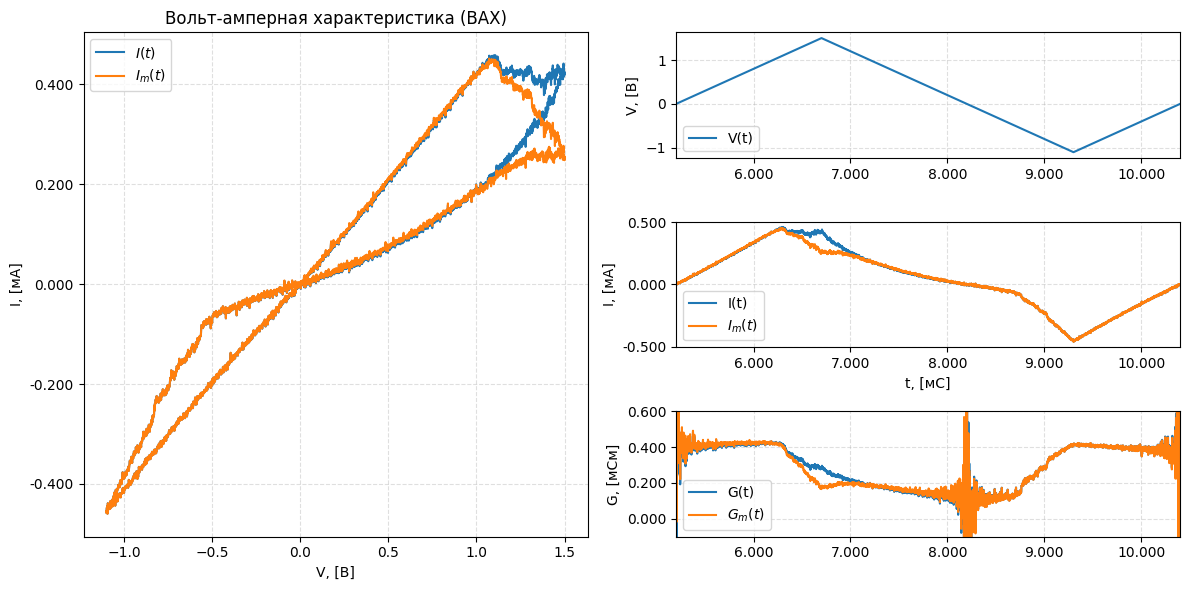

In [ ]:
fig = plt.figure(figsize=(12, 6))
ax_vah = plt.subplot2grid((3, 2), (0, 0), rowspan=3)
ax_v = plt.subplot2grid((3, 2), (0, 1), colspan=1)
ax_i = plt.subplot2grid((3, 2), (1, 1), colspan=1, sharex=ax_v)
ax_g = plt.subplot2grid((3, 2), (2, 1), colspan=1, sharex=ax_v)

# fig.delaxes(ax_vah)

ax_vah.plot(V, I, label='$I(t)$')
ax_vah.plot(V, I_m, label="$I_m(t)$")
ax_v.plot(T, V, label='V(t)')
ax_i.plot(T, I, label='I(t)')
ax_i.plot(T, I_m, label=r'$I_m(t)$')
ax_g.plot(T, G, label='G(t)')
ax_g.plot(T, G_m, label='$G_m(t)$')

ax_vah.set(title="Вольт-амперная характеристика (ВАХ)", xlabel="V, [В]", ylabel="I, [мА]")
ax_i.set(xlabel="t, [мС]", ylabel="I, [мА]")
ax_v.set_ylabel("V, [В]")
ax_g.set_ylabel("G, [мСм]")

ax_g.set_ylim(-0.1e-3, 0.6e-3)

ax_vah.yaxis.set_major_formatter(formatter_to_mA)
ax_i.yaxis.set_major_formatter(formatter_to_mA)
ax_g.yaxis.set_major_formatter(formatter_to_mSm)

for ax in [ax_vah, ax_v, ax_i, ax_g]:
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc="upper left", fontsize="medium")

for ax in [ax_v, ax_i, ax_g]:
    ax.set_xlim(arr_t[start], arr_t[end])
    ax.xaxis.set_major_formatter(formatter_to_mS)
    ax.legend(loc="lower left", fontsize="medium")

plt.tight_layout()
plt.show()

In [ ]:
# Сглаживание мемристивного тока
I_m_smoothed = filter_current(I_m)

# находим обалсти HRS, LRS
source_lrs_end = detect_reset_index(I_smoothed, peak_index=peak_index)
source_hrs_end = detect_set_index(I_smoothed, mid_zero_index=mid_zero_index, valley_index=valley_index)
target_lrs_end = detect_reset_index(I_m_smoothed, peak_index=peak_index)
target_hrs_end = detect_set_index(I_m_smoothed, mid_zero_index=mid_zero_index, valley_index=valley_index)

# области преобработочной фильтрации (HRS + LRS)
source_filter_intervals = [(valley_index, len(V)), (0, source_lrs_end), (peak_index, source_hrs_end)]
target_filter_intervals = [(valley_index, len(V)), (0, target_lrs_end), (peak_index, target_hrs_end)]

# длины окон для сглаживания (для предобработки + устранения разрывов)
filter_window = 51
interpolate_window = int(0.05 * len(V))

G_filtered = G.copy()
for filter_interval in source_filter_intervals:
    f_start, f_end = filter_interval
    G_filtered[f_start : f_end] = savgol_filter(G[f_start : f_end], window_length=filter_window, polyorder=3, mode='mirror')
interpolate_breaks(G_filtered, zero_indices, window_size=interpolate_window)

G_m_filtered = G_m.copy()
for filter_interval in target_filter_intervals:
    f_start, f_end = filter_interval
    G_m_filtered[f_start : f_end] = savgol_filter(G_m[f_start : f_end], window_length=filter_window, polyorder=3, mode='mirror')
interpolate_breaks(G_m_filtered, zero_indices, window_size=interpolate_window)

# Переменная состояния X
G_m_on = np.max(G_m_filtered); G_m_off = np.min(G_m_filtered)
G_m_normalized = (G_m_filtered - G_m_off) / (G_m_on - G_m_off + 1e-12)

# Производная переменной состояния X
G_m_normalized_diff = np.zeros_like(G_m_normalized)
G_m_normalized_diff[:-1] = np.diff(G_m_normalized)

In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8, 6), sharex=True)

ax1.plot(T, G_m, label='raw')
ax1.plot(T, G_m_filtered, label='filtered')
# ax1.plot(T, G_m, alpha=0.4, label='$G_m$')
ax2.plot(T, G_m_normalized)
ax3.plot(T, G_m_normalized_diff)

ax1.legend(loc="lower right", fontsize="medium")

for ax in [ax1, ax2, ax3]:
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.set_xlim(arr_t[start], arr_t[end])

ax1.set_ylim(-0.1e-3, 0.6e-3)
# ax2.set_ylim(-0.1e-3, 0.6e-3)
ax1.yaxis.set_major_formatter(formatter_to_mSm)
# ax2.yaxis.set_major_formatter(formatter_to_mA)

ax1.set_ylabel("Проводимость, [мСм]")
ax2.set_ylabel("Переменная состояния X")
ax3.set_ylabel("Производная dX/dt")

# fig.suptitle('raw VS filtered', x=0.54, y=0.97)
fig.supxlabel('t, [мС]', x=0.54, y=0.05)
fig.gca().xaxis.set_major_formatter(formatter_to_mS)

plt.tight_layout()
plt.show()

### Финальная версия

(версия №2)

In [26]:
def fit_by_center_window(V_part, I_part, center_idx, frac=0.2):
    n = len(V_part)
    half_window = max(2, int(frac * n / 2))

    left = max(0, center_idx - half_window)
    right = min(n, center_idx + half_window + 1)

    if right - left < 2:
        return np.polyfit(V_part, I_part, 1)

    return np.polyfit(V_part[left:right], I_part[left:right], 1)

In [46]:
# 

def target_function(params, V, I, V_max_idx, V0_idx, V_min_idx, set_index, reset_index, k_set=1.0, k_reset=1.0, starts_with_hrs=False, penalty=1e-4):
    phi, a_f, a_r, b_f, b_r = params
    
    I_s = extract_schottky_current(V, a_f, a_r, b_f, b_r)
    I_m = extract_memristive_current(I, phi, I_s)

    on_index = get_on_index(V_max_idx, V_min_idx, starts_with_hrs=starts_with_hrs)
    off_index = get_off_index(V_max_idx, V_min_idx, starts_with_hrs=starts_with_hrs)

    # mem_set_index = detect_set(V, I_m, on_index, V0_idx, k=k_set, starts_with_hrs=starts_with_hrs) 
    # mem_reset_index = detect_reset(V, I_m, off_index, V0_idx, k=k_reset, starts_with_hrs=starts_with_hrs) 

    # get HRS area
    if starts_with_hrs:
        I_m_HRS = np.concatenate([I_m[off_index : ], I_m[ : set_index]], axis=0)
        I_HRS = np.concatenate([I[off_index : ], I[ : set_index]], axis=0)
        V_HRS = np.concatenate([V[off_index : ], V[ : set_index]], axis=0)
    else:
        I_m_HRS = I_m[off_index : set_index]
        I_HRS = I[off_index : set_index]
        V_HRS = V[off_index : set_index]
    
    # get LRS area
    if starts_with_hrs:
        I_m_LRS = I_m[on_index : reset_index]
        I_LRS = I[on_index : reset_index]
        V_LRS = V[on_index : reset_index]
    else:
        I_m_LRS = np.concatenate([I_m[on_index : ], I_m[ : reset_index]], axis=0)
        I_LRS = np.concatenate([I[on_index : ], I[ : reset_index]], axis=0)
        V_LRS = np.concatenate([V[on_index : ], V[ : reset_index]], axis=0)

    # настройка для более сильного контроля за краями LRS / HRS
    lrs_center = (V0_idx - reset_index) if (starts_with_hrs) else (len(V) - on_index)
    hrs_center = (len(V) - off_index) if (starts_with_hrs) else (V0_idx - off_index)
    hrs_center = max(1, hrs_center)
    lrs_center = max(1, lrs_center)

    # Во сколько раз штраф на краях больше, чем в центре (в `edge_multiplier + 1` раз)
    hrs_edge_multiplier = 1.0
    lrs_edge_multiplier = 4.0
    # exponent = 2.0         # Форма кривой: 2 = парабола (плавно), 4 = остро (резко)

    # calculate RSS(HRS) — RSS of HRS-curve
    x1 = V_HRS
    idxs1 = np.arange(len(V_HRS))
    dist_from_center = np.abs(idxs1 - hrs_center) / hrs_center
    weights_hrs = -1.0 + hrs_edge_multiplier * np.exp(dist_from_center)
    # m1, c1 = np.polyfit(x1, I_m_HRS, 1, w=np.sqrt(weights_hrs))
    m1, c1 = fit_by_center_window(V_HRS, I_HRS, hrs_center, frac=0.1)
    rss_hrs = np.sum(weights_hrs * (I_m_HRS - (m1*x1 + c1))**2) / np.sum(weights_hrs)

    # calculate RSS(LRS) — RSS of LRS-curve
    x2 = V_LRS
    idxs2 = np.arange(len(V_LRS))
    dist_from_center = np.abs(idxs2 - lrs_center) / lrs_center
    weights_lrs = -1.0 + lrs_edge_multiplier * np.exp(dist_from_center)
    # m2, c2 = np.polyfit(x2, I_m_LRS, 1, w=np.sqrt(weights_lrs))
    m2, c2 = fit_by_center_window(V_LRS, I_m_LRS, lrs_center, frac=0.3)
    rss_lrs = np.sum(weights_lrs * (I_m_LRS - (m2*x2 + c2))**2) / np.sum(weights_lrs)

    # calculate slope of HRS and LRS
    # hrs_slope = (I_m_HRS[-1] - I_m_HRS[0]) / np.abs(V_m_HRS[-1] - V_m_HRS[0])
    # lrs_slope = (I_m_LRS[-1] - I_m_LRS[0]) / np.abs(V_m_LRS[-1] - V_m_LRS[0])

    sign_violation = (
        np.sum(np.maximum(0, -I_m[V > 0])**2) +
        np.sum(np.maximum(0,  I_m[V < 0])**2)
    )

    hrs_sign_violation = (
        np.sum(np.maximum(0, -I_m_HRS[V_HRS > 0])**2) +
        np.sum(np.maximum(0,  I_m_HRS[V_HRS < 0])**2)
    )

    intercept_violation = c1**2 + c2**2
    zero_violation = I_m[V0_idx] ** 2

    hrs_weight = 1.0
    lrs_weight = 1.0

    return (
        hrs_weight * rss_hrs
        + 1e1 * intercept_violation
        # + 1e3 * sign_violation \
        # + 1e4 * hrs_sign_violation \
        # + 1e4 * zero_violation
    )

In [47]:
# param_bounds = [
#     (0.9, 1.0),
#     (1e-3, 1e1),
#     (1e-3, 1e1),
#     (0, 10),
#     (-10, 0),
# ]

param_bounds = [
    (0.0, 0.99),
    (1e-3, 1e2),
    (1e-3, 1e2),
    (0, 30),
    (0, 30),
]

def find_best_schottky_params(V, I, V_max_idx, V0_idx, V_min_idx, set_index, reset_index, k_set=1.0, k_reset=1.0, starts_with_hrs=False, maxiter=500, init_population=None, seed=42):
    if init_population is not None:
        result = differential_evolution(
            func=target_function,
            bounds=param_bounds,
            args=(V, I, V_max_idx, V0_idx, V_min_idx, set_index, reset_index, k_set, k_reset, starts_with_hrs),
            seed=seed,
            maxiter=maxiter,
            init=init_population
            )
    else:
        result = differential_evolution(
            func=target_function,
            bounds=param_bounds,
            args=(V, I, V_max_idx, V0_idx, V_min_idx, set_index, reset_index, k_set, k_reset, starts_with_hrs),
            seed=seed,
            maxiter=maxiter
            )
    
    return result.x, result.population

In [ ]:
def target_function_global(params, V, I, V_zeros):
    n_cycles = get_num_periods(V_zeros, segments_per_period=2)

    result_total = 0
    for j in range(n_cycles):
        start, end = get_period_indices(V, j, V_zeros, segments_per_period=2, period_start_segment_idx=0)

        v = V[start : end]; i = I[start : end]
        i_smoothed = filter_current(i)
        V0_idx = V_zeros[1]; V_max_idx = np.argmax(V); V_min_idx = np.argmin(V)
        
        set_weights = (5, 0.5)
        reset_weights = (1, 0.5)

        reset_index, _ = detect_breakpoint_fastest(i_smoothed[: V_max_idx], weights=reset_weights, x=v[: V_max_idx])
        set_index, _ =   detect_breakpoint_fastest(i_smoothed[V0_idx : V_min_idx], weights=set_weights, x=v[V0_idx : V_min_idx])
        set_index += V0_idx
        
        result = target_function(params, v, i, V_max_idx, V0_idx, V_min_idx, set_index, reset_index)
        result_total += result
    
    result_total /= n_cycles
    return result_total

In [ ]:
def find_best_schottky_params_global(V, I, V_zeros, maxiter=500, init_population=None, seed=42):
    if init_population is not None:
        result = differential_evolution(
            func=target_function_global,
            bounds=param_bounds,
            args=(V, I, V_zeros),
            seed=seed,
            maxiter=maxiter,
            init=init_population
            )
    else:
        result = differential_evolution(
            func=target_function_global,
            bounds=param_bounds,
            args=(V, I, V_zeros),
            seed=seed,
            maxiter=maxiter
            )
    
    return result.x, result.population

In [230]:
# # Подготовка данных

# # Считываем 2-й цикл ВАХ-ки
# start, end = get_period_indices(arr_v, 1, segments_per_period=2, period_start_segment_idx=0)
# I = arr_i[start : end]; V = arr_v[start : end]; I_smoothed = filter_current(I, high_smooth=True)
# T = arr_t[start : end]

# # Находим нули и экстремумы
# mid_zero_index = get_zero_indices(V[1 : -1])[0]
# zero_indices = np.concatenate([[0], [mid_zero_index], [len(V) - 1]], axis=0)
# peak_indices, _ = find_peaks(V);        peak_index = peak_indices[0]
# valley_indices, _ = find_peaks(-V);     valley_index = valley_indices[0]

# # Нормализация
# I_max = np.max(np.abs(I))
# I_normalized = I / I_max
# V_max = np.max(np.abs(V))
# V_normalized = V / V_max

# # Проводиомсть
# G = np.empty_like(V)
# np.divide(I, V, out=G, where=(V != 0))
# G[V == 0] = np.inf

# # Находим обалсти LRS, HRS
# off_index = detect_reset_index(I_smoothed, peak_index=peak_index)
# on_index = detect_set_index(I_smoothed, valley_index=valley_index, mid_zero_index=mid_zero_index)

In [231]:
# Первый запуск
# params, population = find_best_schottky_params(V, I, peak_index, mid_zero_index, valley_index, on_index, off_index, maxiter=500, init_population=None)

# Последующие запуски
# params, population = find_best_schottky_params(V, I, peak_index, mid_zero_index, valley_index, on_index, off_index, maxiter=500, init_population=population)

## Оптимизация всех циклов ВАХ-ки

### Определение $min(V_{SET})$ и $min(V_{RESET})$

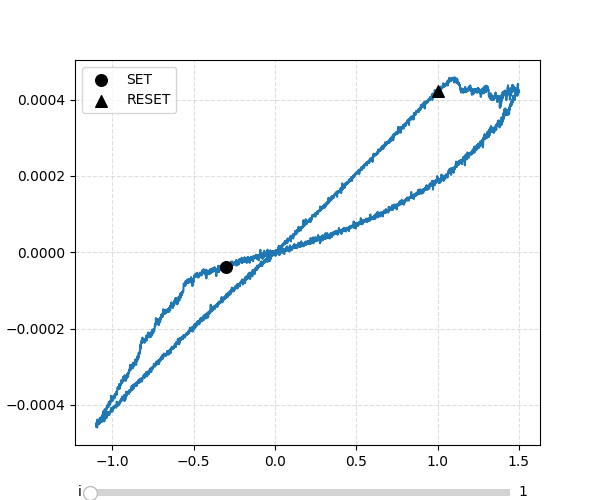

In [510]:
# подбор min(set), min(reset)
# ==============================================================================

min_set_index   = 3300
min_reset_index = 1000

set_widget_backend()
fig, ax = plt.subplots(figsize=(6, 5))

ax.set(title=f"ВАХ (i-й цикл)", xlabel="V, [В]", ylabel="I, [мА]")
ax.yaxis.set_major_formatter(formatter_to_mA)

slider_ax = plt.axes([0.15, 0.0, 0.7, 0.03])
slider = Slider(slider_ax, 'i', 1, N_cycles, valinit=1, valstep=1)

def update(val):
    ax.clear()

    start, end = get_period_indices(arr_v, val - 1 + 1, arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)
    V = arr_v[start : end]; I = arr_i[start : end]

    ax.plot(V, I, color='C0', zorder=99)
    ax.scatter(V[min_set_index], I[min_set_index], color='black', s=70, zorder=100, label="SET")
    ax.scatter(V[min_reset_index], I[min_reset_index], color='black', s=70, zorder=100, label="RESET", marker='^')

    ax.legend(loc='upper left')
    ax.relim()
    ax.grid(True, linestyle='--', alpha=0.4)

    fig.canvas.draw_idle()
    
slider.on_changed(update)
update(1)

plt.show()

### Оптимизация

In [86]:
min_set_index   = 3300
min_reset_index = 1000

In [29]:
N_cycles = 10

In [34]:
# global search

start, _ = get_period_indices(arr_v, 0, arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)
_, end   = get_period_indices(arr_v, N_cycles - 1, arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)

V = arr_v[start : end]; I = arr_i[start : end]
V_zeros = arr_v_zeros[(arr_v_zeros >= start) & (arr_v_zeros <= end)]

params, _ = find_best_schottky_params_global(V, I, V_zeros, maxiter=500, init_population=None, seed=42)

In [48]:
# Оптимизация всех циклов ВАХ-ки

last_population = []
params_list = np.zeros((N_cycles, 5), dtype=np.float64)
for j in tqdm(range(N_cycles), desc="Optimization"):
    start, end = get_period_indices(arr_v, 1 + j, arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)

    # j-й цикл ВАХ-ки
    I = arr_i[start : end]; V = arr_v[start : end]

    # Находим нули и экстремумы
    V_zeros = arr_v_zeros[(arr_v_zeros >= start) & (arr_v_zeros <= end)] - start
    V0_idx = V_zeros[1]; V_max_idx = np.argmax(V); V_min_idx = np.argmin(V)

    # Нормализация
    I_abs_max = np.max(np.abs(I))
    I_normalized = I / I_abs_max
    V_abs_max = np.max([V[V_max_idx], V[V_min_idx]])
    V_normalized = V / V_abs_max

    I_smoothed = filter_current(I)
    k_set = 10
    k_reset = 2

    # reset_index, _ = detect_breakpoint_fastest(I_smoothed[: V_max_idx], weights=reset_weights, x=V[: V_max_idx])
    # set_index, _ =   detect_breakpoint_fastest(I_smoothed[V0_idx : V_min_idx], weights=set_weights, x=V[V0_idx : V_min_idx])
    # set_index += V0_idx

    on_index = get_on_index(V_max_idx, V_min_idx, starts_with_hrs=False)
    off_index = get_off_index(V_max_idx, V_min_idx, starts_with_hrs=False)

    set_index = detect_set(V, I_smoothed, on_index, V0_idx, k_set, starts_with_hrs=False)
    reset_index = detect_reset(V, I_smoothed, off_index, V0_idx, k_reset, starts_with_hrs=False)

    # оптимизация
    params, last_population = find_best_schottky_params(
        V_normalized, I_normalized, V_max_idx, V0_idx, V_min_idx, set_index, reset_index, k_set=k_set, k_reset=k_reset, starts_with_hrs=False,
        maxiter=500, init_population=(last_population) if (j > 0) else (None),
        seed=42)

    # restore from normalized to source    
    params[1 : 3] *= I_abs_max
    params[3 : 5] /= V_abs_max

    params_list[j] = params

Optimization: 100%|██████████| 10/10 [00:11<00:00,  1.12s/it]


In [49]:
# Извлекаем мемристивный ток для всех циклов
arr_i_m = np.zeros_like(arr_i)

for j in range(N_cycles):
    start, end = get_period_indices(arr_v, 1 + j, arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)
    I = arr_i[start : end]; V = arr_v[start : end]

    # Извлекаем мемристивный ток
    # phi, a_f, a_r, b_f, b_r = params
    phi, a_f, a_r, b_f, b_r = params_list[j]
    I_s = extract_schottky_current(V, a_f, a_r, b_f, b_r)
    I_m = extract_memristive_current(I, phi, I_s)
    arr_i_m[start : end] = I_m

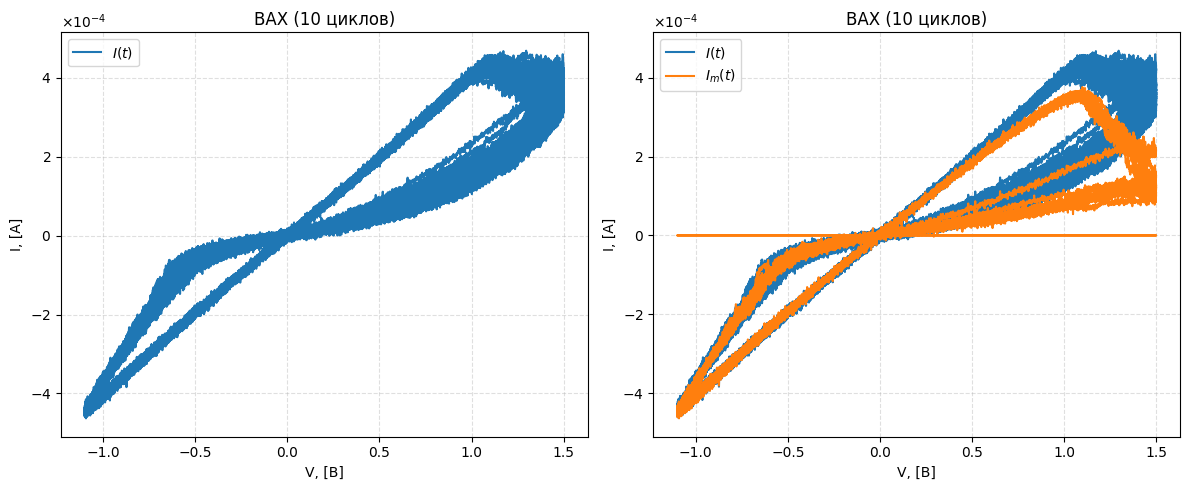

In [50]:
set_inline_backend()

n = 100
start, _ = get_period_indices(arr_v, 1, arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)
_, end   = get_period_indices(arr_v, n - 1, arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)

I = arr_i[start : end]; V = arr_v[start : end]
I_m = arr_i_m[start : end]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(V, I, label='$I(t)$')
ax2.plot(V, I, label='$I(t)$')
ax2.plot(V, I_m, label="$I_m(t)$")

for ax in [ax1, ax2]:
    ax.set(title=f"ВАХ ({N_cycles} циклов)", xlabel="V, [В]", ylabel="I, [А]")
    set_scientific_yaxis(ax)
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc="upper left", fontsize="medium")

plt.tight_layout()
plt.show()

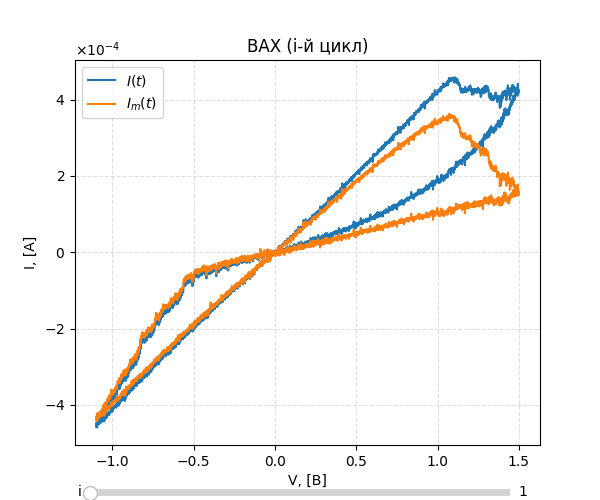

In [51]:
set_widget_backend()

# ==============================================================================

fig, ax = plt.subplots(figsize=(6, 5))

ax.set(title=f"ВАХ (i-й цикл)", xlabel="V, [В]", ylabel="I, [А]")
ax.grid(True, linestyle='--', alpha=0.4)
set_scientific_yaxis(ax)

slider_ax = plt.axes([0.15, 0.0, 0.7, 0.03])
slider = Slider(slider_ax, 'i', 1, N_cycles, valinit=1, valstep=1)

def update(val):
    for line in ax.get_lines():
        line.remove()

    start, end = get_period_indices(arr_v, val, arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)
    V = arr_v[start : end]; I = arr_i[start : end]; I_m = arr_i_m[start : end]

    ax.plot(V, I, color='C0', label='$I(t)$')
    ax.plot(V, I_m, color='C1', label="$I_m(t)$")

    # V_zeros = arr_v_zeros[(arr_v_zeros >= start) & (arr_v_zeros <= end)] - start
    # V0_idx = V_zeros[1]; V_max_idx = np.argmax(V); V_min_idx = np.argmin(V)
    # I_smoothed = filter_current(I)
    # k_set = 10
    # k_reset = 2
    # on_index = get_on_index(V_max_idx, V_min_idx, starts_with_hrs=False)
    # off_index = get_off_index(V_max_idx, V_min_idx, starts_with_hrs=False)
    # set_index = detect_set(V, I_smoothed, on_index, V0_idx, k_set, starts_with_hrs=False)
    # reset_index = detect_reset(V, I_smoothed, off_index, V0_idx, k_reset, starts_with_hrs=False)
    # I_HRS = I[off_index : set_index]; V_HRS = V[off_index : set_index]
    # window = int(0.3 * len(V_HRS))
    # ax.plot(V[V0_idx - window // 2 : V0_idx + window // 2], I[V0_idx - window // 2 : V0_idx + window // 2], color='C2')
    
    ax.relim()
    ax.legend(loc="upper left", fontsize="medium")

    fig.canvas.draw_idle()
    # fig.canvas.draw()

    # output_dir = os.path.join(os.getcwd(), '..', 'temp', 'results', 'optimization')
    # fig.savefig(os.path.join(output_dir, f"cycle_{val:03d}.png"), dpi=100, bbox_inches='tight')
    # plt.close(fig)

slider.on_changed(update)
slider.set_val(1)

# for i in range(N_cycles):
#     slider.set_val(i + 1)

plt.show()

In [547]:
params_list

array([[0.98882707, 0.0004524 , 0.00036171, 2.57851147, 2.39813416],
       [0.98974341, 0.00045367, 0.0005536 , 2.70874837, 2.23201135],
       [0.98947412, 0.00043905, 0.00048773, 2.64593707, 2.24912381],
       [0.98808542, 0.00048751, 0.00053857, 2.51578739, 2.08636012],
       [0.98312061, 0.00075279, 0.00071037, 1.76484122, 1.60025013],
       [0.98972029, 0.00037803, 0.00047125, 2.75671618, 2.26898811],
       [0.98932413, 0.0006227 , 0.00059315, 2.38053912, 2.107829  ],
       [0.98964807, 0.00042816, 0.00050071, 2.65871562, 2.23131737],
       [0.98972259, 0.00046677, 0.00052045, 2.5551322 , 2.25766273],
       [0.99      , 0.00044404, 0.00046325, 2.60897089, 2.20970204]])

## Анализ ВАХ после подбора параметров

### Анализ $R_{ON}$, $R_{OFF}$, $V_{SET}$, $V_{RESET}$

In [ ]:
params_list = np.array([[0.99979456, 0.01841604, 0.02753759, 2.74307016, 2.25557121],
       [0.99974745, 0.01792864, 0.03044526, 2.70788218, 2.20155342],
       [0.99975843, 0.02271833, 0.03093314, 2.53395145, 2.21263618],
       [0.99974469, 0.02046526, 0.03136271, 2.56145454, 2.18829945],
       [0.99886802, 0.0449092 , 0.04444087, 1.23018703, 1.16544187],
       [0.99981058, 0.02309113, 0.03964908, 2.68427883, 2.18697122],
       [0.9997617 , 0.03119519, 0.04097206, 2.3330632 , 2.03685027],
       [0.9997894 , 0.0160455 , 0.03322621, 2.79592022, 2.20817705],
       [0.99981691, 0.02189596, 0.0347627 , 2.66109878, 2.282056  ],
       [0.99983943, 0.01249029, 0.03607381, 3.06471958, 2.18862904],
       [0.99979848, 0.02027175, 0.03429412, 2.72191271, 2.27675754],
       [0.99975264, 0.02601538, 0.02789257, 2.46984468, 2.11215054],
       [0.9998534 , 0.01318743, 0.03633059, 3.12526454, 2.21690083],
       [0.99983349, 0.01132999, 0.03027808, 3.19788117, 2.36628929],
       [0.99983896, 0.01232838, 0.03083746, 3.09861713, 2.38667068],
       [0.9997374 , 0.03009156, 0.03595213, 2.27820547, 1.91080347],
       [0.99972311, 0.00686078, 0.01733857, 3.06583613, 2.34140179],
       [0.99981672, 0.01292288, 0.02480947, 3.05016475, 2.38772858],
       [0.99975446, 0.0176167 , 0.03008775, 2.60900938, 2.04628418],
       [0.99985953, 0.00941096, 0.03502889, 3.40514975, 2.41647335],
       [0.99957773, 0.02860134, 0.03585097, 1.98577995, 1.697855  ],
       [0.9998893 , 0.01776302, 0.04398995, 3.11462202, 2.47155679],
       [0.99986784, 0.01338063, 0.04230656, 3.19645481, 2.27681425],
       [0.99957966, 0.02650846, 0.02682501, 2.12105838, 2.00597524],
       [0.99983184, 0.01579299, 0.0285714 , 2.97823124, 2.42133221],
       [0.9997996 , 0.01965137, 0.03380826, 2.74895294, 2.2113022 ],
       [0.99923654, 0.01562007, 0.01721535, 2.03563153, 1.91291129],
       [0.99978927, 0.0095123 , 0.02800705, 3.03010024, 2.19915709],
       [0.99961777, 0.00898604, 0.01567205, 2.76561874, 2.16861727],
       [0.99962659, 0.01146307, 0.01868532, 2.69049651, 2.28950594],
       [0.99974197, 0.00837338, 0.02312921, 3.07681957, 2.18096701],
       [0.99980983, 0.00195845, 0.02204174, 4.21037762, 2.32225005],
       [0.99962016, 0.00683039, 0.01339076, 2.98603321, 2.3253035 ],
       [0.9995503 , 0.00781123, 0.01442633, 2.80665686, 2.26862565],
       [0.99943433, 0.0118146 , 0.01401292, 2.39973791, 2.17156468],
       [0.99957047, 0.0098169 , 0.01675968, 2.70580392, 2.17911688],
       [0.9993442 , 0.01065271, 0.01395342, 2.37613515, 2.04494559],
       [0.99927217, 0.0075136 , 0.01119202, 2.49826809, 2.0819234 ],
       [0.99951664, 0.0088215 , 0.01361672, 2.67879461, 2.19580073],
       [0.9990442 , 0.01237603, 0.01214881, 2.06313846, 1.92307893],
       [0.99908672, 0.00901317, 0.01139609, 2.24508562, 2.04233705],
       [0.99934937, 0.01145257, 0.01318634, 2.30502374, 2.16473786],
       [0.99916065, 0.01369762, 0.01517367, 2.01830205, 1.90064153],
       [0.9995876 , 0.01227783, 0.01539929, 2.62079766, 2.24524365],
       [0.99951278, 0.01712847, 0.0197925 , 2.23606912, 2.08743084],
       [0.99948431, 0.00672888, 0.01392341, 2.79219052, 2.19859292],
       [0.9994841 , 0.00868298, 0.01551797, 2.53377093, 2.097223  ],
       [0.99938084, 0.00946697, 0.01222567, 2.49247456, 2.13059983],
       [0.99917981, 0.0096233 , 0.01159072, 2.28090992, 2.04261354],
       [0.99955936, 0.00512831, 0.01152827, 2.93609949, 2.27386687],
       [0.99976024, 0.00391074, 0.01874446, 3.48171581, 2.20749717],
       [0.99921764, 0.02599311, 0.02625731, 1.734578  , 1.7420426 ],
       [0.9995186 , 0.01795764, 0.02109448, 2.18847796, 1.99747563],
       [0.99926966, 0.01888156, 0.01897356, 1.98670681, 1.85856475],
       [0.99942254, 0.00478878, 0.01151713, 2.9381783 , 2.2689148 ],
       [0.99957934, 0.0184708 , 0.0239248 , 2.29817712, 1.9916364 ],
       [0.999697  , 0.01625342, 0.02189591, 2.5863506 , 2.25786651],
       [0.99976407, 0.01105069, 0.02464575, 3.01727346, 2.25758666],
       [0.99966623, 0.02256276, 0.02600475, 2.18710832, 2.11088953],
       [0.99963611, 0.02862937, 0.02925596, 2.13712544, 2.05459087],
       [0.99979005, 0.01244574, 0.0296065 , 2.93426239, 2.24449785],
       [0.99980547, 0.01278326, 0.02771761, 2.92961775, 2.3060237 ],
       [0.99980628, 0.00774577, 0.02690738, 3.21635055, 2.30634851],
       [0.99945386, 0.01173766, 0.0134906 , 2.45180199, 2.17466818],
       [0.99970038, 0.00953165, 0.02006815, 2.8383273 , 2.1998554 ],
       [0.99968917, 0.00909264, 0.02164462, 2.83896719, 2.18732998],
       [0.99985703, 0.00328469, 0.02991649, 4.07044736, 2.39761875],
       [0.99979697, 0.00517453, 0.02722565, 3.50734121, 2.28757211],
       [0.99966734, 0.00797589, 0.01775306, 2.98772977, 2.34067326],
       [0.99953043, 0.01386057, 0.01788145, 2.25332914, 2.0496409 ],
       [0.99954268, 0.01966087, 0.02526798, 2.17398695, 1.93418966],
       [0.99976094, 0.00864121, 0.01950134, 3.14429454, 2.33095227],
       [0.99975078, 0.01163557, 0.02335374, 2.90430192, 2.34886713],
       [0.9997583 , 0.01403461, 0.02301272, 2.7845474 , 2.45708341],
       [0.99972497, 0.0146253 , 0.02088016, 2.6740571 , 2.24571124],
       [0.99966761, 0.01855644, 0.02448375, 2.41080782, 2.22442281],
       [0.99969182, 0.01492566, 0.02485516, 2.62501366, 2.23673999],
       [0.99981373, 0.01541788, 0.03143281, 2.87725766, 2.18185507],
       [0.99977171, 0.01601138, 0.03348494, 2.76873814, 2.20241041],
       [0.99987724, 0.01499366, 0.03539642, 3.1757425 , 2.47172015],
       [0.99986578, 0.0061759 , 0.04169352, 3.63947879, 2.24527655],
       [0.99979151, 0.0103409 , 0.01829397, 3.09425452, 2.44823463],
       [0.99985307, 0.00937873, 0.0346432 , 3.31574113, 2.28590957],
       [0.99979095, 0.01818835, 0.02657086, 2.62656571, 2.23042972],
       [0.99985714, 0.02366447, 0.0385529 , 2.74525228, 2.26915586],
       [0.99982857, 0.02371302, 0.0440467 , 2.62047362, 2.1688284 ],
       [0.99984777, 0.00867337, 0.02757249, 3.36277232, 2.3245848 ],
       [0.99982845, 0.02779042, 0.04127567, 2.423774  , 2.09502429],
       [0.99985547, 0.02214972, 0.03931197, 2.76958953, 2.31253841],
       [0.99987833, 0.01321587, 0.02985783, 3.20806613, 2.4786805 ],
       [0.99976906, 0.03157011, 0.04029263, 2.24470274, 1.96872908],
       [0.99984628, 0.01905408, 0.03581016, 2.75070734, 2.25587045],
       [0.99991756, 0.02267789, 0.04177752, 2.87773542, 2.27176236],
       [0.99988225, 0.02993299, 0.03903173, 2.70433891, 2.31745661],
       [0.99989458, 0.01049676, 0.04451309, 3.50712027, 2.43427661],
       [0.99989331, 0.01232645, 0.03860674, 3.33811904, 2.42490997],
       [0.99981131, 0.02347954, 0.02981432, 2.54269342, 2.33536396],
       [0.99984061, 0.01982752, 0.03243821, 2.75679599, 2.32897426],
       [0.99981045, 0.03223655, 0.04331175, 2.45850483, 2.16150533],
       [0.999818  , 0.02196294, 0.0370089 , 2.68459695, 2.2377005 ]])

In [768]:
# collect R_ON, R_OFF, SET, RESET

R_ON    = np.zeros(N_cycles, dtype=np.float64)
R_OFF   = np.zeros(N_cycles, dtype=np.float64)
SET     = np.zeros(N_cycles, dtype=int)
RESET   = np.zeros(N_cycles, dtype=int)

for j in tqdm(range(N_cycles)):
    start, end = get_period_indices(arr_v, 1 + j, arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)

    phi, a_f, a_r, b_f, b_r = params_list[j]

    # i-й цикл ВАХ-ки
    I = arr_i[start : end]; V = arr_v[start : end]
    I_s = extract_schottky_current(V, a_f, a_r, b_f, b_r)
    I_m = extract_memristive_current(I, phi, I_s)
    I_m_smoothed = filter_current(I_m, high_smooth=True)

    # Находим нули и экстремумы
    V_zeros = arr_v_zeros[(arr_v_zeros >= start) & (arr_v_zeros <= end)] - start
    V0_idx = V_zeros[1]; V_max_idx = np.argmax(V); V_min_idx = np.argmin(V)

    # set, reset
    reset_index = detect_reset(V, I_m_smoothed, V_max_idx, V0_idx, V_min_idx, starts_with_hrs=False)
    set_index = detect_set(V, I_m_smoothed, V_max_idx, V0_idx, V_min_idx, starts_with_hrs=False)

    # Проводиомсть
    G_m = calculate_G(V, I_m)

    # filter_intervals = [(valley_index, len(v)), (0, reset_index), (peak_index, set_index)]
    # filter_window = 201
    interpolate_window = int(0.05 * len(V))

    # Фильтрация проводимости + устранение разрывов
    for zero_index in V_zeros:
        interpolate_break_median(G_m, zero_index, window_size=interpolate_window)
    # g_m_filtered = G_m.copy()
    # for filter_interval in filter_intervals:
    #     f_start, f_end = filter_interval
    #     g_m_filtered[f_start : f_end] = savgol_filter(g_m[f_start : f_end], window_length=filter_window, polyorder=3, mode='mirror')
    
    # Переменная состояния X
    g_m_on = np.max(G_m); g_m_off = np.min(G_m)
    X = (G_m - g_m_off) / (g_m_on - g_m_off)

    # R_ON, R_OFF
    R_ON[j] = 1 / g_m_on
    R_OFF[j] = 1 / g_m_off

    # SET, RESET
    SET[j] = set_index
    RESET[j] = reset_index

100%|██████████| 100/100 [00:00<00:00, 842.55it/s]


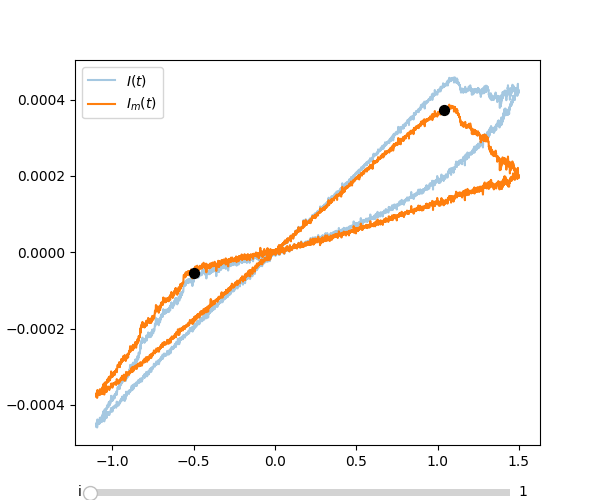

In [759]:
set_widget_backend()

# ==============================================================================

fig, ax = plt.subplots(figsize=(6, 5))

ax.set(title=f"ВАХ (i-й цикл)", xlabel="V, [В]", ylabel="I, [мА]")
ax.grid(True, linestyle='--', alpha=0.4)
ax.yaxis.set_major_formatter(formatter_to_mA)

slider_ax = plt.axes([0.15, 0.0, 0.7, 0.03])
slider = Slider(slider_ax, 'i', 1, N_cycles, valinit=1, valstep=1)

def update(val):
    ax.clear()

    index = val - 1
    start, end = get_period_indices(arr_v, val + 1 - 1, arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)

    # i-й цикл ВАХ-ки
    I = arr_i[start : end]; V = arr_v[start : end]
    I_s = extract_schottky_current(V, a_f, a_r, b_f, b_r)
    I_m = extract_memristive_current(I, phi, I_s)

    ax.plot(V, I, color='C0', label='$I(t)$', alpha=0.4, zorder=100)
    ax.plot(V, I_m, color='C1', label="$I_m(t)$", zorder=100)

    set_index = SET[index]; reset_index = RESET[index]
    ax.scatter(V[set_index], I_m[set_index], color='black', s=50, zorder=101)
    ax.scatter(V[reset_index], I_m[reset_index], color='black', s=50, zorder=101)
    
    ax.relim()
    ax.legend(loc="upper left", fontsize="medium")

    fig.canvas.draw_idle()
    
slider.on_changed(update)
update(1)

plt.show()

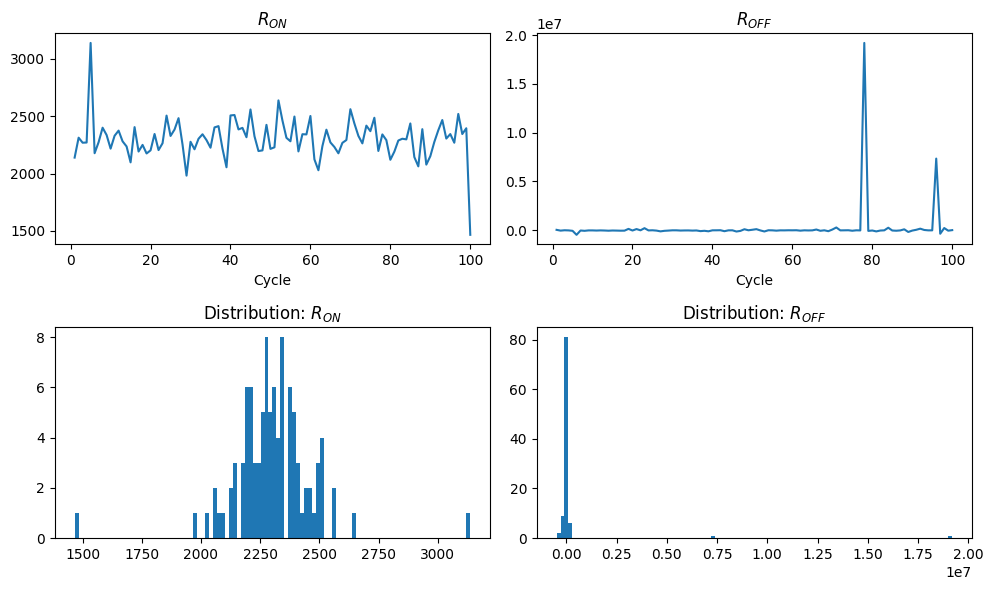

In [786]:
set_inline_backend()

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
axes = axes.flatten()
ax1, ax2, ax3, ax4  = axes

x = np.linspace(1, N_cycles, N_cycles)
ax1.plot(x, R_ON)
ax2.plot(x, R_OFF)

ax1.set(title='$R_{ON}$', xlabel='Cycle')
ax2.set(title='$R_{OFF}$', xlabel='Cycle')
ax3.set(title='Distribution: $R_{ON}$')
ax4.set(title='Distribution: $R_{OFF}$')

ax3.hist(R_ON, bins=N_cycles)
ax4.hist(R_OFF, bins=N_cycles)

plt.tight_layout()
plt.show()

In [764]:
V_SET = np.zeros(N_cycles, dtype=np.float64)
V_RESET = np.zeros(N_cycles, dtype=np.float64)

for j in range(N_cycles):
    start, end = get_period_indices(arr_v, 1 + j, arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)

    V_SET[j] = arr_v[start : end][SET[j]]
    V_RESET[j] = arr_v[start : end][RESET[j]]

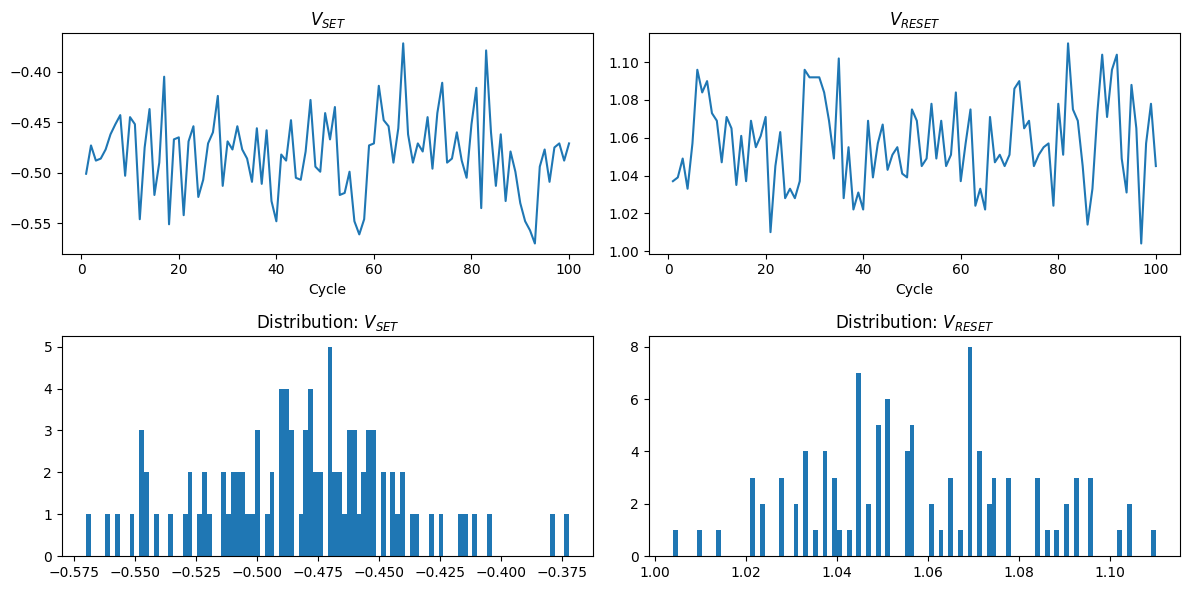

In [785]:
set_inline_backend()

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
axes = axes.flatten()
ax1, ax2, ax3, ax4  = axes

x = np.linspace(1, N_cycles, N_cycles)
ax1.plot(x, V_SET)
ax2.plot(x, V_RESET)

ax1.set(title='$V_{SET}$', xlabel='Cycle')
ax2.set(title='$V_{RESET}$', xlabel='Cycle')
ax3.set(title='Distribution: $V_{SET}$')
ax4.set(title='Distribution: $V_{RESET}$')

ax3.hist(V_SET, bins=N_cycles)
ax4.hist(V_RESET, bins=N_cycles)

plt.tight_layout()
plt.show()

### Анализ $R_{ON}$, $R_{OFF}$, $V_{SET}$, $V_{RESET}$ №2

Взяли один раз подобранные параметры и прогнали на них все циклы 

In [788]:
target_params_index = 0

In [790]:
# Извлекаем мемристивный ток для всех циклов
arr_i_m = np.zeros_like(arr_i)

for j in range(N_cycles):
    start, end = get_period_indices(arr_v, 1 + j, arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)
    I = arr_i[start : end]; V = arr_v[start : end]

    # Извлекаем мемристивный ток
    phi, a_f, a_r, b_f, b_r = params_list[target_params_index]
    I_s = extract_schottky_current(V, a_f, a_r, b_f, b_r)
    I_m = extract_memristive_current(I, phi, I_s)
    arr_i_m[start : end] = I_m

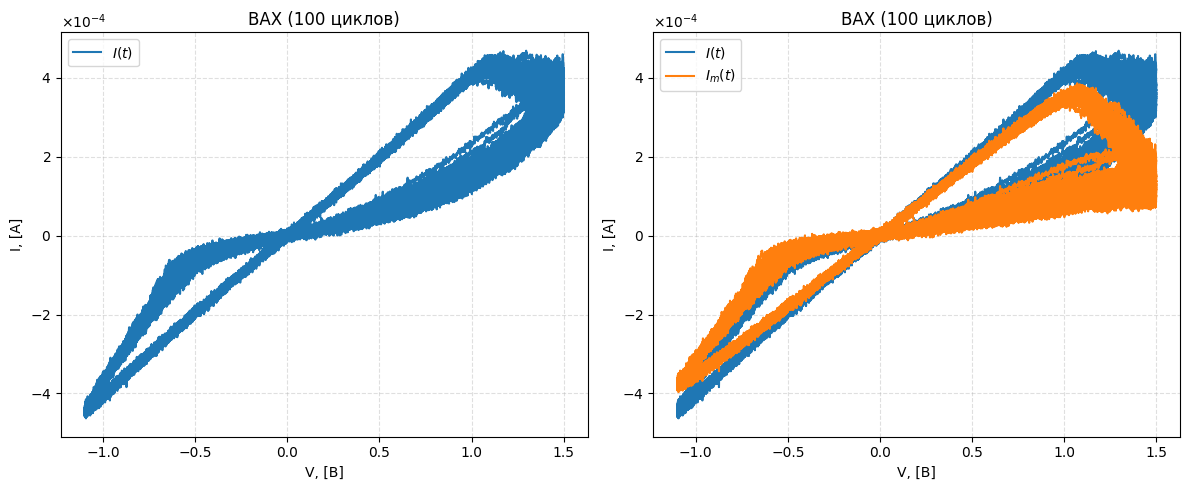

In [791]:
set_inline_backend()

n = 100
start, _ = get_period_indices(arr_v, 1, arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)
_, end   = get_period_indices(arr_v, n - 1, arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)

I = arr_i[start : end]; V = arr_v[start : end]
I_m = arr_i_m[start : end]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(V, I, label='$I(t)$')
ax2.plot(V, I, label='$I(t)$')
ax2.plot(V, I_m, label="$I_m(t)$")

for ax in [ax1, ax2]:
    ax.set(title=f"ВАХ ({N_cycles} циклов)", xlabel="V, [В]", ylabel="I, [А]")
    set_scientific_yaxis(ax)
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc="upper left", fontsize="medium")

plt.tight_layout()
plt.show()

In [792]:
# collect R_ON, R_OFF, SET, RESET

R_ON    = np.zeros(N_cycles, dtype=np.float64)
R_OFF   = np.zeros(N_cycles, dtype=np.float64)
SET     = np.zeros(N_cycles, dtype=int)
RESET   = np.zeros(N_cycles, dtype=int)

for j in tqdm(range(N_cycles)):
    start, end = get_period_indices(arr_v, 1 + j, arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)

    phi, a_f, a_r, b_f, b_r = params_list[target_params_index]

    # i-й цикл ВАХ-ки
    I = arr_i[start : end]; V = arr_v[start : end]
    I_s = extract_schottky_current(V, a_f, a_r, b_f, b_r)
    I_m = extract_memristive_current(I, phi, I_s)
    I_m_smoothed = filter_current(I_m, high_smooth=True)

    # Находим нули и экстремумы
    V_zeros = arr_v_zeros[(arr_v_zeros >= start) & (arr_v_zeros <= end)] - start
    V0_idx = V_zeros[1]; V_max_idx = np.argmax(V); V_min_idx = np.argmin(V)

    # set, reset
    reset_index = detect_reset(V, I_m_smoothed, V_max_idx, V0_idx, V_min_idx, starts_with_hrs=False)
    set_index = detect_set(V, I_m_smoothed, V_max_idx, V0_idx, V_min_idx, starts_with_hrs=False)

    # Проводиомсть
    G_m = calculate_G(V, I_m)

    # filter_intervals = [(valley_index, len(v)), (0, reset_index), (peak_index, set_index)]
    # filter_window = 201
    interpolate_window = int(0.05 * len(V))

    # Фильтрация проводимости + устранение разрывов
    for zero_index in V_zeros:
        interpolate_break_median(G_m, zero_index, window_size=interpolate_window)
    # g_m_filtered = G_m.copy()
    # for filter_interval in filter_intervals:
    #     f_start, f_end = filter_interval
    #     g_m_filtered[f_start : f_end] = savgol_filter(g_m[f_start : f_end], window_length=filter_window, polyorder=3, mode='mirror')
    
    # Переменная состояния X
    g_m_on = np.max(G_m); g_m_off = np.min(G_m)
    X = (G_m - g_m_off) / (g_m_on - g_m_off)

    # R_ON, R_OFF
    R_ON[j] = 1 / g_m_on
    R_OFF[j] = 1 / g_m_off

    # SET, RESET
    SET[j] = set_index
    RESET[j] = reset_index

100%|██████████| 100/100 [00:00<00:00, 531.95it/s]


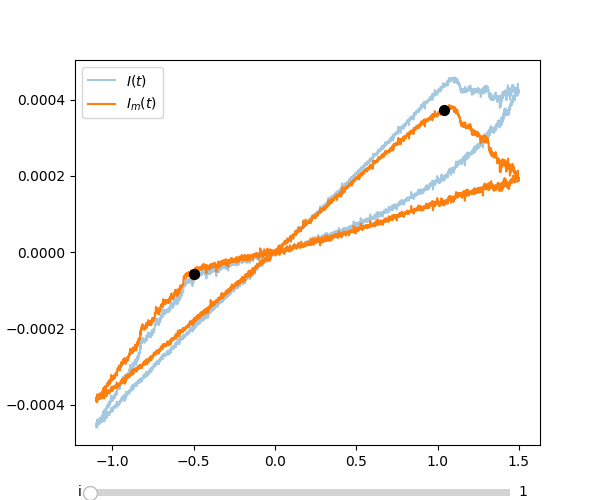

In [793]:
set_widget_backend()

# ==============================================================================

fig, ax = plt.subplots(figsize=(6, 5))

ax.set(title=f"ВАХ (i-й цикл)", xlabel="V, [В]", ylabel="I, [мА]")
ax.grid(True, linestyle='--', alpha=0.4)
ax.yaxis.set_major_formatter(formatter_to_mA)

slider_ax = plt.axes([0.15, 0.0, 0.7, 0.03])
slider = Slider(slider_ax, 'i', 1, N_cycles, valinit=1, valstep=1)

def update(val):
    ax.clear()

    index = val - 1
    start, end = get_period_indices(arr_v, val + 1 - 1, arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)

    # i-й цикл ВАХ-ки
    I = arr_i[start : end]; V = arr_v[start : end]
    I_s = extract_schottky_current(V, a_f, a_r, b_f, b_r)
    I_m = extract_memristive_current(I, phi, I_s)

    ax.plot(V, I, color='C0', label='$I(t)$', alpha=0.4, zorder=100)
    ax.plot(V, I_m, color='C1', label="$I_m(t)$", zorder=100)

    set_index = SET[index]; reset_index = RESET[index]
    ax.scatter(V[set_index], I_m[set_index], color='black', s=50, zorder=101)
    ax.scatter(V[reset_index], I_m[reset_index], color='black', s=50, zorder=101)
    
    ax.relim()
    ax.legend(loc="upper left", fontsize="medium")

    fig.canvas.draw_idle()
    
slider.on_changed(update)
update(1)

plt.show()

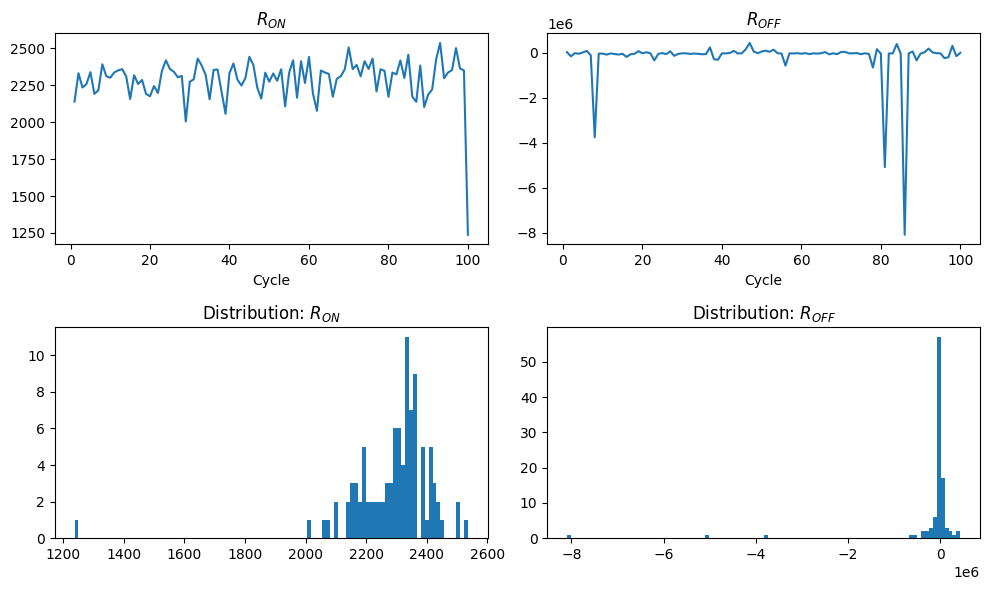

In [794]:
set_inline_backend()

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
axes = axes.flatten()
ax1, ax2, ax3, ax4  = axes

x = np.linspace(1, N_cycles, N_cycles)
ax1.plot(x, R_ON)
ax2.plot(x, R_OFF)

ax1.set(title='$R_{ON}$', xlabel='Cycle')
ax2.set(title='$R_{OFF}$', xlabel='Cycle')
ax3.set(title='Distribution: $R_{ON}$')
ax4.set(title='Distribution: $R_{OFF}$')

ax3.hist(R_ON, bins=N_cycles)
ax4.hist(R_OFF, bins=N_cycles)

plt.tight_layout()
plt.show()

In [795]:
V_SET = np.zeros(N_cycles, dtype=np.float64)
V_RESET = np.zeros(N_cycles, dtype=np.float64)

for j in range(N_cycles):
    start, end = get_period_indices(arr_v, 1 + j, arr_v_zeros, segments_per_period=2, period_start_segment_idx=0)

    V_SET[j] = arr_v[start : end][SET[j]]
    V_RESET[j] = arr_v[start : end][RESET[j]]

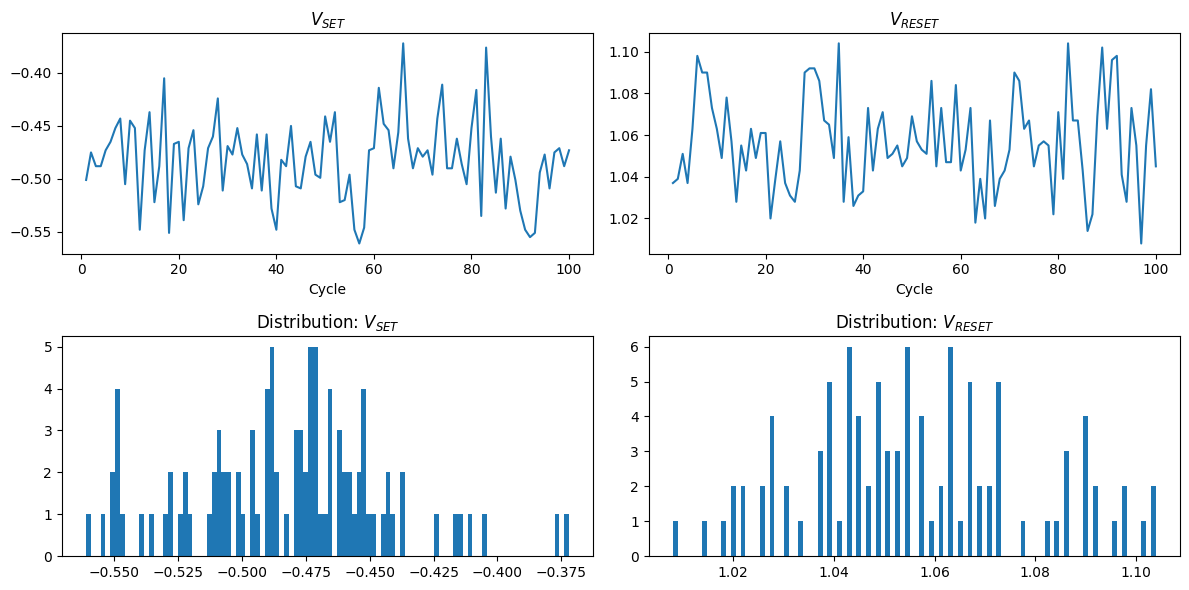

In [796]:
set_inline_backend()

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
axes = axes.flatten()
ax1, ax2, ax3, ax4  = axes

x = np.linspace(1, N_cycles, N_cycles)
ax1.plot(x, V_SET)
ax2.plot(x, V_RESET)

ax1.set(title='$V_{SET}$', xlabel='Cycle')
ax2.set(title='$V_{RESET}$', xlabel='Cycle')
ax3.set(title='Distribution: $V_{SET}$')
ax4.set(title='Distribution: $V_{RESET}$')

ax3.hist(V_SET, bins=N_cycles)
ax4.hist(V_RESET, bins=N_cycles)

plt.tight_layout()
plt.show()

### Моделирование

In [53]:
from scipy.integrate import solve_ivp

In [194]:
def dX(X, V, V_on, V_off, tau, beta):
    return 1/tau * ( (1/(1 + np.exp(-beta*(V-V_on))))*(1-X) - (1 - 1/(1 + np.exp(-beta*(V + V_off))))*X )

def simulate_X(V, V_on, V_off, tau, beta, X_init, h):
    n_steps = len(V)
    t_eval = np.linspace(0, (n_steps - 1) * h, n_steps)
    t_span = (t_eval[0], t_eval[-1])
    
    def rhs(t, y):
        X = y[0]

        i = int(np.round(t / h))
        
        # Вероятности переключения (точная копия вашей формулы)
        P_ON  = 1.0 / (1.0 + np.exp(-beta * (V[i] - V_on)))
        P_OFF = 1.0 - 1.0 / (1.0 + np.exp(-beta * (V[i] + V_off)))
        
        # Правая часть ОДУ: dX/dt
        dXdt = (P_ON * (1.0 - X) - P_OFF * X) / tau
        return [dXdt]

    # Интегрирование
    sol = solve_ivp(rhs, t_span, [X_init], t_eval=t_eval, 
                    method='RK45', rtol=1e-6, atol=1e-9)
    
    return sol.y[0]

    # NOTE: old code
    # n_steps = len(V)
    # X_steps = np.zeros( n_steps, dtype=np.float64 )

    # X_steps[0] = X_init
    # for i in range(1, n_steps):
    #     X_steps[i] = X_steps[i - 1] + h * dX(X_steps[i - 1], V[i - 1], V_on, V_off, tau, beta)

    # return X_steps

def simulate_G(X, R_on, R_off):
    return X/R_on + (1-X)/R_off

In [76]:
cycle_index = 1

start = zero_indices[cycle_index * 2]; end = zero_indices[(cycle_index + 1) * 2]

t = T[start : end]
v = V[start : end]; i = I[start : end]
i_m = I_m[start : end]

r = np.empty_like(v)
np.divide(v, i_m, out=r, where=(i_m != 0))
r[i_m == 0] = np.inf

for zero_index in zero_indices[0 : 2 + 1]:
    interpolate_break_median(r, zero_index, int(0.05 * len(V)))

V_ON = np.max(v)
V_OFF = np.min(v)
R_ON = np.min(r)
R_OFF = np.max(r)

R_ON = 2500
R_OFF = 6667

print(f"V_on = {V_ON}")
print(f"V_off = {V_OFF}")
print(f"R_on = {R_ON}")
print(f"R_off = {R_OFF}")

V_on = 1.5
V_off = -1.1
R_on = 2500
R_off = 6667


In [56]:
10**6 / 400

2500.0

In [77]:
g = np.empty_like(v)
np.divide(i_m, v, out=g, where=(v != 0))
g[v == 0] = np.inf
for zero_index in zero_indices[cycle_index * 2 : (cycle_index + 1) * 2 + 1]:
    interpolate_break_median(g, zero_index, int(0.05 * len(v)))

# Фильтрация + Устранение разрывов
g_filtered = g.copy()
for filter_interval in target_filter_intervals:
    f_start, f_end = filter_interval
    g_filtered[f_start : f_end] = savgol_filter(g[f_start : f_end], window_length=filter_window, polyorder=3, mode='mirror')
for zero_index in zero_indices:
    interpolate_break_median(g_filtered, zero_index, window_size=interpolate_window)

# Переменная состояния X
G_on = np.max(g_filtered); G_off = np.min(g_filtered)
X = (g_filtered - G_off) / (G_on - G_off)

# R_on = 1 / G_on; R_off = 1 / G_off
# X = g_filtered * R_on * R_off - R_on / (R_off - R_on)

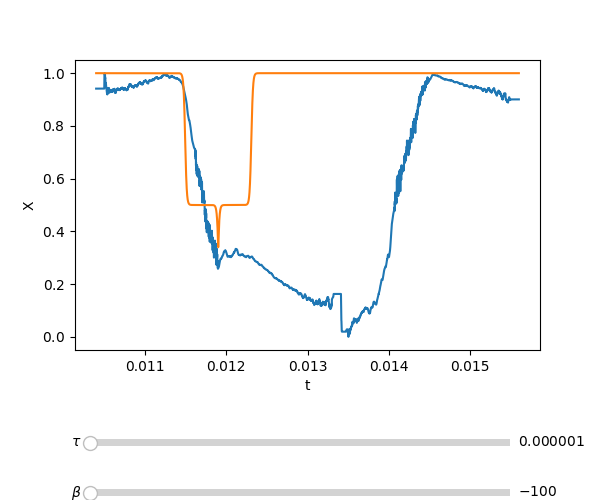

In [78]:
set_widget_backend()

# ==============================================================================

fig, ax = plt.subplots(figsize=(6, 5))
plt.subplots_adjust(bottom=0.3)

ax.set_xlabel("t"); ax.set_ylabel("X")
ax.plot(t, X)
set_scientific_yaxis(ax)
simulated_line, = ax.plot([])

tau_range = (1e-6, 1e-2, 1e-6)
beta_range = (-100, 100, 0.1)

slider_tau_ax = plt.axes([0.15, 0.1, 0.7, 0.03])
slider_beta_ax = plt.axes([0.15, 0.0, 0.7, 0.03])
# =====
slider_tau = Slider(slider_tau_ax, r'$\tau$', tau_range[0], tau_range[1], valinit=tau_range[0], valstep=tau_range[2])
slider_beta = Slider(slider_beta_ax, r'$\beta$', beta_range[0], beta_range[1], valinit=beta_range[0], valstep=beta_range[2])

def update(tau, beta):
    X_sim = simulate_X(v, V_ON, V_OFF, tau, beta, 1, 1e-6)

    simulated_line.set_data(t, X_sim)

    ax.relim()
    ax.autoscale_view()

    fig.canvas.draw_idle()

def update_tau(val):
    update(val, slider_beta.val)
def update_beta(val):
    update(slider_tau.val, val)
    
slider_tau.on_changed(update_tau)
slider_beta.on_changed(update_beta)

update(tau_range[0], beta_range[0])

plt.show()

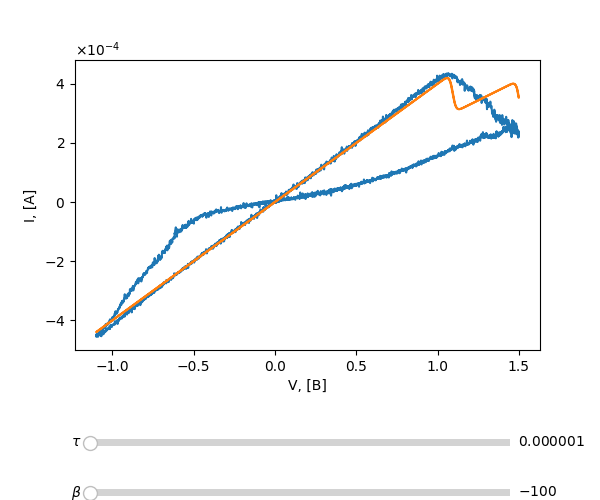

In [109]:
set_widget_backend()

# ==============================================================================

fig, ax = plt.subplots(figsize=(6, 5))
plt.subplots_adjust(bottom=0.3)

ax.set_xlabel("V, [В]"); ax.set_ylabel("I, [А]")
ax.plot(v, i_m)
set_scientific_yaxis(ax)
simulated_line, = ax.plot([])

tau_range = (1e-6, 1e-2, 1e-6)
beta_range = (-100, 100, 0.1)

slider_tau_ax = plt.axes([0.15, 0.1, 0.7, 0.03])
slider_beta_ax = plt.axes([0.15, 0.0, 0.7, 0.03])
# =====
slider_tau = Slider(slider_tau_ax, r'$\tau$', tau_range[0], tau_range[1], valinit=tau_range[0], valstep=tau_range[2])
slider_beta = Slider(slider_beta_ax, r'$\beta$', beta_range[0], beta_range[1], valinit=beta_range[0], valstep=beta_range[2])

def update(tau, beta):
    X_sim = simulate_X(v, V_ON, V_OFF, tau, beta, 1, 1e-6)
    G_sim = simulate_G(X_sim, R_ON, R_OFF)

    i_sim = v * G_sim
    simulated_line.set_data(v, i_sim)

    ax.relim()
    ax.autoscale_view()

    fig.canvas.draw_idle()

def update_tau(val):
    update(val, slider_beta.val)
def update_beta(val):
    update(slider_tau.val, val)
    
slider_tau.on_changed(update_tau)
slider_beta.on_changed(update_beta)

update(tau_range[0], beta_range[0])

plt.show()

# Данные Matlab

In [477]:
from scipy import io

In [481]:
path_to_i = "C:/Dev/Data/University/VKR/data_processing_matlab/I_ref_6k.mat"
path_to_v = "C:/Dev/Data/University/VKR/data_processing_matlab/Vm_ref_6k.mat"

arr_v = io.loadmat(path_to_v)['Vm_ref'].flatten()
arr_i = io.loadmat(path_to_i)['I_ref'].flatten()

# arr_v = np.loadtxt(path_to_v, delimiter=',').flatten()
# arr_i = np.loadtxt(path_to_i, delimiter=',').flatten()

print(f"Input length: {len(arr_v)}")
print(f"Output length: {len(arr_i)}")

Input length: 5200
Output length: 5200


In [456]:
N = len(arr_v)
print(f"Time range (seconds): [0; {(N - 1)*dt}]")

Time range (seconds): [0; 0.005199]


In [485]:
T = build_time_array(0, len(arr_v)*dt, dt, endpoint=False)
I = arr_i; V = arr_v
I_smoothed = filter_current(I)

# Находим нули и экстремумы
V_zeros = [0, 3000, len(V) - 1]

V0_idx = V_zeros[1]; V_max_idx = np.argmax(V); V_min_idx = np.argmin(V)

# Проводиомсть
G = calculate_G(V, I)

In [492]:
# оптимизация

# Нормализация
I_abs_max = np.max(np.abs(I))
I_normalized = I / I_abs_max
V_abs_max = np.max(np.abs(V))
V_normalized = V / V_abs_max

on_index = get_on_index(V_max_idx, V_min_idx, starts_with_hrs=False)
off_index = get_off_index(V_max_idx, V_min_idx, starts_with_hrs=False)

k_set = 10.0
k_reset = 5.0

# Находим области ON, OFF
set_index = detect_set(V, I_smoothed, on_index, V0_idx, k_set, starts_with_hrs=False)
reset_index = detect_reset(V, I_smoothed, off_index, V0_idx, k_reset, starts_with_hrs=False)

# оптимизация
params, _ = find_best_schottky_params(
    V_normalized, I_normalized, V_max_idx, V0_idx, V_min_idx, set_index, reset_index, k_set=k_set, k_reset=k_reset, 
    maxiter=500)

params[1 : 3] *= I_abs_max
params[3 : 5] /= V_abs_max

In [ ]:
# raw_params = params.copy()
# raw_params[1 : 3] *= I_max
# raw_params[3 : 5] /= V_max

# print(f"normalized: {params}")
# print(f"raw: {raw_params}")

In [493]:
manual_params = {
    "phi": 0.97,
    "a_f": 0.00005,
    "a_r": 0.0000045,
    "b_f": 3.3,
    "b_r": 8
}

for i, key in enumerate(manual_params.keys()):
    if i == 1 or i == 2:
        print(f"{key}:     {manual_params[key]:<10.3e}      {params[i]:.3e}")
    else:
        print(f"{key}:     {manual_params[key]:<10.3f}      {params[i]:.3f}")

phi:     0.970           0.990
a_f:     5.000e-05       1.665e-04
a_r:     4.500e-06       3.659e-06
b_f:     3.300           3.174
b_r:     8.000           9.173


In [494]:
# Извлекаем мемристивный ток
# phi, a_f, a_r, b_f, b_r = params
# I_s = extract_schottky_current(V_normalized, a_f, a_r, b_f, b_r)
# I_m = extract_memristive_current(I_normalized, phi, I_s)
# I_m *= I_max

phi, a_f, a_r, b_f, b_r = params
I_s = extract_schottky_current(V, a_f, a_r, b_f, b_r)
I_m = extract_memristive_current(I, phi, I_s)

phi, a_f, a_r, b_f, b_r = manual_params.values()
I_s = extract_schottky_current(V, a_f, a_r, b_f, b_r)
I_m_manual = extract_memristive_current(I, phi, I_s)

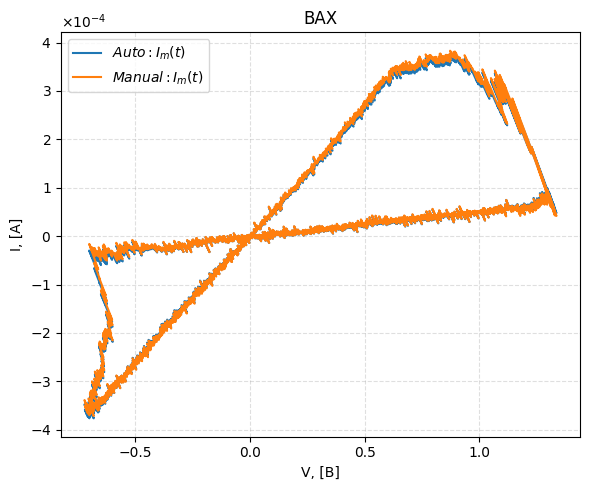

In [496]:
set_inline_backend()
# ==============================================================================

fig, ax = plt.subplots(figsize=(6, 5))

# ax.plot(V, I, label='$I(t)$')
ax.plot(V, I_m, label="$Auto: I_m(t)$")
ax.plot(V, I_m_manual, label="$Manual: I_m(t)$")

ax.set(title="ВАХ", xlabel="V, [В]", ylabel="I, [А]")
set_scientific_yaxis(ax)
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend(loc="upper left", fontsize="medium")

plt.tight_layout()
plt.show()

In [497]:
# Проводиомсть
G_m = calculate_G(V, I_m)
G_m_manual = calculate_G(V, I_m_manual)

In [498]:
# Сглаживание тока
I_smoothed = filter_current(I, high_smooth=True)
I_m_smoothed = filter_current(I_m, high_smooth=True)
I_m_manual_smoothed = filter_current(I_m_manual, high_smooth=True)

# находим обалсти HRS, LRS
source_reset = detect_reset(I_smoothed, V_max_idx, V0_idx, V_min_idx, starts_with_hrs=False)
source_set = detect_set(I_smoothed, V_max_idx, V0_idx, V_min_idx, starts_with_hrs=False)
target_reset = detect_reset(I_m_smoothed, V_max_idx, V0_idx, V_min_idx, starts_with_hrs=False)
target_set = detect_set(I_m_smoothed, V_max_idx, V0_idx, V_min_idx, starts_with_hrs=False)
manual_reset = detect_reset(I_m_manual_smoothed, V_max_idx, V0_idx, V_min_idx, starts_with_hrs=False)
manual_set = detect_set(I_m_manual_smoothed, V_max_idx, V0_idx, V_min_idx, starts_with_hrs=False)

# Параметры обработки
# ширина разрыва (5% от длины цикла)
break_width = (0.05 * len(V))
# длины окон для сглаживания (для предобработки + устранения разрывов)
filter_window = 151
interpolate_window = int(0.2e-3 // dt)
# области преобработочной фильтрации (HRS + LRS)
source_filter_intervals = [(V_min_idx, len(V)), (0, source_reset), (V_max_idx, source_set)]
target_filter_intervals = [(V_min_idx, len(V)), (0, target_reset), (V_max_idx, target_set)]
manual_filter_intervals = [(V_min_idx, len(V)), (0, manual_reset), (V_max_idx, manual_set)]

# Фильтрация + Устранение разрывов
G_filtered = G.copy()
for filter_interval in source_filter_intervals:
    f_start, f_end = filter_interval
    G_filtered[f_start : f_end] = savgol_filter(G[f_start : f_end], window_length=filter_window, polyorder=3, mode='mirror')

G_m_filtered = G_m.copy()
for filter_interval in target_filter_intervals:
    f_start, f_end = filter_interval
    G_m_filtered[f_start : f_end] = savgol_filter(G_m[f_start : f_end], window_length=filter_window, polyorder=3, mode='mirror')

G_m_manual_filtered = G_m.copy()
for filter_interval in manual_filter_intervals:
    f_start, f_end = filter_interval
    G_m_manual_filtered[f_start : f_end] = savgol_filter(G_m_manual[f_start : f_end], window_length=filter_window, polyorder=3, mode='mirror')
    
for zero_index in V_zeros:
    interpolate_break_median(G_filtered, zero_index, window_size=interpolate_window)
    interpolate_break_median(G_m_filtered, zero_index, window_size=interpolate_window)
    interpolate_break_median(G_m_manual_filtered, zero_index, window_size=interpolate_window)

# Переменная состояния X
G_m_on = np.max(G_m_filtered); G_m_off = np.min(G_m_filtered)
G_m_normalized = (G_m_filtered - G_m_off) / (G_m_on - G_m_off)

G_m_on = np.max(G_m_manual_filtered); G_m_off = np.min(G_m_manual_filtered)
G_m_manual_normalized = (G_m_manual_filtered - G_m_off) / (G_m_on - G_m_off)

# Производная переменной состояния X
G_m_normalized_diff = np.zeros_like(G_m_normalized)
G_m_normalized_diff[:-1] = np.diff(G_m_normalized)

G_m_manual_normalized_diff = np.zeros_like(G_m_manual_normalized)
G_m_manual_normalized_diff[:-1] = np.diff(G_m_manual_normalized)

IndexError: invalid index to scalar variable.

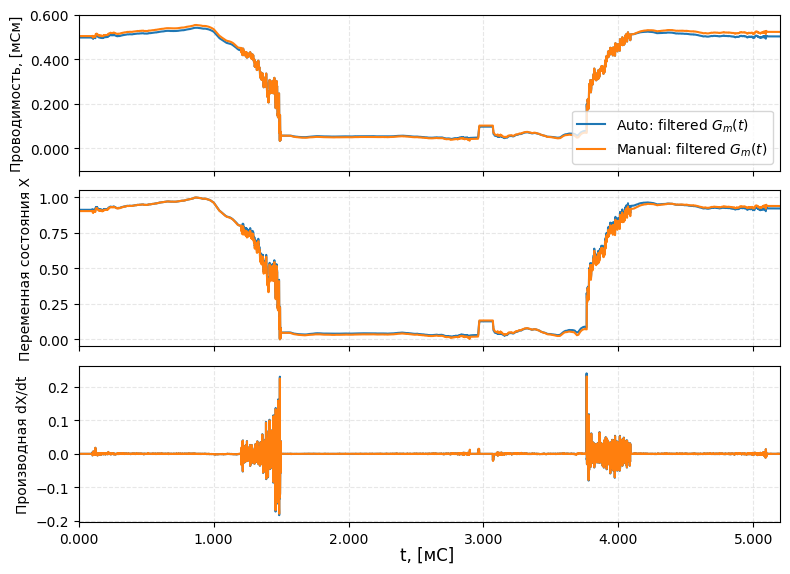

In [672]:
set_inline_backend()

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8, 6), sharex=True)

# ax1.plot(T, G_m, label='raw $G_m(t)$')

ax1.plot(T, G_m_filtered, label='Auto: filtered $G_m(t)$')
ax2.plot(T, G_m_normalized)
ax3.plot(T, G_m_normalized_diff)

ax1.plot(T, G_m_manual_filtered, label='Manual: filtered $G_m(t)$')
ax2.plot(T, G_m_manual_normalized)
ax3.plot(T, G_m_manual_normalized_diff)

ax1.legend(loc="lower right", fontsize="medium")

for ax in [ax1, ax2, ax3]:
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.set_xlim(T[0], T[-1])

ax1.set_ylim(-0.1e-3, 0.6e-3)
ax1.yaxis.set_major_formatter(formatter_to_mSm)

ax1.set_ylabel("Проводимость, [мСм]")
ax2.set_ylabel("Переменная состояния X")
ax3.set_ylabel("Производная dX/dt")

fig.supxlabel('t, [мС]', x=0.54, y=0.05)
fig.gca().xaxis.set_major_formatter(formatter_to_mS)

plt.tight_layout()
plt.show()

In [622]:
# Сглаживание тока
I_smoothed = filter_current(I, high_smooth=True)
I_m_smoothed = filter_current(I_m, high_smooth=True)
I_m_manual_smoothed = filter_current(I_m_manual, high_smooth=True)

# находим обалсти HRS, LRS
source_reset = detect_reset(I_smoothed, V_max_idx, V0_idx, V_min_idx, starts_with_hrs=False)
source_set = detect_set(I_smoothed, V_max_idx, V0_idx, V_min_idx, starts_with_hrs=False)
target_reset = detect_reset(I_m_smoothed, V_max_idx, V0_idx, V_min_idx, starts_with_hrs=False)
target_set = detect_set(I_m_smoothed, V_max_idx, V0_idx, V_min_idx, starts_with_hrs=False)
manual_reset = detect_reset(I_m_manual_smoothed, V_max_idx, V0_idx, V_min_idx, starts_with_hrs=False)
manual_set = detect_set(I_m_manual_smoothed, V_max_idx, V0_idx, V_min_idx, starts_with_hrs=False)

# Параметры обработки
# ширина разрыва (5% от длины цикла)
break_width = (0.05 * len(V))
# длины окон для сглаживания (для предобработки + устранения разрывов)
filter_window = 151
interpolate_window = int(0.2e-3 // dt)
# области преобработочной фильтрации (HRS + LRS)
source_filter_intervals = [(V_min_idx, len(V)), (0, source_reset), (V_max_idx, source_set)]
target_filter_intervals = [(V_min_idx, len(V)), (0, target_reset), (V_max_idx, target_set)]
manual_filter_intervals = [(V_min_idx, len(V)), (0, manual_reset), (V_max_idx, manual_set)]

# Фильтрация + Устранение разрывов
G_filtered = G.copy()
G_m_filtered = G_m.copy()
G_m_manual_filtered = G_m.copy()

# for filter_interval in source_filter_intervals:
#     f_start, f_end = filter_interval
#     G_filtered[f_start : f_end] = savgol_filter(G[f_start : f_end], window_length=filter_window, polyorder=3, mode='mirror')

# for filter_interval in target_filter_intervals:
#     f_start, f_end = filter_interval
#     G_m_filtered[f_start : f_end] = savgol_filter(G_m[f_start : f_end], window_length=filter_window, polyorder=3, mode='mirror')

# for filter_interval in manual_filter_intervals:
#     f_start, f_end = filter_interval
#     G_m_manual_filtered[f_start : f_end] = savgol_filter(G_m_manual[f_start : f_end], window_length=filter_window, polyorder=3, mode='mirror')
    
for zero_index in V_zeros:
    interpolate_break_median(G_filtered, zero_index, window_size=interpolate_window)
    interpolate_break_median(G_m_filtered, zero_index, window_size=interpolate_window)
    interpolate_break_median(G_m_manual_filtered, zero_index, window_size=interpolate_window)

# Переменная состояния X
G_m_on = np.max(G_m_filtered); G_m_off = np.min(G_m_filtered)
G_m_normalized = (G_m_filtered - G_m_off) / (G_m_on - G_m_off)

G_m_on = np.max(G_m_manual_filtered); G_m_off = np.min(G_m_manual_filtered)
G_m_manual_normalized = (G_m_manual_filtered - G_m_off) / (G_m_on - G_m_off)

# Производная переменной состояния X
G_m_normalized_diff = np.zeros_like(G_m_normalized)
G_m_normalized_diff[:-1] = np.diff(G_m_normalized)

G_m_manual_normalized_diff = np.zeros_like(G_m_manual_normalized)
G_m_manual_normalized_diff[:-1] = np.diff(G_m_manual_normalized)

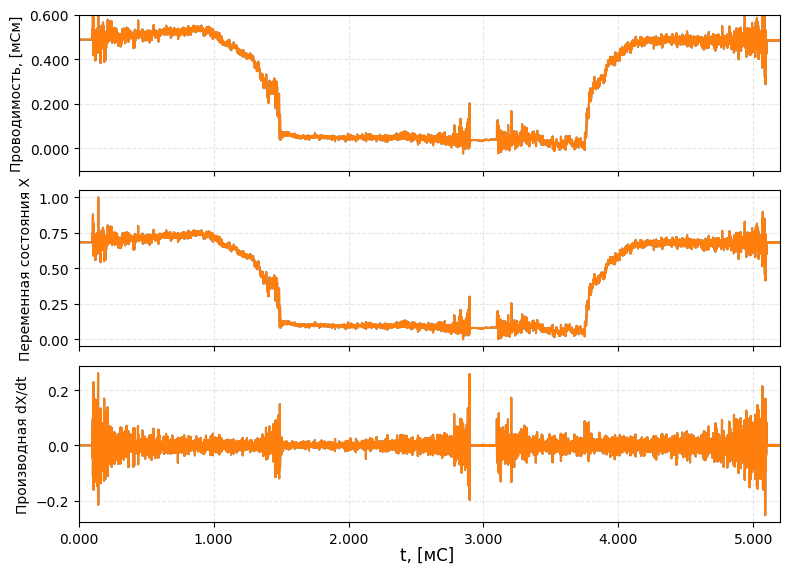

In [624]:
set_inline_backend()

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(8, 6), sharex=True)

# ax1.plot(T, G_m, label='raw $G_m(t)$')

ax1.plot(T, G_m_filtered, label='Auto: filtered $G_m(t)$')
ax2.plot(T, G_m_normalized)
ax3.plot(T, G_m_normalized_diff)

ax1.plot(T, G_m_manual_filtered, label='Manual: filtered $G_m(t)$')
ax2.plot(T, G_m_manual_normalized)
ax3.plot(T, G_m_manual_normalized_diff)

# ax1.legend(loc="lower right", fontsize="medium")

for ax in [ax1, ax2, ax3]:
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.set_xlim(T[0], T[-1])

ax1.set_ylim(-0.1e-3, 0.6e-3)
ax1.yaxis.set_major_formatter(formatter_to_mSm)

ax1.set_ylabel("Проводимость, [мСм]")
ax2.set_ylabel("Переменная состояния X")
ax3.set_ylabel("Производная dX/dt")

fig.supxlabel('t, [мС]', x=0.54, y=0.05)
fig.gca().xaxis.set_major_formatter(formatter_to_mS)

plt.tight_layout()
plt.show()

# Анализ полных данных

In [23]:
n_rows = min(count_rows(PATH_TO_IN), count_rows(PATH_TO_OUT))

arr_v = read_data(PATH_TO_IN, max_rows=n_rows)
arr_i = read_data_writable(PATH_TO_OUT, max_rows=n_rows, n_chunk_rows=100_000)
arr_i /= R

print(f"Input length: {len(arr_v)}")
print(f"Output length: {len(arr_i)}")

Input length: 60026492
Output length: 60026492


In [24]:
N = len(arr_v)
print(f"Time range (seconds): [0; {(N - 1) * dt}]")

Time range (seconds): [0; 60.026491]


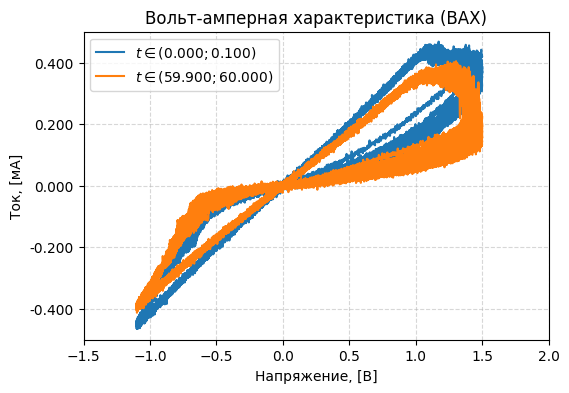

In [27]:
set_inline_backend()
fig, ax = plt.subplots(figsize=(6, 4))

t_start = [0, 59.9]
t_end   = [0.1, 60]
for i, (t_start, t_end) in enumerate(zip(t_start, t_end)):
    start_idx   = int(t_start // dt)
    end_idx     = int(t_end // dt)

    label = fr"$t \in ({t_start:.3f}; {t_end:.3f})$"
    plot_curve(ax, arr_v[start_idx:end_idx + 1], arr_i[start_idx:end_idx + 1], label=label, color=f"C{i}")

ax.set(title="Вольт-амперная характеристика (ВАХ)", xlabel="Напряжение, [В]", ylabel="Ток, [мА]")
ax.set_xlim(-1.5, 2.0)
ax.set_ylim(-0.0005, 0.0005)
ax.yaxis.set_major_formatter(formatter_to_mA)
ax.legend()
plt.show()